# 03 — Model experiments

**Mục tiêu:** so sánh các họ model, tuning và feature engineering bằng 3-fold CV cố định trên train, rồi chốt cấu hình bàn giao notebook 04. Đơn vị MAE/RMSE: tỷ VND. Báo cáo cả MAE, RMSE và R²; mục tiêu dự án đo bằng R². Notebook này không mở calibration; test chỉ được mở **một lần ở C67** (theo quyết định của nhóm ngày 2026-10-20) để đánh giá cấu hình đã khóa.

**Hai phần:**
- **Phần A (C01–C47) — `splits_v1`.** Frontage/Access Road trong v1 đã được điền median theo District **trên toàn bộ dữ liệu trước khi chia tập** (C52 xác nhận). Kết quả giữ làm lịch sử và mốc so sánh.
- **Phần B (C52–C66) — `splits_v2`**, làm lại theo góp ý của người review: cùng dòng và cùng thứ tự như v1, Frontage/Access Road trở về giá trị gốc còn missing, mọi bước điền thiếu học trong từng fold. **Lựa chọn cuối nằm ở Phần B.**

**Môi trường:** kernel `.venv` của project; phiên bản thư viện in ở C01 (numpy 2.5.3, pandas 3.0.6, scikit-learn 1.9.1, catboost 1.2.10, xgboost 3.4.1, lightgbm 4.7.0). Import chỉ ở C01; không cài thư viện trong cell experiment.

| Nhóm | Cell | Nội dung |
|---|---|---|
| Thiết lập | C01–C03, S01–S02 | Imports, split, feature, preprocessing, 3 fold cố định, cấu hình boosting |
| A · Thăm dò trên validation | C04–C21 | RF, phân tích lỗi RF, chuẩn hóa địa phương, missing, tuyến tính, boosting |
| A · RF Grid Search | C22–C25 | 144 cấu hình, 3-fold CV |
| A · So sánh bằng CV | C26–C30 | Ridge, LightGBM, XGBoost, CatBoost trên cùng fold |
| A · Grid Search lượt 1 | C31–C39 | LightGBM (C31–C33), XGBoost (C34–C36), CatBoost (C37–C39) |
| A · Khôi phục | R01–R04 | Đọc kết quả CV từ file, cấu hình tốt nhất, hàm lưu tiến độ |
| A · Feature engineering, tuning lượt 2 | C40–C47 | City_District, target encoding, feature số; grid lượt 2 + kiểm tra 3 seed |
| B · Dữ liệu | C52–C54 | Nguồn gốc `_v1.csv`, chuyển sang v2, phường/dự án từ Address, preprocessing v2 |
| B · Missing | C55 | Median trong fold, chỉ báo thiếu, để model tự xử lý |
| B · Phân tích lỗi XGBoost | C56–C57a | Lỗi theo nhóm, mẫu sai nhiều, tin đăng trùng, rà soát giá nghi sai đơn vị |
| B · Feature theo giả thuyết | C58–C59a | Vị trí (City_District, phường, dự án, đường, Area × vị trí) và căn nhà (Area × Floors, mật độ phòng, log Area) |
| B · Metric | C60–C61 | Chọn theo MAE so với RMSE/R²; early stopping RMSE; log-price |
| B · Chốt cấu hình | C62–C66 | Cấu hình cuối, ensemble OOF, fit toàn bộ train, validation, giải thích, lưu lựa chọn |
| Test | C67 | Đánh giá test chính thức, một lần, cấu hình đã khóa |
| Xuất model | C68 | Lưu ensemble đã khóa ra `.pkl` trong `models/candidates/final_v2_2026-10-20/`, kiểm tra nạp lại |

**Chuẩn bị dữ liệu v2 (một lần):** `splits_v2` được tạo bằng script của nhóm, script này tái lập công thức làm sạch và chỉ trả hai cột Frontage/Access Road về giá trị gốc:

```
.venv/Scripts/python models/candidates/milestone_v2_r2_2026-10-16/src/preprocessing/repair_input_v2.py --project-root .
```

**Cách chạy:**
1. **Mở lại phiên (nhanh, không chạy lại grid):** C01 → C02 → C03 → S01 → S02 → R01 → R02 → R03 → R04 → C40 → … → C47 → C52 → … → C57 → C57a → C58 → C59 → C59a → C60 → … → C66. Mọi experiment từ C42 lưu từng fold trong `experiments/` (Phần B trong `experiments/v2/`); chạy lại sẽ đọc fold đã có thay vì train. Chỉ C64–C65 fit lại hai model cuối (vài phút).
2. **Chạy lại phần validation và CV ban đầu của Phần A:** C01 → C23, C26 → C30.
3. **Không dùng Run All.** C24, C32, C35, C38 là các grid chạy hàng giờ (RF khoảng 2,5 giờ; CatBoost khoảng 5 giờ); kết quả đã lưu và được C33, C36, C39, R01 đọc lại.

**Trạng thái output:** ngày 2026-10-20 có hai lần chạy bằng kernel `.venv`. Lần 1 thực thi mọi code cell theo thứ tự trừ C24, C25, C32, C35, C38 (output của năm cell này giữ từ lần chạy gốc). Lần 2, sau khi thêm feature đường (C59a) và rà soát đơn vị (C57a), chạy lại theo cách 1 ở trên; output C04–C39 vẫn là của lần 1. Vì vậy số execution không liên tục giữa hai phần. C38 đã chạy xong nhưng kernel bị crash ngay sau đó; C39 đọc lại 81 dòng kết quả từ file.

**Phụ thuộc:** chạy từ trên xuống. Từ C53, các biến `train_df`, `X_train`, `y_train`, `X_val`, `y_val`, `split_fingerprints` là của `splits_v2`. Output đã lưu không thay thế biến trong kernel.

Các nhận xét Markdown ở phần 1–6 là **ghi nhận lịch sử trước khi dọn**; bảng của lần chạy mới là bằng chứng để đối chiếu. Không diễn giải một experiment là tối ưu toàn cục. Đánh số cell: hướng dẫn ghi “notebook 03, C13”, không dùng số execution `[n]`. Thí nghiệm mới tiếp theo bắt đầu từ C69; ô chèn giữa dùng hậu tố chữ (C57a), giống quy ước notebook 01.

In [1]:
# C01 — Imports và phiên bản môi trường
from pathlib import Path
from itertools import product
from time import perf_counter
from copy import deepcopy
from importlib.metadata import version
import hashlib
import json
import pickle
import subprocess
import sys
import re
import unicodedata
import warnings

import numpy as np
import pandas as pd
from scipy import sparse
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import GridSearchCV, KFold, ParameterGrid, cross_validate
from sklearn.base import clone, BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer, TargetEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge, ElasticNet
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import catboost
from catboost import CatBoostRegressor
import xgboost
from xgboost import XGBRegressor
import lightgbm as lgb
import cloudpickle
from sklearn.model_selection import train_test_split

environment_versions = {
    package: version(package)
    for package in ['numpy', 'pandas', 'scikit-learn', 'catboost', 'xgboost', 'lightgbm']
}
display(pd.Series(environment_versions, name='version').to_frame())

,version
numpy,2.5.3
pandas,3.0.6
scikit-learn,1.9.1
catboost,1.2.10
xgboost,3.4.1
lightgbm,4.7.0


In [2]:
# C02 — Đọc train/validation đã cố định
PROJECT_ROOT = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (
            folder / "data" / "processed"
            / "splits_v1" / "train.csv"
        ).is_file()
        and (folder / "notebooks").is_dir()
    ),
    None,
)
assert PROJECT_ROOT is not None, "Mở kernel trong project hoặc notebooks."

SPLIT_DIR = PROJECT_ROOT / "data" / "processed" / "splits_v1"
SEED = 42
TARGET = "Price"

train_df = pd.read_csv(SPLIT_DIR / "train.csv")
val_df = pd.read_csv(SPLIT_DIR / "validation.csv")

assert train_df["row_id"].is_unique
assert val_df["row_id"].is_unique
assert set(train_df["row_id"]).isdisjoint(val_df["row_id"])
assert (len(train_df), len(val_df)) == (18136, 4535)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
# Nhận diện chính xác phiên bản split, không đọc calibration/test.
split_fingerprints = {
    name: hashlib.sha256((SPLIT_DIR / f'{name}.csv').read_bytes()).hexdigest()
    for name in ['train', 'validation']
}
display(pd.Series(split_fingerprints, name='sha256').to_frame())


Train: (18136, 14)
Validation: (4535, 14)


,sha256
train,047f4f8d482f98f1fb2ee397cc51fa41e45b76409cc7f1...
validation,f864ac624a35010b627eb5ec8e223f6390f90c76eb2922...


In [3]:
# C03 — Feature, preprocessing, metrics và hàm chạy RF
FEATURES = [
    "Area", "Frontage", "Access Road",
    "House direction", "Balcony direction",
    "Floors", "Bedrooms", "Bathrooms",
    "Legal status", "Furniture state", "City", "District",
]

NUMERIC_FEATURES = [
    "Area", "Frontage", "Access Road",
    "Floors", "Bedrooms", "Bathrooms",
]
CATEGORICAL_FEATURES = [
    "House direction", "Balcony direction",
    "Legal status", "Furniture state", "City", "District",
]

for part in [train_df, val_df]:
    assert set(part.columns) == set(FEATURES + [TARGET, "row_id"])
    assert part[TARGET].notna().all()

X_train = train_df[FEATURES].copy()
y_train = train_df[TARGET].copy()
X_val = val_df[FEATURES].copy()
y_val = val_df[TARGET].copy()

preprocessor = ColumnTransformer([
    (
        "num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]),
        NUMERIC_FEATURES,
    ),
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]),
        CATEGORICAL_FEATURES,
    ),
])

# Ghi rõ các tham số để tái lập baseline.
BASE_RF_PARAMS = {
    "n_estimators": 100,
    "max_depth": None,
    "min_samples_leaf": 1,
    "min_samples_split": 2,
    "max_features": 1.0,
    "random_state": SEED,
    "n_jobs": -1,
}


def evaluate(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "R2": r2_score(y_true, y_pred),
    }


def run_rf(name, changes):
    params = {**BASE_RF_PARAMS, **changes}
    pipeline = Pipeline([
        # Mỗi model có preprocessing riêng.
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestRegressor(**params)),
    ])

    start = perf_counter()
    pipeline.fit(X_train, y_train)
    fit_seconds = perf_counter() - start

    train_metrics = evaluate(y_train, pipeline.predict(X_train))
    val_metrics = evaluate(y_val, pipeline.predict(X_val))

    return {
        "experiment": name,
        **params,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "MAE_gap": val_metrics["MAE"] - train_metrics["MAE"],
        "fit_seconds": fit_seconds,
    }
# Kiểm tra đầu vào chung trước mọi experiment.
assert TARGET not in FEATURES and 'row_id' not in FEATURES
assert X_train.index.equals(y_train.index)
assert X_val.index.equals(y_val.index)
assert np.isfinite(y_train.to_numpy()).all()
assert np.isfinite(y_val.to_numpy()).all()
assert y_train.gt(0).all() and y_val.gt(0).all()
for frame in [X_train, X_val]:
    assert all(pd.api.types.is_numeric_dtype(frame[c]) for c in NUMERIC_FEATURES)
    assert not np.isinf(frame[NUMERIC_FEATURES].to_numpy(dtype=float)).any()
assert X_train[FEATURES].notna().any().all(), 'Có cột train hoàn toàn thiếu.'


def normalize_location_name(value):
    """Chuẩn hóa định dạng địa phương; giữ nguyên missing."""
    if pd.isna(value):
        return value

    text = unicodedata.normalize("NFC", str(value))
    text = re.sub(r"\s+", " ", text).strip()
    text = text.rstrip(".").strip()

    # Không âm thầm chuyển tên chỉ gồm dấu câu thành missing.
    return text


def normalize_location_frame(X):
    # Copy để không sửa X_train/X_val hoặc dữ liệu gốc.
    result = X.copy()

    for column in ["City", "District"]:
        result[column] = result[column].map(
            normalize_location_name
        )

        assert not result[column].eq("").fillna(False).any(), (
            f"{column}: chuẩn hóa tạo tên rỗng; cần kiểm tra."
        )

    return result



In [4]:
# S01 — Pipeline CV và fold cố định
assert "X_train" in globals(), "Chạy C01–C03 trước."

# Dựng từ thiết lập chung; không phụ thuộc model đã fit ở C13.
rf_grid_preprocessor = clone(preprocessor)
rf_grid_preprocessor.set_params(num=Pipeline([
    ("scaler", StandardScaler()),
    ("imputer", SimpleImputer(strategy="mean")),
]))
rf_grid_pipeline = Pipeline([
    ("normalize_location", FunctionTransformer(normalize_location_frame, validate=False)),
    ("preprocessor", rf_grid_preprocessor),
    ("model", RandomForestRegressor(**{**BASE_RF_PARAMS, "max_features": 0.7})),
])
rf_cv = KFold(n_splits=3, shuffle=True, random_state=42)
rf_cv_splits = list(rf_cv.split(X_train, y_train))
held_out_counts = np.zeros(len(X_train), dtype=int)
for fit_idx, held_out_idx in rf_cv_splits:
    assert set(fit_idx).isdisjoint(held_out_idx)
    held_out_counts[held_out_idx] += 1
assert (held_out_counts == 1).all()

EXPERIMENT_DIR = PROJECT_ROOT / "experiments"
MODEL_CV_DIR = EXPERIMENT_DIR / "model_comparison_cv"
if "model_cv_registry" not in globals():
    model_cv_registry = {}


def check_grid_results(results, candidates):
    """Kết quả grid đọc từ file phải đủ fold và đúng tham số theo candidate_id."""
    assert len(results) == len(candidates) * len(rf_cv_splits)
    assert not results.duplicated(["candidate_id", "fold"]).any()
    for candidate_id, rows in results.groupby("candidate_id"):
        assert set(rows["fold"]) == set(range(1, len(rf_cv_splits) + 1))
        for key, value in candidates[candidate_id - 1].items():
            assert rows[key].eq(value).all(), (candidate_id, key)


print("Đã dựng pipeline và 3 fold; chưa train model.")

Đã dựng pipeline và 3 fold; chưa train model.


In [5]:
# S02 — Cấu hình boosting và preprocessing
assert "rf_grid_pipeline" in globals(), "Chạy S01 trước."

lgb_cv_params = {
    "objective": "regression",
    "metric": "mae",
    "n_estimators": 3000,
    "learning_rate": 0.05,
    "num_leaves": 31,
    "max_depth": 6,
    "min_child_samples": 20,
    "subsample": 1.0,
    "colsample_bytree": 1.0,
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": -1,
}

# Lấy các bước preprocessing, bỏ estimator RF.
lgb_preprocessing_template = Pipeline([
    (name, clone(step))
    for name, step in rf_grid_pipeline.steps[:-1]
])


xgb_cv_params = {
    "n_estimators": 3000,
    "max_depth": 6,
    "learning_rate": 0.05,
    "objective": "reg:squarederror",
    "eval_metric": "mae",
    "tree_method": "hist",
    "subsample": 1.0,
    "colsample_bytree": 1.0,
    "random_state": 42,
    "n_jobs": -1,
}

xgb_preprocessing_template = Pipeline([
    (name, clone(step))
    for name, step in rf_grid_pipeline.steps[:-1]
])


cb_cv_params = {
    "iterations": 3000,
    "depth": 6,
    "learning_rate": 0.05,
    "loss_function": "RMSE",
    "eval_metric": "MAE",
    "random_seed": 42,
    "task_type": "CPU",
    "allow_writing_files": False,
}


def prepare_cb_fold(X_fit, X_apply):
    """Học imputer từ X_fit, chỉ transform X_apply."""
    fit_frame = normalize_location_frame(X_fit)
    apply_frame = normalize_location_frame(X_apply)

    assert fit_frame[FEATURES].notna().any().all(), (
        "Có feature hoàn toàn thiếu trong phần fit."
    )

    numeric_imputer = SimpleImputer(strategy="median")
    category_imputer = SimpleImputer(strategy="most_frequent")

    fit_frame[NUMERIC_FEATURES] = numeric_imputer.fit_transform(
        fit_frame[NUMERIC_FEATURES]
    )
    apply_frame[NUMERIC_FEATURES] = numeric_imputer.transform(
        apply_frame[NUMERIC_FEATURES]
    )

    fit_frame[CATEGORICAL_FEATURES] = (
        category_imputer.fit_transform(
            fit_frame[CATEGORICAL_FEATURES]
        )
    )
    apply_frame[CATEGORICAL_FEATURES] = (
        category_imputer.transform(
            apply_frame[CATEGORICAL_FEATURES]
        )
    )

    for column in CATEGORICAL_FEATURES:
        assert fit_frame[column].notna().all()
        assert apply_frame[column].notna().all()

        fit_frame[column] = fit_frame[column].astype(str)
        apply_frame[column] = apply_frame[column].astype(str)

    assert list(fit_frame.columns) == list(apply_frame.columns)
    return fit_frame, apply_frame



print("Đã khai báo cấu hình và preprocessing boosting; chưa train model.")


Đã khai báo cấu hình và preprocessing boosting; chưa train model.


## 1. RF — thử cấu hình và seed

| Cell | Câu hỏi | Ghi nhận lịch sử |
|---|---|---|
| C04 | Giảm depth/tăng leaf có giảm MAE? | 9 cấu hình; không vượt baseline theo MAE |
| C05 | Thay max_features có lợi không? | 0.7 ở depth=None giảm MAE nhẹ; 0.4 không tốt hơn |
| C06 | Lợi ích có giữ qua seed model? | Thắng 3/3 seed, MAE trung bình giảm khoảng 0.244% |

Giữ split; chỉ thay seed model ở C06. Gap nhỏ chưa đủ để chọn model. Kết quả 3 seed không tương đương CV. Tạm dừng tuning RF, giữ model làm đối chứng cho preprocessing.

In [6]:
# C04 — Experiment 01: 9 cấu hình RF
experiment_rows = []

for depth, leaf in product([None, 15, 25], [1, 3, 5]):
    is_baseline = depth is None and leaf == 1
    name = (
        "RF_baseline"
        if is_baseline
        else f"RF_depth_{depth}_leaf_{leaf}"
    )

    result = run_rf(
        name,
        {
            "max_depth": depth,
            "min_samples_leaf": leaf,
        },
    )
    experiment_rows.append(result)

    print(
        f"{name}: "
        f"val MAE={result['val_MAE']:.4f}, "
        f"val R2={result['val_R2']:.4f}"
    )

results_exp01 = pd.DataFrame(experiment_rows)

baseline_mae = results_exp01.loc[
    results_exp01["experiment"].eq("RF_baseline"), "val_MAE"
].iloc[0]

# Số dương nghĩa là MAE giảm so với baseline.
results_exp01["MAE_improvement_pct"] = (
    (baseline_mae - results_exp01["val_MAE"])
    / baseline_mae * 100
)

results_exp01 = results_exp01.sort_values(
    "val_MAE"
).reset_index(drop=True)

display(
    results_exp01[[
        "experiment",
        "train_MAE", "val_MAE", "MAE_gap",
        "train_RMSE", "val_RMSE",
        "train_R2", "val_R2",
        "MAE_improvement_pct", "fit_seconds",
    ]].round(4)
)

RF_baseline: val MAE=1.0239, val R2=0.5982


RF_depth_None_leaf_3: val MAE=1.0383, val R2=0.5959


RF_depth_None_leaf_5: val MAE=1.0650, val R2=0.5825


RF_depth_15_leaf_1: val MAE=1.0838, val R2=0.5762


RF_depth_15_leaf_3: val MAE=1.0867, val R2=0.5733


RF_depth_15_leaf_5: val MAE=1.1004, val R2=0.5636


RF_depth_25_leaf_1: val MAE=1.0245, val R2=0.6048


RF_depth_25_leaf_3: val MAE=1.0398, val R2=0.5966


RF_depth_25_leaf_5: val MAE=1.0659, val R2=0.5827


,experiment,train_MAE,val_MAE,MAE_gap,train_RMSE,val_RMSE,train_R2,val_R2,MAE_improvement_pct,fit_seconds
0,RF_baseline,0.4031,1.0239,0.6208,0.5646,1.3881,0.9350,0.5982,0.0000,28.3282
1,RF_depth_25_leaf_1,0.5532,1.0245,0.4712,0.7480,1.3767,0.8859,0.6048,-0.0531,20.5734
2,RF_depth_None_leaf_3,0.6783,1.0383,0.3599,0.9205,1.3921,0.8271,0.5959,-1.3988,14.8724
3,RF_depth_25_leaf_3,0.7221,1.0398,0.3177,0.9702,1.3908,0.8080,0.5966,-1.5526,13.8406
4,RF_depth_None_leaf_5,0.8201,1.0650,0.2449,1.0937,1.4150,0.7560,0.5825,-4.0127,11.5653
5,RF_depth_25_leaf_5,0.8342,1.0659,0.2317,1.1096,1.4146,0.7488,0.5827,-4.0955,11.6252
6,RF_depth_15_leaf_1,0.8870,1.0838,0.1968,1.1647,1.4257,0.7233,0.5762,-5.8485,11.1242
7,RF_depth_15_leaf_3,0.9353,1.0867,0.1513,1.2253,1.4304,0.6937,0.5733,-6.1300,8.9061
8,RF_depth_15_leaf_5,0.9767,1.1004,0.1237,1.2757,1.4466,0.6680,0.5636,-7.4690,8.2731


In [7]:
# C05 — Experiment 02: max_features
assert "results_exp01" in globals(), "Chạy C04 trước."

experiment_rows_02 = []

# Hai kết quả đối chứng đã có, cùng thiết lập.
controls = [
    ("RF_baseline", None),
    ("RF_depth_25_leaf_1", 25),
]

for control_name, depth in controls:
    control = results_exp01.loc[
        results_exp01["experiment"].eq(control_name)
    ]
    assert len(control) == 1, f"Không tìm thấy đúng một {control_name}"

    control_row = control.iloc[0].to_dict()
    assert control_row["max_features"] == 1.0
    assert control_row["min_samples_leaf"] == 1

    # Chỉ giữ lại kết quả/config gốc, tính lại phần so sánh bên dưới.
    control_row.pop("MAE_improvement_pct", None)
    control_row["result_source"] = "reused_exp01"
    control_row["depth_group"] = (
        "unlimited" if depth is None else str(depth)
    )
    experiment_rows_02.append(control_row)

    for max_features in [0.7, 0.4]:
        name = f"RF_depth_{depth}_leaf_1_mf_{max_features}"

        result = run_rf(
            name,
            {
                "max_depth": depth,
                "min_samples_leaf": 1,
                "max_features": max_features,
            },
        )

        result["result_source"] = "new_exp02"
        result["depth_group"] = (
            "unlimited" if depth is None else str(depth)
        )
        experiment_rows_02.append(result)

        print(
            f"{name}: "
            f"val MAE={result['val_MAE']:.4f}, "
            f"val RMSE={result['val_RMSE']:.4f}, "
            f"val R2={result['val_R2']:.4f}"
        )

results_exp02 = pd.DataFrame(experiment_rows_02)

# So sánh với RF baseline ban đầu.
baseline_mae = results_exp02.loc[
    results_exp02["experiment"].eq("RF_baseline"), "val_MAE"
].iloc[0]

results_exp02["gain_vs_baseline_pct"] = (
    (baseline_mae - results_exp02["val_MAE"])
    / baseline_mae * 100
)

# So sánh với model có cùng depth nhưng max_features=1.0.
control_mae_by_depth = (
    results_exp02.loc[results_exp02["max_features"].eq(1.0)]
    .set_index("depth_group")["val_MAE"]
)

same_depth_mae = results_exp02["depth_group"].map(
    control_mae_by_depth
)

results_exp02["gain_vs_same_depth_pct"] = (
    (same_depth_mae - results_exp02["val_MAE"])
    / same_depth_mae * 100
)

results_exp02 = results_exp02.sort_values(
    "val_MAE"
).reset_index(drop=True)

display(
    results_exp02[[
        "experiment",
        "max_features",
        "train_MAE", "val_MAE", "MAE_gap",
        "val_RMSE", "train_R2", "val_R2",
        "gain_vs_baseline_pct",
        "gain_vs_same_depth_pct",
        "fit_seconds",
        "result_source",
    ]].round(4)
)

RF_depth_None_leaf_1_mf_0.7: val MAE=1.0220, val RMSE=1.3815, val R2=0.6020


RF_depth_None_leaf_1_mf_0.4: val MAE=1.0318, val RMSE=1.3845, val R2=0.6003


RF_depth_25_leaf_1_mf_0.7: val MAE=1.0308, val RMSE=1.3760, val R2=0.6052


RF_depth_25_leaf_1_mf_0.4: val MAE=1.0348, val RMSE=1.3717, val R2=0.6077


,experiment,max_features,train_MAE,val_MAE,MAE_gap,val_RMSE,train_R2,val_R2,gain_vs_baseline_pct,gain_vs_same_depth_pct,fit_seconds,result_source
0,RF_depth_None_leaf_1_mf_0.7,0.7,0.4028,1.0220,0.6192,1.3815,0.9356,0.6020,0.1873,0.1873,22.1779,new_exp02
1,RF_baseline,1.0,0.4031,1.0239,0.6208,1.3881,0.9350,0.5982,0.0000,0.0000,28.3282,reused_exp01
2,RF_depth_25_leaf_1,1.0,0.5532,1.0245,0.4712,1.3767,0.8859,0.6048,-0.0531,0.0000,20.5734,reused_exp01
3,RF_depth_25_leaf_1_mf_0.7,0.7,0.5640,1.0308,0.4667,1.3760,0.8822,0.6052,-0.6676,-0.6141,16.6713,new_exp02
4,RF_depth_None_leaf_1_mf_0.4,0.4,0.4055,1.0318,0.6263,1.3845,0.9358,0.6003,-0.7667,-0.7667,14.9483,new_exp02
5,RF_depth_25_leaf_1_mf_0.4,0.4,0.5865,1.0348,0.4483,1.3717,0.8746,0.6077,-1.0612,-1.0075,10.8107,new_exp02


In [8]:
# C06 — So sánh hai cấu hình RF qua ba seed model
assert "results_exp02" in globals(), "Chạy C05 trước."

MODEL_SEEDS = [42, 123, 2026]

configs = {
    "baseline": {
        "max_features": 1.0,
        "previous_name": "RF_baseline",
    },
    "candidate": {
        "max_features": 0.7,
        "previous_name": "RF_depth_None_leaf_1_mf_0.7",
    },
}

stability_rows = []

for seed in MODEL_SEEDS:
    for config_name, config in configs.items():

        if seed == 42:
            # Tái sử dụng kết quả đã chạy ở cùng thiết lập.
            previous = results_exp02.loc[
                results_exp02["experiment"].eq(
                    config["previous_name"]
                )
            ]
            assert len(previous) == 1

            result = previous.iloc[0].to_dict()

            assert result["random_state"] == 42
            assert pd.isna(result["max_depth"])
            assert result["min_samples_leaf"] == 1
            assert result["min_samples_split"] == 2
            assert result["n_estimators"] == 100
            assert result["max_features"] == config["max_features"]

            source = "reused_seed_42"

        else:
            result = run_rf(
                name=f"{config_name}_seed_{seed}",
                changes={
                    "max_depth": None,
                    "min_samples_leaf": 1,
                    "min_samples_split": 2,
                    "n_estimators": 100,
                    "max_features": config["max_features"],
                    "random_state": seed,
                },
            )
            source = "new_run"

        stability_rows.append({
            "config": config_name,
            "seed": seed,
            "max_features": config["max_features"],
            "train_MAE": result["train_MAE"],
            "val_MAE": result["val_MAE"],
            "val_RMSE": result["val_RMSE"],
            "val_R2": result["val_R2"],
            "source": source,
        })

        print(
            f"{config_name} | seed={seed} | "
            f"val MAE={result['val_MAE']:.6f}"
        )

stability_results = pd.DataFrame(stability_rows)

# So sánh cặp: hai cấu hình dùng cùng seed.
paired_mae = stability_results.pivot(
    index="seed",
    columns="config",
    values="val_MAE",
)
paired_mae.columns.name = None

# Số dương = ứng viên giảm MAE so với baseline.
paired_mae["MAE_reduction"] = (
    paired_mae["baseline"] - paired_mae["candidate"]
)
paired_mae["improvement_pct"] = (
    paired_mae["MAE_reduction"]
    / paired_mae["baseline"] * 100
)

summary = stability_results.groupby("config").agg(
    mean_val_MAE=("val_MAE", "mean"),
    std_val_MAE=("val_MAE", "std"),
    mean_val_RMSE=("val_RMSE", "mean"),
    mean_val_R2=("val_R2", "mean"),
)

print("\nSo sánh MAE theo từng seed — đơn vị tỷ VND:")
display(paired_mae.round(6))

print("\nTổng hợp qua ba seed:")
display(summary.round(6))

wins = int((paired_mae["MAE_reduction"] > 0).sum())
mean_reduction = paired_mae["MAE_reduction"].mean()

print(f"\nỨng viên thắng ở {wins}/{len(MODEL_SEEDS)} seed.")
print(
    "Mức giảm MAE trung bình: "
    f"{mean_reduction:.6f} tỷ VND "
    f"({mean_reduction * 1000:.3f} triệu VND)."
)

baseline | seed=42 | val MAE=1.023930
candidate | seed=42 | val MAE=1.022013


baseline | seed=123 | val MAE=1.031803


candidate | seed=123 | val MAE=1.027177


baseline | seed=2026 | val MAE=1.026737


candidate | seed=2026 | val MAE=1.025775

So sánh MAE theo từng seed — đơn vị tỷ VND:


,baseline,candidate,MAE_reduction,improvement_pct
seed,,,,
42,1.023930,1.022013,0.001917,0.187261
123,1.031803,1.027177,0.004626,0.448351
2026,1.026737,1.025775,0.000962,0.093702



Tổng hợp qua ba seed:


,mean_val_MAE,std_val_MAE,mean_val_RMSE,mean_val_R2
config,,,,
baseline,1.027490,0.00399,1.391885,0.596013
candidate,1.024988,0.00267,1.384457,0.600315



Ứng viên thắng ở 3/3 seed.
Mức giảm MAE trung bình: 0.002502 tỷ VND (2.502 triệu VND).


## 2. Phân tích lỗi và chuẩn hóa địa phương

| Cell | Công việc | Ghi nhận lịch sử |
|---|---|---|
| C07 | Lỗi theo giá, diện tích, City/District | Giá thấp thường dự đoán cao, giá cao thường dự đoán thấp; đây chưa phải chứng minh nguyên nhân |
| C08 | Kiểm tra mapping trên train | 509 dòng đổi City; 94 → 68 category City; District không đổi |
| C09 | RF trước/sau chuẩn hóa | MAE 1.022013 → 1.021221; lợi ích rõ ở nhóm đổi tên, nhỏ trên toàn validation |

Không xóa dòng hoặc sửa Price vì model sai nhiều. Chuẩn hóa NFC, khoảng trắng, dấu chấm cuối; giữ missing. Nhóm giá thật chỉ dùng phân tích lỗi, không đưa vào feature. Ngưỡng 30 mẫu chỉ hỗ trợ đọc bảng. Mapping đầy đủ vẫn ở city_merges/district_merges; màn hình chỉ rút gọn hiển thị.

In [9]:
# C07 — Fit RF đã chọn và phân tích lỗi validation

selected_rf = Pipeline([
    ("preprocessor", clone(preprocessor)),
    (
        "model",
        RandomForestRegressor(
            n_estimators=100,
            max_depth=None,
            min_samples_leaf=1,
            min_samples_split=2,
            max_features=0.7,
            random_state=42,
            n_jobs=-1,
        ),
    ),
])

selected_rf.fit(X_train, y_train)
selected_val_pred = selected_rf.predict(X_val)

print("Metrics validation:")
display(
    pd.DataFrame([
        evaluate(y_val, selected_val_pred)
    ]).round(6)
)

# Kiểm tra thứ tự trước khi ghép thông tin và dự đoán.
assert X_val.index.equals(val_df.index)
assert y_val.index.equals(val_df.index)

error_df = val_df[
    ["row_id", "Area", "City", "District"]
].copy()

error_df["actual_price"] = y_val.to_numpy()
error_df["predicted_price"] = selected_val_pred
error_df["error"] = (
    error_df["predicted_price"] - error_df["actual_price"]
)
error_df["abs_error"] = error_df["error"].abs()

# Nhãn thiếu để các dòng này vẫn xuất hiện khi groupby.
for column in ["City", "District"]:
    error_df[column] = error_df[column].fillna("Unknown")

# Ngưỡng cố định để dễ diễn giải.
# right=False: lấy cận trái, không lấy cận phải.
error_df["price_group"] = pd.cut(
    error_df["actual_price"],
    bins=[-float("inf"), 3, 5, 7, 9, float("inf")],
    labels=["<3", "3–<5", "5–<7", "7–<9", "≥9"],
    right=False,
)

error_df["area_group"] = pd.cut(
    error_df["Area"],
    bins=[-float("inf"), 50, 80, 120, 200, float("inf")],
    labels=["<50", "50–<80", "80–<120", "120–<200", "≥200"],
    right=False,
)

# Ngưỡng hỗ trợ đọc bảng, không phải bảo đảm thống kê.
MIN_GROUP_SIZE = 30


def summarize_errors(frame, group_columns):
    table = (
        frame.groupby(
            group_columns,
            observed=True,
            dropna=False,
        )
        .agg(
            n=("abs_error", "size"),
            mean_actual_price=("actual_price", "mean"),
            MAE=("abs_error", "mean"),
            bias=("error", "mean"),
            total_abs_error=("abs_error", "sum"),
        )
        .reset_index()
    )

    total_error = frame["abs_error"].sum()
    table["error_share_pct"] = (
        table["total_abs_error"] / total_error * 100
        if total_error > 0 else 0.0
    )

    table["small_group"] = table["n"] < MIN_GROUP_SIZE
    return table.drop(columns="total_abs_error")


price_errors = summarize_errors(error_df, ["price_group"])
area_errors = summarize_errors(error_df, ["area_group"])
city_errors = summarize_errors(error_df, ["City"])

# Dùng City + District để tránh gộp quận/huyện trùng tên.
district_errors = summarize_errors(
    error_df, ["City", "District"]
)

print("\n1. Lỗi theo nhóm giá thật — tỷ VND:")
display(price_errors.round(4))

print("\n2. Lỗi theo nhóm diện tích — m²:")
display(area_errors.round(4))

print("\n3. Lỗi theo thành phố:")
display(
    city_errors.sort_values("MAE", ascending=False).round(4)
)

print("\n4. Các quận/huyện MAE cao nhất, có ít nhất 30 mẫu:")
display(
    district_errors.loc[
        ~district_errors["small_group"]
    ]
    .sort_values("MAE", ascending=False)
    .head(15)
    .round(4)
)

print(
    "Số nhóm quận/huyện dưới 30 mẫu:",
    int(district_errors["small_group"].sum()),
)

print("\n5. Mười trường hợp sai nhiều nhất:")
display(
    error_df.sort_values("abs_error", ascending=False)[[
        "row_id", "City", "District", "Area",
        "actual_price", "predicted_price",
        "error", "abs_error",
    ]]
    .head(10)
    .round(4)
)

Metrics validation:


,MAE,RMSE,R2
0,1.022013,1.381541,0.601998



1. Lỗi theo nhóm giá thật — tỷ VND:


,price_group,n,mean_actual_price,MAE,bias,error_share_pct,small_group
0,<3,494,2.2270,1.1796,1.1401,12.5727,False
1,3–<5,1126,4.0619,0.9265,0.6743,22.5079,False
2,5–<7,1439,6.0054,0.8030,0.2192,24.9302,False
3,7–<9,1045,7.9231,1.0201,-0.7850,22.9993,False
4,≥9,431,9.5120,1.8270,-1.8233,16.9898,False



2. Lỗi theo nhóm diện tích — m²:


...

,City,n,mean_actual_price,MAE,bias,error_share_pct,small_group
55,Điện Biên,1,1.5600,4.5946,4.5946,0.0991,True
31,Lạng Sơn,1,3.3900,3.8818,3.8818,0.0838,True
40,Quảng Ngãi,2,2.7000,2.4912,2.4912,0.1075,True
32,Nam Định,1,2.0000,2.4241,2.4241,0.0523,True
6,Bình Định,8,6.0500,2.3137,-1.6469,0.3994,True
...,...,...,...,...,...,...,...
0,An Giang,1,2.1000,0.5175,0.5175,0.0112,True
17,Hà Tĩnh,2,7.4500,0.4629,-0.4629,0.0200,True
61,Đồng Nai.,1,2.4500,0.4305,0.4305,0.0093,True
59,Đắk Lắk.,1,1.7500,0.3188,0.3188,0.0069,True



4. Các quận/huyện MAE cao nhất, có ít nhất 30 mẫu:


,City,District,n,mean_actual_price,MAE,bias,error_share_pct,small_group
14,Bình Dương,Thủ Dầu Một,49,5.2580,1.3287,0.2642,1.4047,False
60,Hà Nội,Hà Đông,190,5.8119,1.3002,-0.1052,5.3299,False
118,Hồ Chí Minh,Hóc Môn,35,4.8529,1.2661,0.5361,0.9561,False
126,Hồ Chí Minh,Quận 3,36,6.6861,1.2355,-0.3543,0.9596,False
228,Đà Nẵng,Cẩm Lệ,37,5.6200,1.2003,0.2281,0.9582,False
136,Hồ Chí Minh,Tân Bình,120,7.1505,1.1479,-0.3168,2.9719,False
129,Hồ Chí Minh,Quận 6,44,6.8975,1.1436,-0.4109,1.0856,False
230,Đà Nẵng,Hải Châu,37,5.7781,1.0981,-0.2338,0.8766,False
156,Khánh Hòa,Nha Trang,88,5.2638,1.0881,-0.0269,2.0659,False
46,Hà Nội,Bắc Từ Liêm,87,5.9698,1.0861,0.0617,2.0387,False


Số nhóm quận/huyện dưới 30 mẫu: 209

5. Mười trường hợp sai nhiều nhất:


,row_id,City,District,Area,actual_price,predicted_price,error,abs_error
680,13474,Long An,Đức Hòa,110.0,8.50,1.9493,-6.5507,6.5507
1172,9960,Hà Nội,Đông Anh,70.0,1.45,7.7920,6.3420,6.3420
1715,28331,Hồ Chí Minh,Quận 4,70.0,1.98,7.8278,5.8478,5.8478
573,12384,Hà Nội,Hà Đông,35.0,9.60,4.0410,-5.5590,5.5590
3622,81,Hà Nội.,Nam Từ Liêm,99.4,9.50,3.9550,-5.5450,5.5450
3213,9581,Hồ Chí Minh,Hóc Môn,120.0,1.48,6.9440,5.4640,5.4640
3310,4142,Hà Nội,Đống Đa,26.0,9.38,4.0877,-5.2923,5.2923
1360,5246,Hồ Chí Minh,Bình Thạnh,55.0,2.34,7.5954,5.2554,5.2554
3097,29997,Hồ Chí Minh,Bình Thạnh,43.0,9.50,4.2942,-5.2058,5.2058
139,12695,Hà Nội,Sóc Sơn,400.0,10.00,4.8240,-5.1760,5.1760


In [10]:
# C08 — Kiểm tra chuẩn hóa City/District trên train


location_audit = train_df[
    ["row_id", "City", "District"]
].copy()

for column in ["City", "District"]:
    location_audit[f"{column}_proposed"] = (
        location_audit[column].map(normalize_location_name)
    )

    # So sánh có xử lý missing: hai giá trị cùng missing
    # được coi là không thay đổi.
    same_value = (
        location_audit[column]
        .eq(location_audit[f"{column}_proposed"])
        .fillna(False)
    )
    both_missing = (
        location_audit[column].isna()
        & location_audit[f"{column}_proposed"].isna()
    )

    location_audit[f"{column}_changed"] = ~(
        same_value | both_missing
    )

    empty_count = (
        location_audit[f"{column}_proposed"]
        .eq("")
        .fillna(False)
        .sum()
    )
    assert empty_count == 0, (
        f"{column}: có {empty_count} tên thành chuỗi rỗng; "
        "cần kiểm tra riêng trước khi tiếp tục."
    )

# 1. Tổng quan số dòng thay đổi.
audit_summary = pd.DataFrame([
    {
        "column": column,
        "changed_rows": int(
            location_audit[f"{column}_changed"].sum()
        ),
        "changed_pct": (
            location_audit[f"{column}_changed"].mean() * 100
        ),
        "missing_before": int(location_audit[column].isna().sum()),
        "missing_after": int(
            location_audit[f"{column}_proposed"].isna().sum()
        ),
    }
    for column in ["City", "District"]
])

print("1. Số dòng sẽ thay đổi:")
display(audit_summary.round(3))

# 2. Số category trước/sau.
# Không đếm missing là một category địa danh.
category_summary = pd.DataFrame([
    {
        "category": "City",
        "before": train_df["City"].nunique(),
        "after": location_audit["City_proposed"].nunique(),
    },
    {
        "category": "City + District",
        "before": len(
            train_df[["City", "District"]]
            .dropna()
            .drop_duplicates()
        ),
        "after": len(
            location_audit[["City_proposed", "District_proposed"]]
            .dropna()
            .drop_duplicates()
        ),
    },
])
category_summary["reduction"] = (
    category_summary["before"] - category_summary["after"]
)

print("\n2. Số category địa danh trước/sau:")
display(category_summary)

# 3. Mapping City: mỗi tên gốc có bao nhiêu mẫu train?
city_mapping = (
    location_audit
    .groupby(
        ["City", "City_proposed"],
        dropna=False,
    )
    .size()
    .reset_index(name="n_train")
)

# Tên đề xuất nhận từ nhiều tên gốc khác nhau.
city_mapping["original_variant_count"] = (
    city_mapping
    .groupby("City_proposed", dropna=False)["n_train"]
    .transform("size")
)

city_merges = (
    city_mapping.loc[
        city_mapping["original_variant_count"] > 1
    ]
    .sort_values(
        ["City_proposed", "n_train"],
        ascending=[True, False],
    )
)

print("\n3. Các tên City sẽ bị gộp:")
with pd.option_context("display.max_rows", 30):
    display(city_merges)

# 4. Mapping địa phương đầy đủ: giữ City đi cùng District.
district_mapping = (
    location_audit
    .groupby(
        [
            "City", "District",
            "City_proposed", "District_proposed",
        ],
        dropna=False,
    )
    .size()
    .reset_index(name="n_train")
)

district_mapping["original_variant_count"] = (
    district_mapping
    .groupby(
        ["City_proposed", "District_proposed"],
        dropna=False,
    )["n_train"]
    .transform("size")
)

district_merges = (
    district_mapping.loc[
        district_mapping["original_variant_count"] > 1
    ]
    .sort_values(
        ["City_proposed", "District_proposed", "n_train"],
        ascending=[True, True, False],
    )
)

print("\n4. Các cặp City/District sẽ bị gộp:")
with pd.option_context("display.max_rows", 30):
    display(district_merges)

# 5. Một số dòng thay đổi để nhìn trực tiếp tên trước/sau.
changed_examples = location_audit.loc[
    location_audit["City_changed"]
    | location_audit["District_changed"],
    [
        "row_id",
        "City", "City_proposed",
        "District", "District_proposed",
    ],
]

print("\n5. Ví dụ dòng thay đổi:")
display(changed_examples.head(20))

1. Số dòng sẽ thay đổi:


,column,changed_rows,changed_pct,missing_before,missing_after
0,City,509,2.807,1,1
1,District,0,0.000,1,1



2. Số category địa danh trước/sau:


,category,before,after,reduction
0,City,94,68,26
1,City + District,378,302,76



3. Các tên City sẽ bị gộp:


,City,City_proposed,n_train,original_variant_count
1,Bà Rịa Vũng Tàu,Bà Rịa Vũng Tàu,137,2
2,Bà Rịa Vũng Tàu.,Bà Rịa Vũng Tàu,2,2
3,Bình Dương,Bình Dương,1006,2
4,Bình Dương.,Bình Dương,7,2
6,Bình Thuận,Bình Thuận,78,2
...,...,...,...,...
87,Đà Nẵng.,Đà Nẵng,16,2
89,Đắk Lắk,Đắk Lắk,43,2
90,Đắk Lắk.,Đắk Lắk,1,2
91,Đồng Nai,Đồng Nai,494,2



4. Các cặp City/District sẽ bị gộp:


,City,District,City_proposed,District_proposed,n_train,original_variant_count
2,Bà Rịa Vũng Tàu,Bà Rịa,Bà Rịa Vũng Tàu,Bà Rịa,13,2
13,Bà Rịa Vũng Tàu.,Bà Rịa,Bà Rịa Vũng Tàu,Bà Rịa,1,2
12,Bà Rịa Vũng Tàu,Đất Đỏ,Bà Rịa Vũng Tàu,Đất Đỏ,18,2
14,Bà Rịa Vũng Tàu.,Đất Đỏ,Bà Rịa Vũng Tàu,Đất Đỏ,1,2
17,Bình Dương,Dĩ An,Bình Dương,Dĩ An,363,2
...,...,...,...,...,...,...
374,Đồng Nai.,Biên Hòa,Đồng Nai,Biên Hòa,9,2
367,Đồng Nai,Nhơn Trạch,Đồng Nai,Nhơn Trạch,57,2
375,Đồng Nai.,Nhơn Trạch,Đồng Nai,Nhơn Trạch,6,2
370,Đồng Nai,Trảng Bom,Đồng Nai,Trảng Bom,10,2



5. Ví dụ dòng thay đổi:


,row_id,City,City_proposed,District,District_proposed
42,6155,Thanh Hóa.,Thanh Hóa,Thanh Hóa,Thanh Hóa
79,11937,Hà Nội.,Hà Nội,Nam Từ Liêm,Nam Từ Liêm
128,11558,Hà Nội.,Hà Nội,Nam Từ Liêm,Nam Từ Liêm
152,11183,Hà Nội.,Hà Nội,Nam Từ Liêm,Nam Từ Liêm
189,24811,Đồng Nai.,Đồng Nai,Biên Hòa,Biên Hòa
198,1350,Hà Nội.,Hà Nội,Nam Từ Liêm,Nam Từ Liêm
326,20619,Hà Nội.,Hà Nội,Tây Hồ,Tây Hồ
329,8822,Đà Nẵng.,Đà Nẵng,Sơn Trà,Sơn Trà
362,7181,Hà Nội.,Hà Nội,Nam Từ Liêm,Nam Từ Liêm
366,24774,Hà Nội.,Hà Nội,Nam Từ Liêm,Nam Từ Liêm


In [11]:
# C09 — RF trước/sau chuẩn hóa tên địa phương

assert "selected_rf" in globals(), "Chạy C07 trước."
assert "normalize_location_name" in globals(), "Chạy C03 trước."

# Xác nhận model đối chứng đúng cấu hình đã chọn.
expected_params = {
    "n_estimators": 100,
    "max_depth": None,
    "min_samples_leaf": 1,
    "min_samples_split": 2,
    "max_features": 0.7,
    "random_state": 42,
}

old_params = selected_rf.named_steps["model"].get_params()
for key, value in expected_params.items():
    assert old_params[key] == value, f"Sai cấu hình đối chứng: {key}"


# Tạo pipeline độc lập; preprocessing và model đều chưa fit.
# Clone từ đối chứng để giữ đúng cấu hình của nó.
normalized_rf = Pipeline([
    (
        "normalize_location",
        FunctionTransformer(
            normalize_location_frame,
            validate=False,
        ),
    ),
    (
        "preprocessor",
        clone(selected_rf.named_steps["preprocessor"]),
    ),
    (
        "model",
        clone(selected_rf.named_steps["model"]),
    ),
])

normalized_rf.fit(X_train, y_train)

# Predict lại đối chứng bằng model đã fit ở C07.
before_train_pred = selected_rf.predict(X_train)
before_val_pred = selected_rf.predict(X_val)

after_train_pred = normalized_rf.predict(X_train)
after_val_pred = normalized_rf.predict(X_val)

comparison_rows = []

for name, train_pred, val_pred in [
    ("RF_before_normalization", before_train_pred, before_val_pred),
    ("RF_after_normalization", after_train_pred, after_val_pred),
]:
    train_metrics = evaluate(y_train, train_pred)
    val_metrics = evaluate(y_val, val_pred)

    comparison_rows.append({
        "experiment": name,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "MAE_gap": val_metrics["MAE"] - train_metrics["MAE"],
    })

normalization_results = pd.DataFrame(comparison_rows)

before_mae = normalization_results.loc[0, "val_MAE"]
normalization_results["gain_vs_before_pct"] = (
    (before_mae - normalization_results["val_MAE"])
    / before_mae * 100
)

print("1. Kết quả tổng thể — MAE/RMSE dùng tỷ VND:")
display(normalization_results.round(6))

# Xác định dòng validation có tên thay đổi.
# Chỉ dùng để phân tích kết quả, không điều chỉnh quy tắc.
normalized_X_val = normalize_location_frame(X_val)

changed_mask = pd.Series(False, index=X_val.index)

for column in ["City", "District"]:
    same_value = (
        X_val[column]
        .eq(normalized_X_val[column])
        .fillna(False)
    )
    both_missing = (
        X_val[column].isna()
        & normalized_X_val[column].isna()
    )
    changed_mask |= ~(same_value | both_missing)

# Dùng mảng để ghép theo đúng thứ tự predict.
diagnostics = pd.DataFrame({
    "actual": y_val.to_numpy(),
    "before": before_val_pred,
    "after": after_val_pred,
    "name_changed": changed_mask.to_numpy(),
})

diagnostics["abs_error_before"] = (
    diagnostics["before"] - diagnostics["actual"]
).abs()
diagnostics["abs_error_after"] = (
    diagnostics["after"] - diagnostics["actual"]
).abs()

group_comparison = (
    diagnostics.groupby("name_changed")
    .agg(
        n=("actual", "size"),
        MAE_before=("abs_error_before", "mean"),
        MAE_after=("abs_error_after", "mean"),
    )
    .reset_index()
)

group_comparison["MAE_reduction"] = (
    group_comparison["MAE_before"]
    - group_comparison["MAE_after"]
)
group_comparison["small_group"] = group_comparison["n"] < 30

print("\n2. Theo nhóm tên có thay đổi hay không:")
print("True = đổi tên; False = giữ nguyên tên.")
display(group_comparison.round(6))

1. Kết quả tổng thể — MAE/RMSE dùng tỷ VND:


,experiment,train_MAE,train_RMSE,train_R2,val_MAE,val_RMSE,val_R2,MAE_gap,gain_vs_before_pct
0,RF_before_normalization,0.402793,0.561873,0.935594,1.022013,1.381541,0.601998,0.619220,0.000000
1,RF_after_normalization,0.400547,0.559537,0.936129,1.021221,1.379487,0.603180,0.620674,0.077469



2. Theo nhóm tên có thay đổi hay không:
True = đổi tên; False = giữ nguyên tên.


,name_changed,n,MAE_before,MAE_after,MAE_reduction,small_group
0,False,4415,1.021792,1.025795,-0.004003,False
1,True,120,1.030160,0.852952,0.177208,False


## 3. Preprocessing — các experiment trên RF

| Cell | Thay đổi | Đối chứng và ghi nhận lịch sử |
|---|---|---|
| C10 | Xem phân phối các numeric có missing | IQR chỉ đánh dấu để xem xét, không tự xóa outlier |
| C11 | Median vs mean | Mean tốt hơn nhẹ; thứ tự imputer → scaler |
| C12 | Thêm numeric missing indicators | Không cải thiện trong thiết lập đã thử |
| C13 | Mean vs KNN5 | Cả hai dùng scaler → imputer; mean tốt hơn |
| C14 | KNN3/5/15 | Không cấu hình nào vượt mean, predict chậm hơn |
| C15 | Mode vs __MISSING__ cho categorical | Mode tốt hơn, giữ làm thiết lập RF tạm thời |

**Không nhập nhằng đối chứng:** C11 dùng imputer → scaler; C13 đổi thành scaler → imputer để tính khoảng cách KNN. RF_scaled_mean (MAE lịch sử 1.017520) khác RF_mean (1.018811). Giữ cả hai tên và không quy toàn bộ khác biệt giữa chúng cho imputation.

Scaler/imputer chỉ fit train. KNN chỉ dùng sáu numeric, không Price/row_id/địa phương để tìm hàng xóm. Kết luận trên RF chưa chuyển thành kết luận cho mọi model. Các bảng dưới đây giữ cả phương án không cải thiện để ghi nhận kiến thức đã học.

Các cột numeric có missing: ['Floors', 'Bedrooms', 'Bathrooms']


,feature,missing_count,missing_pct,mean,median,mean_minus_median,min,max,skewness,IQR,lower_bound,upper_bound,outside_IQR_count,outside_IQR_pct
0,Floors,2145,11.8273,3.4147,3.0,0.4147,1.0,10.0,0.0083,2.0,-1.0,7.0,3,0.0188
1,Bedrooms,3059,16.8670,3.5169,3.0,0.5169,1.0,9.0,1.0481,1.0,1.5,5.5,1522,10.0948
2,Bathrooms,4228,23.3127,3.3532,3.0,0.3532,1.0,9.0,0.7944,2.0,-1.0,7.0,185,1.3302


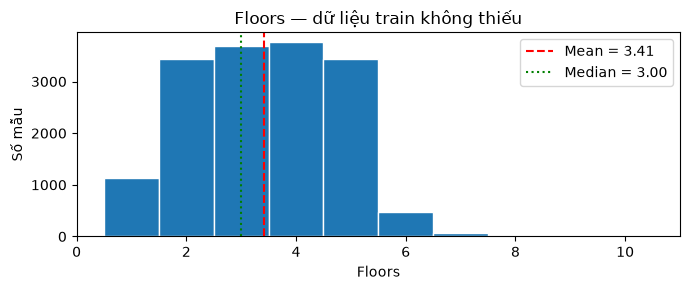

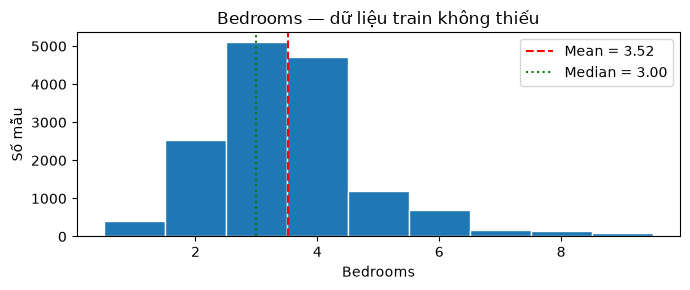

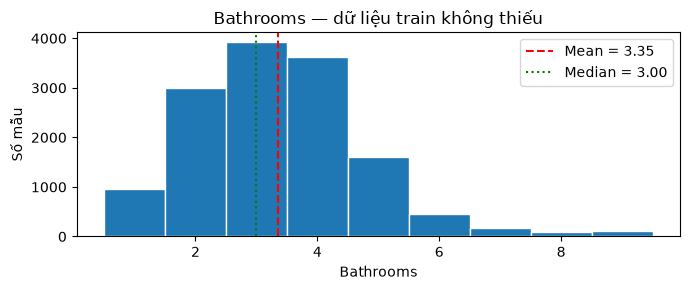

In [12]:
# C10 — Kiểm tra các cột numeric có missing trên train

assert "X_train" in globals(), "Chạy C01–C03 trước."

missing_numeric_cols = [
    column
    for column in NUMERIC_FEATURES
    if X_train[column].isna().any()
]

print("Các cột numeric có missing:", missing_numeric_cols)

numeric_audit_rows = []

for column in missing_numeric_cols:
    observed = X_train[column].dropna()

    assert not observed.empty, f"{column}: toàn bộ giá trị bị thiếu."

    q1 = observed.quantile(0.25)
    q3 = observed.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outside_iqr = (
        (observed < lower_bound)
        | (observed > upper_bound)
    )

    numeric_audit_rows.append({
        "feature": column,
        "missing_count": int(X_train[column].isna().sum()),
        "missing_pct": X_train[column].isna().mean() * 100,
        "mean": observed.mean(),
        "median": observed.median(),
        "mean_minus_median": observed.mean() - observed.median(),
        "min": observed.min(),
        "max": observed.max(),
        "skewness": observed.skew(),
        "IQR": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outside_IQR_count": int(outside_iqr.sum()),
        # Tỷ lệ trên các giá trị quan sát được, không gồm missing.
        "outside_IQR_pct": outside_iqr.mean() * 100,
    })

numeric_imputation_audit = pd.DataFrame(numeric_audit_rows)
display(numeric_imputation_audit.round(4))

# Histogram để xem hình dạng phân phối.
for column in missing_numeric_cols:
    fig, ax = plt.subplots(figsize=(7, 3))

    observed = X_train[column].dropna()
    ax.hist(observed, bins=np.arange(observed.min() - 0.5, observed.max() + 1.5, 1), edgecolor="white")

    ax.axvline(
        observed.mean(),
        color="red",
        linestyle="--",
        label=f"Mean = {observed.mean():.2f}",
    )
    ax.axvline(
        observed.median(),
        color="green",
        linestyle=":",
        label=f"Median = {observed.median():.2f}",
    )

    ax.set_title(f"{column} — dữ liệu train không thiếu")
    ax.set_xlabel(column)
    ax.set_ylabel("Số mẫu")
    ax.legend()

    plt.tight_layout()
    plt.show()
plt.close("all")


In [13]:
# C11 — Mean vs Median trên cùng RF đã chuẩn hóa
assert "normalized_rf" in globals(), "Chạy C09 trước."

imputation_models = {}
imputation_rows = []

for strategy in ["median", "mean"]:
    # Clone giữ cấu hình nhưng không giữ trạng thái đã fit.
    model = clone(normalized_rf)

    # Chỉ thay chiến lược điền missing của nhóm numeric.
    model.set_params(
        preprocessor__num__imputer__strategy=strategy
    )

    start = perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = perf_counter() - start

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    train_metrics = evaluate(y_train, train_pred)
    val_metrics = evaluate(y_val, val_pred)

    imputation_models[strategy] = model

    imputation_rows.append({
        "strategy": strategy,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "MAE_gap": val_metrics["MAE"] - train_metrics["MAE"],
        "fit_seconds": fit_seconds,
    })

imputation_results = pd.DataFrame(imputation_rows)

median_mae = imputation_results.loc[
    imputation_results["strategy"].eq("median"),
    "val_MAE",
].iloc[0]

imputation_results["gain_vs_median_pct"] = (
    (median_mae - imputation_results["val_MAE"])
    / median_mae * 100
)

imputation_results.insert(0, "model", "RF_normalized")
display(imputation_results.round(6))

,model,strategy,train_MAE,train_RMSE,train_R2,val_MAE,val_RMSE,val_R2,MAE_gap,fit_seconds,gain_vs_median_pct
0,RF_normalized,median,0.400547,0.559537,0.936129,1.021221,1.379487,0.603180,0.620674,21.298716,0.000000
1,RF_normalized,mean,0.393470,0.540044,0.940501,1.018811,1.375232,0.605624,0.625340,20.164572,0.236052


In [14]:
# C12 — Thêm missing indicators cho nhóm numeric
assert "imputation_models" in globals(), "Chạy C11 trước."
assert "mean" in imputation_models

mean_rf = imputation_models["mean"]

# Clone giữ cấu hình, không giữ trạng thái đã fit.
mean_indicator_rf = clone(mean_rf)

mean_indicator_rf.set_params(
    preprocessor__num__imputer__add_indicator=True
)

start = perf_counter()
mean_indicator_rf.fit(X_train, y_train)
indicator_fit_seconds = perf_counter() - start

# So sánh bằng dự đoán thực tế của hai model.
indicator_rows = []

for name, model in [
    ("RF_mean", mean_rf),
    ("RF_mean_with_indicator", mean_indicator_rf),
]:
    train_metrics = evaluate(
        y_train, model.predict(X_train)
    )
    val_metrics = evaluate(
        y_val, model.predict(X_val)
    )

    indicator_rows.append({
        "model": name,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "MAE_gap": val_metrics["MAE"] - train_metrics["MAE"],
    })

indicator_results = pd.DataFrame(indicator_rows)

mean_mae = indicator_results.loc[
    indicator_results["model"].eq("RF_mean"),
    "val_MAE",
].iloc[0]

indicator_results["gain_vs_mean_pct"] = (
    (mean_mae - indicator_results["val_MAE"])
    / mean_mae * 100
)

display(indicator_results.round(6))

# Xem chính xác những cột nào được thêm indicator.
fitted_imputer = (
    mean_indicator_rf
    .named_steps["preprocessor"]
    .named_transformers_["num"]
    .named_steps["imputer"]
)

indicator_columns = [
    NUMERIC_FEATURES[index]
    for index in fitted_imputer.indicator_.features_
]

print("Các cột có missing indicator:", indicator_columns)
print(f"Thời gian fit phương án mới: {indicator_fit_seconds:.1f} giây")

,model,train_MAE,train_RMSE,train_R2,val_MAE,val_RMSE,val_R2,MAE_gap,gain_vs_mean_pct
0,RF_mean,0.393470,0.540044,0.940501,1.018811,1.375232,0.605624,0.625340,0.000000
1,RF_mean_with_indicator,0.395435,0.541878,0.940097,1.023610,1.380480,0.602609,0.628175,-0.471033


Các cột có missing indicator: ['Floors', 'Bedrooms', 'Bathrooms']
Thời gian fit phương án mới: 23.6 giây


In [15]:
# C13 — So sánh Mean và KNN, cùng scaling trước imputation

assert "imputation_models" in globals(), "Chạy C11 trước."
assert "mean" in imputation_models

numeric_imputers = {
    "RF_scaled_mean": SimpleImputer(
        strategy="mean",
        add_indicator=False,
    ),
    "RF_scaled_KNN5": KNNImputer(
        n_neighbors=5,
        weights="uniform",
        add_indicator=False,
    ),
}

knn_experiment_models = {}
knn_experiment_rows = []

for name, imputer in numeric_imputers.items():
    print(f"Đang chạy: {name}", flush=True)

    model = clone(imputation_models["mean"])

    # Thay toàn bộ nhánh numeric:
    # scaling trước để KNN tính khoảng cách trên cùng thang đo.
    model.set_params(
        preprocessor__num=Pipeline([
            ("scaler", StandardScaler()),
            ("imputer", imputer),
        ])
    )

    start = perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = perf_counter() - start

    train_pred = model.predict(X_train)

    start = perf_counter()
    val_pred = model.predict(X_val)
    val_predict_seconds = perf_counter() - start

    train_metrics = evaluate(y_train, train_pred)
    val_metrics = evaluate(y_val, val_pred)

    knn_experiment_models[name] = model

    knn_experiment_rows.append({
        "model": name,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "MAE_gap": val_metrics["MAE"] - train_metrics["MAE"],
        "fit_seconds": fit_seconds,
        "val_predict_seconds": val_predict_seconds,
    })

knn_results = pd.DataFrame(knn_experiment_rows)

control_mae = knn_results.loc[
    knn_results["model"].eq("RF_scaled_mean"),
    "val_MAE",
].iloc[0]

knn_results["gain_vs_mean_pct"] = (
    (control_mae - knn_results["val_MAE"])
    / control_mae * 100
)

display(knn_results.round(6))

Đang chạy: RF_scaled_mean


Đang chạy: RF_scaled_KNN5


,model,train_MAE,train_RMSE,train_R2,val_MAE,val_RMSE,val_R2,MAE_gap,fit_seconds,val_predict_seconds,gain_vs_mean_pct
0,RF_scaled_mean,0.392999,0.539736,0.940569,1.017520,1.374156,0.606241,0.624521,19.888551,0.108490,0.000000
1,RF_scaled_KNN5,0.399563,0.549295,0.938445,1.023708,1.378973,0.603476,0.624145,30.097621,2.087381,-0.608133


In [16]:
# C14 — Chạy thêm KNN k=3 và k=15
assert "knn_results" in globals(), "Chạy C13 trước."
assert "knn_experiment_models" in globals(), "Chạy C13 trước."

new_knn_rows = []

for k in [3, 15]:
    name = f"RF_scaled_KNN{k}"
    print(f"Đang chạy: {name}", flush=True)

    model = clone(knn_experiment_models["RF_scaled_KNN5"])

    # Chỉ đổi số hàng xóm; giữ nguyên mọi thiết lập khác.
    model.set_params(
        preprocessor__num__imputer__n_neighbors=k
    )

    start = perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = perf_counter() - start

    train_pred = model.predict(X_train)

    start = perf_counter()
    val_pred = model.predict(X_val)
    val_predict_seconds = perf_counter() - start

    train_metrics = evaluate(y_train, train_pred)
    val_metrics = evaluate(y_val, val_pred)

    knn_experiment_models[name] = model

    new_knn_rows.append({
        "model": name,
        **{f"train_{metric}": value
           for metric, value in train_metrics.items()},
        **{f"val_{metric}": value
           for metric, value in val_metrics.items()},
        "MAE_gap": val_metrics["MAE"] - train_metrics["MAE"],
        "fit_seconds": fit_seconds,
        "val_predict_seconds": val_predict_seconds,
    })

# Lấy đúng hai kết quả đối chứng từ C13.
controls = knn_results.loc[
    knn_results["model"].isin([
        "RF_scaled_mean",
        "RF_scaled_KNN5",
    ])
].copy()

assert len(controls) == 2
assert controls["model"].is_unique

knn_k_results = pd.concat(
    [controls, pd.DataFrame(new_knn_rows)],
    ignore_index=True,
)

mean_mae = knn_k_results.loc[
    knn_k_results["model"].eq("RF_scaled_mean"),
    "val_MAE",
].iloc[0]

knn_k_results["gain_vs_mean_pct"] = (
    (mean_mae - knn_k_results["val_MAE"])
    / mean_mae * 100
)

knn_k_results = knn_k_results.sort_values(
    "val_MAE"
).reset_index(drop=True)

display(knn_k_results.round(6))

Đang chạy: RF_scaled_KNN3


Đang chạy: RF_scaled_KNN15


,model,train_MAE,train_RMSE,train_R2,val_MAE,val_RMSE,val_R2,MAE_gap,fit_seconds,val_predict_seconds,gain_vs_mean_pct
0,RF_scaled_mean,0.392999,0.539736,0.940569,1.017520,1.374156,0.606241,0.624521,19.888551,0.108490,0.000000
1,RF_scaled_KNN5,0.399563,0.549295,0.938445,1.023708,1.378973,0.603476,0.624145,30.097621,2.087381,-0.608133
2,RF_scaled_KNN15,0.397359,0.542969,0.939855,1.023828,1.378568,0.603708,0.626469,27.368873,2.118045,-0.619905
3,RF_scaled_KNN3,0.401193,0.552919,0.937631,1.025378,1.381036,0.602288,0.624185,27.595489,2.006482,-0.772250


In [17]:
# C15 — Mode vs category "__MISSING__"
assert "knn_experiment_models" in globals(), "Chạy C13 trước."
assert "RF_scaled_mean" in knn_experiment_models

mode_rf = knn_experiment_models["RF_scaled_mean"]
MISSING_LABEL = "__MISSING__"

# Tránh dùng một nhãn đã tồn tại trong dữ liệu train.
for column in CATEGORICAL_FEATURES:
    assert not X_train[column].eq(MISSING_LABEL).fillna(False).any(), (
        f"{column}: nhãn {MISSING_LABEL} đã tồn tại."
    )

assert (
    mode_rf.get_params()["preprocessor__cat__imputer__strategy"]
    == "most_frequent"
), "Model đối chứng phải dùng mode cho categorical."

# Clone giữ cấu hình, không giữ trạng thái đã fit.
missing_category_rf = clone(mode_rf)

# Chỉ thay cách điền missing trong nhánh categorical.
missing_category_rf.set_params(
    preprocessor__cat__imputer__strategy="constant",
    preprocessor__cat__imputer__fill_value=MISSING_LABEL,
)

start = perf_counter()
missing_category_rf.fit(X_train, y_train)
missing_category_fit_seconds = perf_counter() - start

category_rows = []

for name, model in [
    ("RF_cat_mode", mode_rf),
    ("RF_cat_missing_label", missing_category_rf),
]:
    train_metrics = evaluate(
        y_train, model.predict(X_train)
    )
    val_metrics = evaluate(
        y_val, model.predict(X_val)
    )

    category_rows.append({
        "model": name,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "MAE_gap": val_metrics["MAE"] - train_metrics["MAE"],
    })

category_results = pd.DataFrame(category_rows)

mode_mae = category_results.loc[
    category_results["model"].eq("RF_cat_mode"),
    "val_MAE",
].iloc[0]

category_results["gain_vs_mode_pct"] = (
    (mode_mae - category_results["val_MAE"])
    / mode_mae * 100
)

display(category_results.round(6))

# Kiểm tra encoder đã học category missing ở những cột nào.
fitted_encoder = (
    missing_category_rf
    .named_steps["preprocessor"]
    .named_transformers_["cat"]
    .named_steps["onehot"]
)

category_check = pd.DataFrame([
    {
        "feature": column,
        "missing_category_learned": MISSING_LABEL in categories,
        "encoded_categories": len(categories),
    }
    for column, categories in zip(
        CATEGORICAL_FEATURES,
        fitted_encoder.categories_,
    )
])

display(category_check)

print(
    "Thời gian fit phương án mới:",
    f"{missing_category_fit_seconds:.1f} giây",
)

,model,train_MAE,train_RMSE,train_R2,val_MAE,val_RMSE,val_R2,MAE_gap,gain_vs_mode_pct
0,RF_cat_mode,0.392999,0.539736,0.940569,1.017520,1.374156,0.606241,0.624521,0.000000
1,RF_cat_missing_label,0.388505,0.526996,0.943342,1.021881,1.374691,0.605935,0.633376,-0.428556


,feature,missing_category_learned,encoded_categories
0,House direction,True,9
1,Balcony direction,True,9
2,Legal status,True,3
3,Furniture state,True,3
4,City,True,69
5,District,True,295


Thời gian fit phương án mới: 24.2 giây


## 4. Model tuyến tính — regularization

**C16:** chạy lại Linear Regression, bốn Ridge và sáu ElasticNet trên cùng preprocessing như RF_scaled_mean. Numeric được scaling; One-Hot giữ 0/1. Alpha giữa Ridge/ElasticNet không so trực tiếp về mức phạt.

Ghi nhận lịch sử: Ridge alpha=1 tốt nhất theo MAE (1.256151), chỉ cải thiện nhẹ so với LR (1.259860). ElasticNet giảm số hệ số nhưng chưa cải thiện MAE. Cấu hình mạnh làm train/validation cùng kém đi. Không có ConvergenceWarning không phải bằng chứng tổng quát model tối ưu; kiểm tra cảnh báo và giới hạn số bước khi phát sinh.

Số hệ số là số cột sau encoding, không phải 12 feature gốc. Giữ Ridge làm đại diện tuyến tính, chưa tạo tương tác/feature mới.

In [18]:
# C16 — So sánh các model tuyến tính


assert "knn_experiment_models" in globals(), "Chạy C13 trước."
assert "RF_scaled_mean" in knn_experiment_models

rf_template = knn_experiment_models["RF_scaled_mean"]

# 1. Preprocessing chung, chỉ fit trên train.
linear_preprocessing = Pipeline([
    (name, clone(step))
    for name, step in rf_template.steps[:-1]
])

X_train_linear = linear_preprocessing.fit_transform(
    X_train, y_train
)
X_val_linear = linear_preprocessing.transform(X_val)

print("Train sau preprocessing:", X_train_linear.shape)
print("Validation sau preprocessing:", X_val_linear.shape)

# 2. Danh sách cấu hình.
linear_candidates = {
    "LinearRegression": LinearRegression(),
}

for alpha in [0.1, 1.0, 10.0, 100.0]:
    linear_candidates[f"Ridge_alpha_{alpha}"] = Ridge(
        alpha=alpha,
        solver="lsqr",
        tol=1e-6,
        max_iter=20000,
    )

for alpha in [0.001, 0.01, 0.1]:
    for l1_ratio in [0.2, 0.8]:
        name = f"ElasticNet_alpha_{alpha}_l1_{l1_ratio}"

        linear_candidates[name] = ElasticNet(
            alpha=alpha,
            l1_ratio=l1_ratio,
            max_iter=20000,
            tol=1e-4,
            selection="cyclic",
        )

# 3. Fit, đánh giá và lưu model.
linear_models = {}
linear_rows = []

for name, model in linear_candidates.items():
    print(f"Đang chạy: {name}", flush=True)

    start = perf_counter()

    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter("always")
        model.fit(X_train_linear, y_train)

    fit_seconds = perf_counter() - start

    convergence_warning = any(
        issubclass(w.category, ConvergenceWarning)
        for w in captured
    )

    # Hiển thị cảnh báo đã ghi nhận, không âm thầm bỏ qua.
    for warning in captured:
        print(f"  Cảnh báo: {warning.message}")

    train_metrics = evaluate(
        y_train, model.predict(X_train_linear)
    )
    val_metrics = evaluate(
        y_val, model.predict(X_val_linear)
    )

    coefficients = np.asarray(model.coef_).ravel()

    linear_models[name] = model

    linear_rows.append({
        "model": name,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "MAE_gap": val_metrics["MAE"] - train_metrics["MAE"],
        "nonzero_coef": int(
            np.count_nonzero(np.abs(coefficients) > 1e-8)
        ),
        "total_coef": coefficients.size,
        "convergence_warning": convergence_warning,
        "fit_seconds": fit_seconds,
    })

linear_results = pd.DataFrame(linear_rows)

lr_mae = linear_results.loc[
    linear_results["model"].eq("LinearRegression"),
    "val_MAE",
].iloc[0]

linear_results["gain_vs_LR_pct"] = (
    (lr_mae - linear_results["val_MAE"])
    / lr_mae * 100
)

linear_results = linear_results.sort_values(
    "val_MAE"
).reset_index(drop=True)

display(linear_results.round(6))

if linear_results["convergence_warning"].any():
    print(
        "Có cấu hình phát cảnh báo hội tụ. "
        "Cần kiểm tra trước khi dùng kết quả để chọn model."
    )
# Pipeline riêng cho từng model tuyến tính, dùng được với X nguyên bản.
linear_pipelines = {
    name: Pipeline([
        ('preprocessing', deepcopy(linear_preprocessing)),
        ('model', fitted_model),
    ])
    for name, fitted_model in linear_models.items()
}


Train sau preprocessing: (18136, 388)
Validation sau preprocessing: (4535, 388)
Đang chạy: LinearRegression


Đang chạy: Ridge_alpha_0.1


Đang chạy: Ridge_alpha_1.0


Đang chạy: Ridge_alpha_10.0


Đang chạy: Ridge_alpha_100.0


...

Đang chạy: ElasticNet_alpha_0.01_l1_0.2


Đang chạy: ElasticNet_alpha_0.01_l1_0.8


Đang chạy: ElasticNet_alpha_0.1_l1_0.2


Đang chạy: ElasticNet_alpha_0.1_l1_0.8


,model,train_MAE,train_RMSE,train_R2,val_MAE,val_RMSE,val_R2,MAE_gap,nonzero_coef,total_coef,convergence_warning,fit_seconds,gain_vs_LR_pct
0,Ridge_alpha_1.0,1.242391,1.586702,0.486383,1.256151,1.623893,0.450113,0.013760,388,388,False,0.201413,0.294450
1,Ridge_alpha_0.1,1.235850,1.583146,0.488683,1.259106,1.634854,0.442665,0.023256,388,388,False,0.226073,0.059912
2,LinearRegression,1.234645,1.583032,0.488756,1.259861,1.637435,0.440904,0.025216,388,388,False,0.208501,0.000000
3,Ridge_alpha_10.0,1.264111,1.609831,0.471300,1.263024,1.622486,0.451066,-0.001086,388,388,False,0.124419,-0.251097
4,ElasticNet_alpha_0.001_l1_0.8,1.278947,1.628759,0.458795,1.271163,1.629393,0.446382,-0.007784,127,388,False,0.159378,-0.897131
5,ElasticNet_alpha_0.001_l1_0.2,1.276807,1.624124,0.461870,1.271271,1.629552,0.446274,-0.005536,232,388,False,0.184826,-0.905699
6,Ridge_alpha_100.0,1.331765,1.678473,0.425252,1.318768,1.674729,0.415146,-0.012997,388,388,False,0.056062,-4.675698
7,ElasticNet_alpha_0.01_l1_0.2,1.375126,1.723830,0.393770,1.355842,1.712011,0.388817,-0.019284,87,388,False,0.039593,-7.618368
8,ElasticNet_alpha_0.01_l1_0.8,1.405377,1.758251,0.369318,1.383918,1.743261,0.366301,-0.021459,39,388,False,0.056576,-9.846922
9,ElasticNet_alpha_0.1_l1_0.2,1.547090,1.896856,0.265964,1.523188,1.872833,0.268597,-0.023902,25,388,False,0.022946,-20.901293


## 5. Boosting — CatBoost, XGBoost, LightGBM

| Cell | Experiment | Preprocessing / ghi nhận lịch sử |
|---|---|---|
| C17 | CatBoost 1500 vòng | Numeric median, categorical mode và native categorical; MAE 0.999866 |
| C18 | CatBoost 3000 vòng | Giữ nguyên C17; best 2973, MAE 0.990914 |
| C19 | XGBoost 3000 vòng | Preprocessing RF_scaled_mean; best 2993, MAE 0.980569 |
| C20 | LightGBM 3000 vòng | Cùng ma trận đầu vào C19; best 1527, MAE 0.986465 |

Đây là so sánh pipeline ứng viên, **chưa phải ablation chỉ đổi thuật toán**: CatBoost giữ median/native categorical để bảo toàn experiment cũ. XGBoost và LightGBM dùng One-Hot; thư viện có thể xử lý phần tử không lưu trong sparse khác nhau. Không suy ra cùng ma trận nghĩa là cùng cơ chế học.

Validation dùng cho early stopping/chọn vòng; chưa phải đánh giá cuối. Số vòng chạy khác số vòng tốt nhất. RMSE và R² cùng dựa trên bình phương lỗi; không xem là hai phiếu độc lập chống lại MAE. Thời gian là lần đo thực tế, chưa phải benchmark kiểm soát.

Các pipeline XGBoost/LightGBM được ghép từ thành phần đã fit để predict; không fit lại trực tiếp pipeline ghép khi dùng eval_set thô. Preprocessing được sao chép độc lập để tránh model này thay đổi trạng thái model khác.

In [19]:
# C17 — CatBoost đầu tiên, so sánh với RF sau chuẩn hóa

assert "normalized_rf" in globals(), "Chạy C09 trước."

print("CatBoost version:", catboost.__version__)

# 1. Chuẩn hóa tên trên bản sao, không sửa dữ liệu gốc.
cb_train = normalize_location_frame(X_train)
cb_val = normalize_location_frame(X_val)

# 2. Học giá trị điền thiếu chỉ từ train.
cb_numeric_imputer = SimpleImputer(strategy="median")
cb_category_imputer = SimpleImputer(strategy="most_frequent")

assert cb_train[NUMERIC_FEATURES].notna().any().all()
assert cb_train[CATEGORICAL_FEATURES].notna().any().all()

cb_train[NUMERIC_FEATURES] = cb_numeric_imputer.fit_transform(
    cb_train[NUMERIC_FEATURES]
)
cb_val[NUMERIC_FEATURES] = cb_numeric_imputer.transform(
    cb_val[NUMERIC_FEATURES]
)

cb_train[CATEGORICAL_FEATURES] = (
    cb_category_imputer.fit_transform(
        cb_train[CATEGORICAL_FEATURES]
    )
)
cb_val[CATEGORICAL_FEATURES] = cb_category_imputer.transform(
    cb_val[CATEGORICAL_FEATURES]
)

# CatBoost nhận categorical dạng chuỗi, không còn missing.
for column in CATEGORICAL_FEATURES:
    assert cb_train[column].notna().all()
    assert cb_val[column].notna().all()

    cb_train[column] = cb_train[column].astype(str)
    cb_val[column] = cb_val[column].astype(str)

assert list(cb_train.columns) == list(cb_val.columns)
assert cb_train.index.equals(y_train.index)
assert cb_val.index.equals(y_val.index)

# 3. Một cấu hình khởi đầu.
catboost_model = CatBoostRegressor(
    iterations=1500,
    depth=6,
    learning_rate=0.05,
    loss_function="RMSE",
    eval_metric="MAE",
    random_seed=42,
    task_type="CPU",
    allow_writing_files=False,
)

start = perf_counter()

catboost_model.fit(
    cb_train,
    y_train,
    cat_features=CATEGORICAL_FEATURES,
    eval_set=(cb_val, y_val),
    early_stopping_rounds=100,
    use_best_model=True,
    verbose=200,
)

cb_fit_seconds = perf_counter() - start

# 4. Dự đoán và đánh giá.
cb_train_pred = catboost_model.predict(cb_train)
cb_val_pred = catboost_model.predict(cb_val)

rf_train_pred = normalized_rf.predict(X_train)
rf_val_pred = normalized_rf.predict(X_val)

model_comparison_rows = []

for name, train_pred, val_pred in [
    ("RF_normalized", rf_train_pred, rf_val_pred),
    ("CatBoost_initial", cb_train_pred, cb_val_pred),
]:
    train_metrics = evaluate(y_train, train_pred)
    val_metrics = evaluate(y_val, val_pred)

    model_comparison_rows.append({
        "model": name,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "MAE_gap": val_metrics["MAE"] - train_metrics["MAE"],
    })

boosting_comparison = pd.DataFrame(model_comparison_rows)

rf_mae = boosting_comparison.loc[
    boosting_comparison["model"].eq("RF_normalized"),
    "val_MAE",
].iloc[0]

boosting_comparison["gain_vs_RF_pct"] = (
    (rf_mae - boosting_comparison["val_MAE"])
    / rf_mae * 100
)

print("\nSo sánh model — MAE/RMSE dùng tỷ VND:")
display(boosting_comparison.round(6))

print("Số cây được giữ:", catboost_model.tree_count_)
print(
    "Vòng tốt nhất (đếm từ 1):",
    catboost_model.get_best_iteration() + 1,
)
print(f"Thời gian fit CatBoost: {cb_fit_seconds:.1f} giây")

CatBoost version: 1.2.10


0:	learn: 1.8137331	test: 1.7926366	best: 1.7926366 (0)	total: 227ms	remaining: 5m 40s


200:	learn: 1.1002966	test: 1.0774834	best: 1.0774834 (200)	total: 19.3s	remaining: 2m 4s


400:	learn: 1.0385813	test: 1.0388183	best: 1.0388183 (400)	total: 38.6s	remaining: 1m 45s


600:	learn: 1.0087966	test: 1.0261355	best: 1.0261355 (600)	total: 58.2s	remaining: 1m 27s


...

1400:	learn: 0.9329536	test: 1.0021219	best: 1.0021219 (1400)	total: 2m 15s	remaining: 9.57s


1499:	learn: 0.9252710	test: 0.9998655	best: 0.9998655 (1499)	total: 2m 25s	remaining: 0us

bestTest = 0.9998654507
bestIteration = 1499




So sánh model — MAE/RMSE dùng tỷ VND:


,model,train_MAE,train_RMSE,train_R2,val_MAE,val_RMSE,val_R2,MAE_gap,gain_vs_RF_pct
0,RF_normalized,0.400547,0.559537,0.936129,1.021221,1.379487,0.603180,0.620674,0.0000
1,CatBoost_initial,0.931441,1.220773,0.695968,0.999866,1.324894,0.633967,0.068426,2.0911


Số cây được giữ: 1500
Vòng tốt nhất (đếm từ 1): 1500
Thời gian fit CatBoost: 145.9 giây


In [20]:
# C18 — CatBoost: tối đa 3000 vòng
assert "catboost_model" in globals(), "Chạy C17 trước."
assert "cb_train" in globals() and "cb_val" in globals()

# Lấy đúng cấu hình của model khởi đầu.
extended_params = catboost_model.get_params().copy()
assert extended_params["iterations"] == 1500

extended_params["iterations"] = 3000

# Model mới; giữ nguyên model 1500 vòng để đối chiếu.
catboost_3000 = CatBoostRegressor(**extended_params)

start = perf_counter()

catboost_3000.fit(
    cb_train,
    y_train,
    cat_features=CATEGORICAL_FEATURES,
    eval_set=(cb_val, y_val),
    early_stopping_rounds=100,
    use_best_model=True,
    verbose=300,
)

cb_3000_fit_seconds = perf_counter() - start

iteration_rows = []

for name, model in [
    ("CatBoost_max1500", catboost_model),
    ("CatBoost_max3000", catboost_3000),
]:
    train_metrics = evaluate(
        y_train, model.predict(cb_train)
    )
    val_metrics = evaluate(
        y_val, model.predict(cb_val)
    )

    iteration_rows.append({
        "model": name,
        "iteration_limit": model.get_params()["iterations"],
        "trees_kept": model.tree_count_,
        "best_iteration": model.get_best_iteration() + 1,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "MAE_gap": val_metrics["MAE"] - train_metrics["MAE"],
    })

catboost_iteration_results = pd.DataFrame(iteration_rows)

initial_mae = catboost_iteration_results.loc[
    catboost_iteration_results["model"].eq("CatBoost_max1500"),
    "val_MAE",
].iloc[0]

catboost_iteration_results["gain_vs_1500_pct"] = (
    (initial_mae - catboost_iteration_results["val_MAE"])
    / initial_mae * 100
)

display(catboost_iteration_results.round(6))

print(f"Thời gian fit model mới: {cb_3000_fit_seconds:.1f} giây")

0:	learn: 1.8137331	test: 1.7926366	best: 1.7926366 (0)	total: 109ms	remaining: 5m 27s


300:	learn: 1.0639279	test: 1.0529682	best: 1.0529526 (299)	total: 31.6s	remaining: 4m 43s


600:	learn: 1.0087966	test: 1.0261355	best: 1.0261355 (600)	total: 1m 2s	remaining: 4m 8s


900:	learn: 0.9730165	test: 1.0123930	best: 1.0123719 (899)	total: 1m 33s	remaining: 3m 37s


1200:	learn: 0.9470061	test: 1.0051339	best: 1.0049545 (1188)	total: 2m 4s	remaining: 3m 5s


...

2400:	learn: 0.8756274	test: 0.9936895	best: 0.9936895 (2400)	total: 4m 8s	remaining: 1m 1s


2700:	learn: 0.8624430	test: 0.9926211	best: 0.9926211 (2700)	total: 4m 39s	remaining: 30.9s


2999:	learn: 0.8502600	test: 0.9909867	best: 0.9909135 (2972)	total: 5m 10s	remaining: 0us

bestTest = 0.9909134779
bestIteration = 2972

Shrink model to first 2973 iterations.


,model,iteration_limit,trees_kept,best_iteration,train_MAE,train_RMSE,train_R2,val_MAE,val_RMSE,val_R2,MAE_gap,gain_vs_1500_pct
0,CatBoost_max1500,1500,1500,1500,0.931441,1.220773,0.695968,0.999866,1.324894,0.633967,0.068426,0.000000
1,CatBoost_max3000,3000,2973,2973,0.884386,1.163647,0.723757,0.990914,1.315498,0.639140,0.106529,0.895317


Thời gian fit model mới: 310.6 giây


In [21]:
# C19 — XGBoost khởi đầu

assert "knn_experiment_models" in globals(), "Chạy C13 trước."
assert "catboost_3000" in globals(), "Chạy C18 trước."

print("XGBoost version:", xgboost.__version__)

rf_reference = knn_experiment_models["RF_scaled_mean"]

# 1. Clone các bước preprocessing từ RF, không lấy model RF.
xgb_preprocessing = Pipeline([
    (name, clone(step))
    for name, step in rf_reference.steps[:-1]
])

start = perf_counter()

X_train_xgb = xgb_preprocessing.fit_transform(X_train, y_train)
X_val_xgb = xgb_preprocessing.transform(X_val)

xgb_preprocessing_seconds = perf_counter() - start

print("Train sau preprocessing:", X_train_xgb.shape)
print("Validation sau preprocessing:", X_val_xgb.shape)

# 2. Một cấu hình khởi đầu.
xgb_model = XGBRegressor(
    n_estimators=3000,
    max_depth=6,
    learning_rate=0.05,
    objective="reg:squarederror",
    eval_metric="mae",
    tree_method="hist",
    subsample=1.0,
    colsample_bytree=1.0,
    random_state=42,
    n_jobs=-1,
    early_stopping_rounds=100,
)

start = perf_counter()

xgb_model.fit(
    X_train_xgb,
    y_train,
    eval_set=[(X_val_xgb, y_val)],
    verbose=300,
)

xgb_fit_seconds = perf_counter() - start

# 3. Ghép lại để predict trực tiếp từ X chưa preprocessing.
# Hai thành phần đều đã fit. Không gọi fit lại pipeline này.
xgb_pipeline = Pipeline([
    ("preprocessing", deepcopy(xgb_preprocessing)),
    ("model", xgb_model),
])

# 4. So sánh bằng dự đoán thực tế.
comparison_inputs = [
    (
        "RF_scaled_mean",
        rf_reference.predict(X_train),
        rf_reference.predict(X_val),
    ),
    (
        "CatBoost_max3000",
        catboost_3000.predict(cb_train),
        catboost_3000.predict(cb_val),
    ),
    (
        "XGBoost_initial",
        xgb_pipeline.predict(X_train),
        xgb_pipeline.predict(X_val),
    ),
]

exploration_rows = []

for name, train_pred, val_pred in comparison_inputs:
    train_metrics = evaluate(y_train, train_pred)
    val_metrics = evaluate(y_val, val_pred)

    exploration_rows.append({
        "model": name,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "MAE_gap": val_metrics["MAE"] - train_metrics["MAE"],
    })

model_exploration_results = pd.DataFrame(exploration_rows)

rf_mae = model_exploration_results.loc[
    model_exploration_results["model"].eq("RF_scaled_mean"),
    "val_MAE",
].iloc[0]

model_exploration_results["gain_vs_RF_pct"] = (
    (rf_mae - model_exploration_results["val_MAE"])
    / rf_mae * 100
)

display(
    model_exploration_results
    .sort_values("val_MAE")
    .reset_index(drop=True)
    .round(6)
)

rounds_run = len(
    xgb_model.evals_result()["validation_0"]["mae"]
)

print("Số vòng đã chạy:", rounds_run)
print("Vòng tốt nhất:", xgb_model.best_iteration + 1)
print(f"Thời gian preprocessing: {xgb_preprocessing_seconds:.1f} giây")
print(f"Thời gian fit XGBoost: {xgb_fit_seconds:.1f} giây")

XGBoost version: 3.4.1
Train sau preprocessing: (18136, 388)
Validation sau preprocessing: (4535, 388)


[0]	validation_0-mae:1.78817


[300]	validation_0-mae:1.05047


[600]	validation_0-mae:1.01442


[900]	validation_0-mae:1.00072


...

[2400]	validation_0-mae:0.98372


[2700]	validation_0-mae:0.98215


[2999]	validation_0-mae:0.98060


,model,train_MAE,train_RMSE,train_R2,val_MAE,val_RMSE,val_R2,MAE_gap,gain_vs_RF_pct
0,XGBoost_initial,0.700953,0.950592,0.815653,0.980569,1.327245,0.632667,0.279617,3.631465
1,CatBoost_max3000,0.884386,1.163647,0.723757,0.990914,1.315498,0.639140,0.106529,2.614769
2,RF_scaled_mean,0.392999,0.539736,0.940569,1.017520,1.374156,0.606241,0.624521,0.000000


Số vòng đã chạy: 3000
Vòng tốt nhất: 2993
Thời gian preprocessing: 0.1 giây
Thời gian fit XGBoost: 41.8 giây


In [22]:
# C20 — LightGBM khởi đầu

assert "X_train_xgb" in globals(), "Chạy C19 trước."
assert "X_val_xgb" in globals(), "Chạy C19 trước."
assert "xgb_pipeline" in globals(), "Chạy C19 trước."
assert "catboost_3000" in globals(), "Chạy C18 trước."

print("LightGBM version:", lgb.__version__)

# Dùng nguyên ma trận đầu vào của experiment XGBoost.
X_train_lgb = X_train_xgb
X_val_lgb = X_val_xgb

assert X_train_lgb.shape[0] == len(y_train)
assert X_val_lgb.shape[0] == len(y_val)
assert X_train_lgb.shape[1] == X_val_lgb.shape[1]

lgb_model = lgb.LGBMRegressor(
    objective="regression",
    metric="mae",
    n_estimators=3000,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=6,
    min_child_samples=20,
    subsample=1.0,
    colsample_bytree=1.0,
    random_state=42,
    n_jobs=-1,
    verbosity=-1,
)

start = perf_counter()

lgb_model.fit(
    X_train_lgb,
    y_train,
    eval_X=X_val_lgb,
    eval_y=y_val,
    eval_names=["validation"],
    callbacks=[
        lgb.early_stopping(
            stopping_rounds=100,
            first_metric_only=True,
            verbose=True,
        ),
        lgb.log_evaluation(period=300),
    ],
)

lgb_fit_seconds = perf_counter() - start

# Lưu preprocessing đã fit cùng model để predict từ X gốc.
# Không gọi fit lại pipeline này.
lgb_pipeline = Pipeline([
    ("preprocessing", deepcopy(xgb_preprocessing)),
    ("model", lgb_model),
])

# Bản sao preprocessing đã fit thuộc riêng pipeline này; không chia sẻ trạng thái với XGBoost.

rf_reference = knn_experiment_models["RF_scaled_mean"]

comparison_inputs = [
    (
        "RF_scaled_mean",
        rf_reference.predict(X_train),
        rf_reference.predict(X_val),
    ),
    (
        "CatBoost_max3000",
        catboost_3000.predict(cb_train),
        catboost_3000.predict(cb_val),
    ),
    (
        "XGBoost_initial",
        xgb_pipeline.predict(X_train),
        xgb_pipeline.predict(X_val),
    ),
    (
        "LightGBM_initial",
        lgb_pipeline.predict(X_train),
        lgb_pipeline.predict(X_val),
    ),
]

comparison_rows = []

for name, train_pred, val_pred in comparison_inputs:
    train_metrics = evaluate(y_train, train_pred)
    val_metrics = evaluate(y_val, val_pred)

    comparison_rows.append({
        "model": name,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "MAE_gap": val_metrics["MAE"] - train_metrics["MAE"],
    })

boosting_results = pd.DataFrame(comparison_rows)

rf_mae = boosting_results.loc[
    boosting_results["model"].eq("RF_scaled_mean"),
    "val_MAE",
].iloc[0]

boosting_results["gain_vs_RF_pct"] = (
    (rf_mae - boosting_results["val_MAE"])
    / rf_mae * 100
)

display(
    boosting_results
    .sort_values("val_MAE")
    .reset_index(drop=True)
    .round(6)
)

# Đếm số vòng đã được ghi vào lịch sử đánh giá.
validation_history = lgb_model.evals_result_["validation"]
rounds_run = len(next(iter(validation_history.values())))

print("Số vòng đã chạy:", rounds_run)
print("Vòng tốt nhất:", lgb_model.best_iteration_)
print(f"Thời gian fit LightGBM: {lgb_fit_seconds:.1f} giây")

LightGBM version: 4.7.0
Training until validation scores don't improve for 100 rounds


[300]	validation's l1: 1.0457


[600]	validation's l1: 1.00713


[900]	validation's l1: 0.994999


[1200]	validation's l1: 0.989191


[1500]	validation's l1: 0.986803


Early stopping, best iteration is:
[1527]	validation's l1: 0.986465
Evaluated only: l1


,model,train_MAE,train_RMSE,train_R2,val_MAE,val_RMSE,val_R2,MAE_gap,gain_vs_RF_pct
0,XGBoost_initial,0.700953,0.950592,0.815653,0.980569,1.327245,0.632667,0.279617,3.631465
1,LightGBM_initial,0.839405,1.112113,0.747683,0.986465,1.320170,0.636572,0.147060,3.052067
2,CatBoost_max3000,0.884386,1.163647,0.723757,0.990914,1.315498,0.639140,0.106529,2.614769
3,RF_scaled_mean,0.392999,0.539736,0.940569,1.017520,1.374156,0.606241,0.624521,0.000000


Số vòng đã chạy: 1627
Vòng tốt nhất: 1527
Thời gian fit LightGBM: 8.6 giây


## 6. Tổng hợp và điểm dừng

**C21** ghép metric thực tế từ các bảng vừa tính, không nhập cứng. Bảng gồm RF gốc, RF chuẩn hóa, RF mean hiện tại, LR/Ridge/ElasticNet và các boosting. Chỉ xét ứng viên tuyến tính không phát ConvergenceWarning; phải đối chiếu kết quả trước khi chốt. Tất cả là validation, không phải test.

In [23]:
# C21 — Tổng hợp model từ kết quả thực tế
summary_parts = []

def add_summary(frame, preprocessing_label):
    columns = ['model', 'train_MAE', 'train_RMSE', 'train_R2',
               'val_MAE', 'val_RMSE', 'val_R2', 'MAE_gap']
    part = frame[columns].copy()
    part['preprocessing'] = preprocessing_label
    summary_parts.append(part)

rf_original = results_exp01.loc[results_exp01['experiment'].eq('RF_baseline')].rename(columns={'experiment':'model'})
add_summary(rf_original, 'Original location; median → scaling; categorical mode/OHE')
rf_normalized = normalization_results.loc[normalization_results['experiment'].eq('RF_after_normalization')].rename(columns={'experiment':'model'})
add_summary(rf_normalized, 'Normalized location; median → scaling; categorical mode/OHE')
add_summary(knn_results.loc[knn_results['model'].eq('RF_scaled_mean')], 'Normalized location; scaling → mean; categorical mode/OHE')

eligible_linear = linear_results.loc[~linear_results['convergence_warning']].copy()
assert not eligible_linear.empty, 'Chưa có ứng viên tuyến tính hợp lệ để tổng hợp.'
add_summary(eligible_linear, 'Normalized location; scaling → mean; categorical mode/OHE')
add_summary(catboost_iteration_results, 'Normalized location; numeric median; categorical mode/native')
add_summary(boosting_results.loc[boosting_results['model'].isin(['XGBoost_initial','LightGBM_initial'])], 'Normalized location; scaling → mean; categorical mode/OHE')

final_model_summary = pd.concat(summary_parts, ignore_index=True)
assert final_model_summary['model'].is_unique
assert np.isfinite(final_model_summary.select_dtypes(include='number').to_numpy()).all()
final_model_summary = final_model_summary.sort_values('val_MAE').reset_index(drop=True)
display(final_model_summary.round(6))
print('Dẫn đầu MAE validation trong lần chạy này:', final_model_summary.iloc[0]['model'])
print('Chưa chốt model cuối; calibration/test chưa được dùng.')


,model,train_MAE,train_RMSE,train_R2,val_MAE,val_RMSE,val_R2,MAE_gap,preprocessing
0,XGBoost_initial,0.700953,0.950592,0.815653,0.980569,1.327245,0.632667,0.279617,Normalized location; scaling → mean; categoric...
1,LightGBM_initial,0.839405,1.112113,0.747683,0.986465,1.320170,0.636572,0.147060,Normalized location; scaling → mean; categoric...
2,CatBoost_max3000,0.884386,1.163647,0.723757,0.990914,1.315498,0.639140,0.106529,Normalized location; numeric median; categoric...
3,CatBoost_max1500,0.931441,1.220773,0.695968,0.999866,1.324894,0.633967,0.068426,Normalized location; numeric median; categoric...
4,RF_scaled_mean,0.392999,0.539736,0.940569,1.017520,1.374156,0.606241,0.624521,Normalized location; scaling → mean; categoric...
5,RF_after_normalization,0.400547,0.559537,0.936129,1.021221,1.379487,0.603180,0.620674,Normalized location; median → scaling; categor...
6,RF_baseline,0.403141,0.564637,0.934959,1.023930,1.388079,0.598222,0.620790,Original location; median → scaling; categoric...
7,Ridge_alpha_1.0,1.242391,1.586702,0.486383,1.256151,1.623893,0.450113,0.013760,Normalized location; scaling → mean; categoric...
8,Ridge_alpha_0.1,1.235850,1.583146,0.488683,1.259106,1.634854,0.442665,0.023256,Normalized location; scaling → mean; categoric...
9,LinearRegression,1.234645,1.583032,0.488756,1.259861,1.637435,0.440904,0.025216,Normalized location; scaling → mean; categoric...


Dẫn đầu MAE validation trong lần chạy này: XGBoost_initial
Chưa chốt model cuối; calibration/test chưa được dùng.


## 7. Roadmap sau model exploration

1. Đọc bảng C21 và đối chiếu các kết luận lịch sử; không tự chuyển kết quả RF thành lựa chọn preprocessing cho mọi model.
2. Thử preprocessing/feature engineering trên vài model đại diện; experiment đầu dự kiến City_District, chưa triển khai.
3. Cross-validation với preprocessing fit riêng trong từng fold, rồi tuning có giới hạn và explainability.
4. Ensemble đơn giản nếu có lý do; Deep Learning để nhánh nâng cao sau.
5. Chốt model trước notebook 04: refit, calibration interval, test, lưu/load và inference.

Chưa có feature engineering City_District, CV, SHAP hoặc final test trong notebook hiện tại. Không coi R² train hoặc validation là nghiệm thu test.

**Cập nhật 2026-10-20:** mục 2–4 đã thực hiện. Phần A (C40–C47) làm trên v1; Phần B (C52–C66) làm lại trên `splits_v2` theo góp ý của người review, gồm feature engineering, so sánh metric, ensemble và giải thích. Mục 5 (refit, calibration, test, lưu/nạp) chuyển sang notebook 04 với lựa chọn lưu ở `experiments/final_selection/selection_manifest.json`.

**Cập nhật:** RF được bổ sung tuning có hệ thống tại C22–C25 bên dưới. Các experiment C04–C06 là thăm dò thủ công, chưa phải bằng chứng RF đã được tối ưu.

## 8. RF Grid Search — lượt 1

**Giả thuyết:** các tham số RF tương tác với nhau; thăm dò từng nhóm trước đây có thể bỏ sót vùng tốt. Lượt này tìm đồng thời trên 144 cấu hình, 3-fold CV cố định chỉ trong train (432 fit, thêm 1 refit cấu hình được chọn).

Giữ preprocessing RF_scaled_mean: chuẩn hóa địa phương → numeric scaling rồi mean imputation; categorical mode rồi One-Hot. Pipeline fit mới trong từng fold. Giữ seed model=42 và n_estimators=100. Một cấp song song: Grid Search chạy tuần tự các fit, RF dùng nhiều CPU cho các cây.

MAE trung bình CV là tiêu chí chọn. RMSE, R², độ lệch chuẩn qua fold, gap và thời gian giúp đọc kết quả. Độ lệch chuẩn 3 fold không phải khoảng tin cậy. CV đang dùng để lựa chọn nên score của cấu hình thắng có thể lạc quan; validation/test không được dùng trong bốn cell này.

Chạy C22–C23 trước để kiểm tra và đo chi phí. C24 là lượt chạy dài; khi xong tự lưu kết quả và thiết lập vào experiments/rf_grid_search. C25 đọc kết quả để quyết định phạm vi lượt 2, chưa tự chốt model cuối. Nếu dừng C24 giữa chừng, GridSearchCV không tự resume các fit đã hoàn thành.


In [24]:
# C22 — Khai báo grid RF (không train)
assert "rf_cv_splits" in globals(), "Chạy S01 trước."
rf_param_grid = {
    "model__max_depth": [None, 15, 25, 35],
    "model__min_samples_leaf": [1, 2, 5],
    "model__max_features": [0.3, 0.5, 0.7, 1.0],
    "model__min_samples_split": [2, 5, 10],
}
rf_scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
}
rf_n_candidates = len(ParameterGrid(rf_param_grid))
assert rf_n_candidates == 144
print(f"{rf_n_candidates} cấu hình × {len(rf_cv_splits)} fold = 432 fit + 1 refit.")
print("Không dùng validation, calibration hoặc test trong bước này.")


144 cấu hình × 3 fold = 432 fit + 1 refit.
Không dùng validation, calibration hoặc test trong bước này.


In [25]:
# C23 — RF hiện tại trên cùng CV và đo thời gian
assert "rf_cv_splits" in globals(), "Chạy C22 trước."
start = perf_counter()
rf_control_cv = cross_validate(
    rf_grid_pipeline, X_train, y_train,
    cv=rf_cv_splits, scoring=rf_scoring,
    n_jobs=1, return_train_score=True, error_score="raise",
)
rf_control_seconds = perf_counter() - start
rf_control_folds = pd.DataFrame({
    "fold": np.arange(1, len(rf_cv_splits) + 1),
    "train_MAE": -rf_control_cv["train_MAE"],
    "cv_MAE": -rf_control_cv["test_MAE"],
    "cv_RMSE": -rf_control_cv["test_RMSE"],
    "cv_R2": rf_control_cv["test_R2"],
    "fit_seconds": rf_control_cv["fit_time"],
})
rf_control_folds["MAE_gap"] = rf_control_folds["cv_MAE"] - rf_control_folds["train_MAE"]
display(rf_control_folds.round(6))
print(f"Đối chứng CV MAE: {rf_control_folds['cv_MAE'].mean():.6f} tỷ VND")
print(f"Thời gian 3 fold: {rf_control_seconds:.1f} giây")
print(f"Ước tính nếu mọi cấu hình tốn như đối chứng: {rf_control_seconds * rf_n_candidates / 3600:.2f} giờ, chưa tính refit.")
print("Đây là ước tính thô: depth/leaf/max_features làm thời gian mỗi cấu hình khác nhau.")


,fold,train_MAE,cv_MAE,cv_RMSE,cv_R2,fit_seconds,MAE_gap
0,1,0.406436,1.056296,1.399053,0.599420,13.220252,0.649860
1,2,0.399649,1.057399,1.404995,0.589916,13.426451,0.657750
2,3,0.405401,1.057543,1.424279,0.594521,10.357716,0.652142


Đối chứng CV MAE: 1.057079 tỷ VND
Thời gian 3 fold: 38.2 giây
Ước tính nếu mọi cấu hình tốn như đối chứng: 1.53 giờ, chưa tính refit.
Đây là ước tính thô: depth/leaf/max_features làm thời gian mỗi cấu hình khác nhau.


In [ ]:
# C24 — Chạy Grid Search lượt 1 (cell chạy dài)
assert "rf_control_cv" in globals(), "Chạy C23 trước."
rf_grid_search = GridSearchCV(
    estimator=rf_grid_pipeline,
    param_grid=rf_param_grid,
    scoring=rf_scoring,
    refit="MAE",
    cv=rf_cv_splits,
    n_jobs=1,
    return_train_score=True,
    error_score="raise",
    verbose=2,
)
start = perf_counter()
rf_grid_search.fit(X_train, y_train)
rf_grid_seconds = perf_counter() - start
rf_grid_raw_results = pd.DataFrame(rf_grid_search.cv_results_)
assert len(rf_grid_raw_results) == rf_n_candidates
assert np.isfinite(rf_grid_raw_results["mean_test_MAE"]).all()

RF_SEARCH_DIR = PROJECT_ROOT / "experiments" / "rf_grid_search"
RF_SEARCH_DIR.mkdir(parents=True, exist_ok=True)
rf_grid_raw_results.to_csv(RF_SEARCH_DIR / "round1_cv_results.csv", index=False)
rf_control_folds.to_csv(RF_SEARCH_DIR / "round1_control_cv.csv", index=False)
rf_search_manifest = {
    "selection_metric": "mean CV MAE (billion VND)",
    "cv": {"n_splits": 3, "shuffle": True, "random_state": 42},
    "model_seed": 42,
    "n_estimators": 100,
    "param_grid": rf_param_grid,
    "best_params": rf_grid_search.best_params_,
    "best_cv_MAE": -float(rf_grid_search.best_score_),
    "grid_seconds": rf_grid_seconds,
    "train_sha256": split_fingerprints["train"],
    "versions": environment_versions,
}
(RF_SEARCH_DIR / "round1_manifest.json").write_text(
    json.dumps(rf_search_manifest, ensure_ascii=False, indent=2), encoding="utf-8",
)
print(f"Hoàn tất {rf_n_candidates} cấu hình trong {rf_grid_seconds / 60:.1f} phút.")
print("Đã lưu kết quả tại:", RF_SEARCH_DIR)


Fitting 3 folds for each of 144 candidates, totalling 432 fits
[CV] END model__max_depth=None, model__max_features=0.3, model__min_samples_leaf=1, model__min_samples_split=2; total time=  11.7s
[CV] END model__max_depth=None, model__max_features=0.3, model__min_samples_leaf=1, model__min_samples_split=2; total time=  12.1s
[CV] END model__max_depth=None, model__max_features=0.3, model__min_samples_leaf=1, model__min_samples_split=2; total time=  11.7s
[CV] END model__max_depth=None, model__max_features=0.3, model__min_samples_leaf=1, model__min_samples_split=5; total time=   6.6s
[CV] END model__max_depth=None, model__max_features=0.3, model__min_samples_leaf=1, model__min_samples_split=5; total time=   6.5s
[CV] END model__max_depth=None, model__max_features=0.3, model__min_samples_leaf=1, model__min_samples_split=5; total time=   6.4s
[CV] END model__max_depth=None, model__max_features=0.3, model__min_samples_leaf=1, model__min_samples_split=10; total time=   5.0s
[CV] END model__max

In [ ]:
# C25 — Xếp hạng CV và so sánh với RF đối chứng
assert "rf_grid_raw_results" in globals(), "Chạy C24 trước."
rf_grid_ranking = rf_grid_raw_results[[
    "rank_test_MAE", "param_model__max_depth", "param_model__min_samples_leaf",
    "param_model__max_features", "param_model__min_samples_split",
    "mean_train_MAE", "mean_test_MAE", "std_test_MAE",
    "mean_test_RMSE", "mean_test_R2", "mean_fit_time",
]].copy().rename(columns={
    "rank_test_MAE": "rank", "param_model__max_depth": "max_depth",
    "param_model__min_samples_leaf": "min_samples_leaf",
    "param_model__max_features": "max_features",
    "param_model__min_samples_split": "min_samples_split",
    "mean_train_MAE": "train_MAE", "mean_test_MAE": "cv_MAE",
    "std_test_MAE": "cv_MAE_std", "mean_test_RMSE": "cv_RMSE",
    "mean_test_R2": "cv_R2", "mean_fit_time": "mean_fit_seconds",
})
for column in ["train_MAE", "cv_MAE", "cv_RMSE"]:
    rf_grid_ranking[column] = -rf_grid_ranking[column]
rf_grid_ranking["MAE_gap"] = rf_grid_ranking["cv_MAE"] - rf_grid_ranking["train_MAE"]
control_cv_mae = rf_control_folds["cv_MAE"].mean()
rf_grid_ranking["gain_vs_control_pct"] = (
    (control_cv_mae - rf_grid_ranking["cv_MAE"]) / control_cv_mae * 100
)
rf_grid_ranking = rf_grid_ranking.sort_values(["rank", "mean_fit_seconds"]).reset_index(drop=True)
display(rf_grid_ranking.head(15).round(6))
best_index = rf_grid_search.best_index_
rf_best_fold_comparison = pd.DataFrame({
    "fold": rf_control_folds["fold"],
    "control_MAE": rf_control_folds["cv_MAE"],
    "selected_MAE": [-rf_grid_raw_results.loc[best_index, f"split{i}_test_MAE"] for i in range(3)],
})
rf_best_fold_comparison["MAE_reduction"] = rf_best_fold_comparison["control_MAE"] - rf_best_fold_comparison["selected_MAE"]
display(rf_best_fold_comparison.round(6))
print("Cấu hình được chọn theo MAE:", rf_grid_search.best_params_)
print("Đọc nhóm cấu hình tốt để thiết kế lượt 2; chưa kết luận RF tối ưu hoặc đánh giá trên test.")


,rank,max_depth,min_samples_leaf,max_features,min_samples_split,train_MAE,cv_MAE,cv_MAE_std,cv_RMSE,cv_R2,mean_fit_seconds,MAE_gap,gain_vs_control_pct
0,1,None,1,0.7,2,0.403829,1.057079,0.000557,1.409442,0.594619,19.920353,0.653250,0.000000
1,2,None,1,0.5,2,0.403498,1.057091,0.001958,1.406809,0.596138,15.720846,0.653593,-0.001062
2,3,35,1,0.7,5,0.526705,1.057349,0.001082,1.405088,0.597128,12.066124,0.530643,-0.025494
3,4,35,1,0.5,2,0.420020,1.057615,0.001040,1.405177,0.597071,15.950466,0.637595,-0.050651
4,5,None,1,0.5,5,0.533194,1.057991,0.002583,1.401214,0.599327,9.204777,0.524797,-0.086293
5,6,35,1,0.5,5,0.543962,1.058411,0.003312,1.400744,0.599596,9.392072,0.514449,-0.126005
6,7,35,1,0.7,2,0.419265,1.058472,0.000986,1.409112,0.594820,19.700350,0.639207,-0.131707
7,8,35,1,1.0,5,0.514946,1.058553,0.002286,1.410839,0.593829,16.231372,0.543607,-0.139420
8,9,None,1,0.7,5,0.517582,1.058967,0.001199,1.406244,0.596461,12.012580,0.541385,-0.178564
9,10,None,1,1.0,5,0.504973,1.059065,0.002513,1.412399,0.592932,15.821592,0.554092,-0.187848


,fold,control_MAE,selected_MAE,MAE_reduction
0,1,1.056296,1.056296,0.0
1,2,1.057399,1.057399,0.0
2,3,1.057543,1.057543,0.0


Cấu hình được chọn theo MAE: {'model__max_depth': None, 'model__max_features': 0.7, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}
Đọc nhóm cấu hình tốt để thiết kế lượt 2; chưa kết luận RF tối ưu hoặc đánh giá trên test.


### Kết luận — RF Grid Search lượt 1

- Đã thử 144 cấu hình bằng 3-fold CV trên train.
- Cấu hình tốt nhất trùng RF đối chứng, với MAE CV = **1.057079 tỷ VND**; chưa có cải thiện.
- Vùng cấu hình tốt tập trung ở cây sâu, `min_samples_leaf=1`, `max_features=0.5–0.7` và `min_samples_split` nhỏ.
- Hai cấu hình dẫn đầu có MAE gần như ngang nhau; chưa đủ căn cứ khẳng định `max_features=0.7` tốt hơn `0.5`.

Tiếp theo: tìm kỹ quanh vùng tốt, sau đó kiểm tra tăng số cây.
Kết quả hiện tại chưa chứng minh RF đã tối ưu toàn cục.

## 9. So sánh model bằng CV và Grid Search lượt 1

Tất cả model dùng cùng 3 fold cố định trên train (S01). Boosting chọn số cây bằng 15% phần train của fold, rồi refit trên toàn bộ phần train của fold; phần giữ lại chỉ dùng để tính metric. Validation, calibration và test không được dùng ở phần này.

| Cell | Nội dung |
|---|---|
| C26–C27 | Ridge và đăng ký kết quả RF/Ridge |
| C28–C30 | LightGBM, XGBoost, CatBoost với cấu hình khởi đầu |
| C31–C33 | LightGBM Grid Search lượt 1 |
| C34–C36 | XGBoost Grid Search lượt 1 |
| C37–C39 | CatBoost Grid Search lượt 1 |

C32, C35, C38 chạy hàng giờ và lưu kết quả sau từng cấu hình. C33, C36, C39 đọc lại file khi kernel không còn kết quả trong RAM.

In [26]:
# C26 — Ridge: cùng preprocessing và các fold với RF
assert "rf_grid_pipeline" in globals(), "Chạy C22 trước."
assert "rf_control_folds" in globals(), "Chạy C23 trước."

# Clone tạo pipeline chưa fit.
# Giữ chuẩn hóa địa phương, scaling, imputation và One-Hot.
ridge_cv_pipeline = clone(rf_grid_pipeline)

ridge_cv_pipeline.set_params(
    model=Ridge(
        alpha=1.0,
        solver="lsqr",
        tol=1e-6,
        max_iter=20000,
    )
)

start = perf_counter()

ridge_cv_scores = cross_validate(
    ridge_cv_pipeline,
    X_train,
    y_train,
    cv=rf_cv_splits,
    scoring=rf_scoring,
    n_jobs=1,
    return_train_score=True,
    error_score="raise",
)

ridge_cv_seconds = perf_counter() - start

ridge_cv_folds = pd.DataFrame({
    "model": "Ridge_alpha_1.0",
    "fold": np.arange(1, len(rf_cv_splits) + 1),
    "train_MAE": -ridge_cv_scores["train_MAE"],
    "cv_MAE": -ridge_cv_scores["test_MAE"],
    "cv_RMSE": -ridge_cv_scores["test_RMSE"],
    "cv_R2": ridge_cv_scores["test_R2"],
    "fit_seconds": ridge_cv_scores["fit_time"],
})

ridge_cv_folds["MAE_gap"] = (
    ridge_cv_folds["cv_MAE"] - ridge_cv_folds["train_MAE"]
)

display(ridge_cv_folds.round(6))
print(f"Tổng thời gian CV Ridge: {ridge_cv_seconds:.1f} giây")

,model,fold,train_MAE,cv_MAE,cv_RMSE,cv_R2,fit_seconds,MAE_gap
0,Ridge_alpha_1.0,1,1.238209,1.268963,1.625499,0.459253,0.291421,0.030754
1,Ridge_alpha_1.0,2,1.233120,1.273600,1.630669,0.447599,0.225546,0.040479
2,Ridge_alpha_1.0,3,1.243850,1.267884,1.629188,0.469457,0.147705,0.024035


Tổng thời gian CV Ridge: 1.0 giây


In [27]:
# C27 — Đăng ký kết quả RF/Ridge vừa chạy (không tổng hợp bảng)
# Khi khôi phục phiên cũ, bỏ qua cell này và dùng R01–R02.
assert "rf_control_folds" in globals() and "ridge_cv_folds" in globals(), "Chỉ chạy sau C23 và C26."
rf_cv_folds = rf_control_folds.copy()
rf_cv_folds.insert(0, "model", "RF_scaled_mean")
model_cv_registry["RF_scaled_mean"] = rf_cv_folds.copy()
model_cv_registry["Ridge_alpha_1.0"] = ridge_cv_folds.copy()


### Nhận xét — RF và Ridge trên cùng CV

- RF đạt MAE CV = **1.057079**, tốt hơn Ridge (**1.270150**) trên cả ba fold.
- Ridge có gap train–CV nhỏ nhưng sai số cao hơn; chưa đủ khả năng mô tả dữ liệu với các feature hiện tại.
- Giữ Ridge làm mốc tuyến tính. Tiếp theo đánh giá LightGBM trên cùng các fold.

In [28]:
# C28 — LightGBM: chọn số cây bên trong từng fold, rồi refit
assert "lgb_cv_params" in globals(), "Chạy S01–S02 trước."
assert "model_cv_registry" in globals(), "Chạy S01 trước."

lgb_cv_rows = []
start_cv = perf_counter()

for fold, (train_idx, assessment_idx) in enumerate(
    rf_cv_splits, start=1
):
    X_fold_train = X_train.iloc[train_idx]
    y_fold_train = y_train.iloc[train_idx]

    X_fold_assessment = X_train.iloc[assessment_idx]
    y_fold_assessment = y_train.iloc[assessment_idx]

    # Chọn số cây chỉ bằng dữ liệu thuộc phần train của fold.
    inner_fit_idx, inner_stop_idx = train_test_split(
        np.arange(len(X_fold_train)),
        test_size=0.15,
        random_state=42,
    )

    fold_start = perf_counter()

    inner_preprocessing = clone(lgb_preprocessing_template)

    X_inner_fit = inner_preprocessing.fit_transform(
        X_fold_train.iloc[inner_fit_idx],
        y_fold_train.iloc[inner_fit_idx],
    )
    X_inner_stop = inner_preprocessing.transform(
        X_fold_train.iloc[inner_stop_idx]
    )

    selection_model = lgb.LGBMRegressor(**lgb_cv_params)

    selection_model.fit(
        X_inner_fit,
        y_fold_train.iloc[inner_fit_idx],
        eval_X=X_inner_stop,
        eval_y=y_fold_train.iloc[inner_stop_idx],
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=100,
                first_metric_only=True,
                verbose=False,
            )
        ],
    )

    best_trees = int(selection_model.best_iteration_)
    assert best_trees > 0

    selection_seconds = perf_counter() - fold_start

    # Refit mới trên toàn bộ phần train của fold.
    refit_params = {
        **lgb_cv_params,
        "n_estimators": best_trees,
    }

    fold_pipeline = Pipeline([
        ("preprocessing", clone(lgb_preprocessing_template)),
        ("model", lgb.LGBMRegressor(**refit_params)),
    ])

    refit_start = perf_counter()
    fold_pipeline.fit(X_fold_train, y_fold_train)
    refit_seconds = perf_counter() - refit_start

    train_metrics = evaluate(
        y_fold_train,
        fold_pipeline.predict(X_fold_train),
    )
    assessment_metrics = evaluate(
        y_fold_assessment,
        fold_pipeline.predict(X_fold_assessment),
    )

    lgb_cv_rows.append({
        "model": "LightGBM_initial",
        "fold": fold,
        "train_MAE": train_metrics["MAE"],
        "cv_MAE": assessment_metrics["MAE"],
        "cv_RMSE": assessment_metrics["RMSE"],
        "cv_R2": assessment_metrics["R2"],
        "MAE_gap": assessment_metrics["MAE"] - train_metrics["MAE"],
        # Gồm cả chọn số cây và refit, chưa gồm predict.
        "fit_seconds": selection_seconds + refit_seconds,
        "selection_seconds": selection_seconds,
        "refit_seconds": refit_seconds,
        "selected_trees": best_trees,
        "selection_rounds_run": selection_model.n_iter_,
    })

    print(
        f"Fold {fold}: chọn {best_trees} cây | "
        f"CV MAE={assessment_metrics['MAE']:.6f}"
    )

lgb_cv_folds = pd.DataFrame(lgb_cv_rows)

display(lgb_cv_folds.round(6))
print(f"Tổng thời gian CV: {perf_counter() - start_cv:.1f} giây")

# Bổ sung vào bảng chung.
model_cv_registry["LightGBM_initial"] = lgb_cv_folds.copy()

MODEL_CV_DIR.mkdir(parents=True, exist_ok=True)
lgb_cv_folds.to_csv(
    MODEL_CV_DIR / "lightgbm_cv_details.csv",
    index=False,
)

Fold 1: chọn 661 cây | CV MAE=1.052592


Fold 2: chọn 936 cây | CV MAE=1.029295


Fold 3: chọn 1088 cây | CV MAE=1.034118


,model,fold,train_MAE,cv_MAE,cv_RMSE,cv_R2,MAE_gap,fit_seconds,selection_seconds,refit_seconds,selected_trees,selection_rounds_run
0,LightGBM_initial,1,0.923736,1.052592,1.377823,0.611485,0.128856,7.667614,4.277207,3.390407,661,661
1,LightGBM_initial,2,0.880091,1.029295,1.350315,0.621215,0.149204,9.315482,4.867491,4.447991,936,936
2,LightGBM_initial,3,0.867785,1.034118,1.376899,0.621049,0.166333,10.517325,5.625356,4.891969,1088,1088


Tổng thời gian CV: 28.8 giây


### Nhận xét — LightGBM trên cùng CV

- LightGBM đạt MAE CV trung bình **1.038668 tỷ VND**, giảm khoảng **1,74%** so với RF.
- LightGBM tốt hơn RF trên cả ba fold, nhưng mức cải thiện giữa các fold khác nhau.
- Số cây được chọn là **661, 936 và 1088**, cho thấy số vòng phù hợp phụ thuộc dữ liệu huấn luyện.
- Giữ LightGBM làm ứng viên để tuning; tiếp tục đánh giá XGBoost và CatBoost trên cùng CV.

In [29]:
# C29 — XGBoost CV: chọn số cây bên trong từng fold rồi refit
assert "xgb_cv_params" in globals(), "Chạy S01–S02 trước."
assert "model_cv_registry" in globals(), "Chạy S01 trước."

xgb_cv_rows = []
start_cv = perf_counter()

for fold, (train_idx, assessment_idx) in enumerate(
    rf_cv_splits, start=1
):
    X_fold_train = X_train.iloc[train_idx]
    y_fold_train = y_train.iloc[train_idx]

    X_fold_assessment = X_train.iloc[assessment_idx]
    y_fold_assessment = y_train.iloc[assessment_idx]

    # Cùng cách chia nội bộ với LightGBM.
    inner_fit_idx, inner_stop_idx = train_test_split(
        np.arange(len(X_fold_train)),
        test_size=0.15,
        random_state=42,
    )

    print(f"Đang chạy fold {fold}...", flush=True)
    selection_start = perf_counter()

    # Preprocessing chỉ học từ phần inner fit.
    inner_preprocessing = clone(xgb_preprocessing_template)

    X_inner_fit = inner_preprocessing.fit_transform(
        X_fold_train.iloc[inner_fit_idx],
        y_fold_train.iloc[inner_fit_idx],
    )
    X_inner_stop = inner_preprocessing.transform(
        X_fold_train.iloc[inner_stop_idx]
    )

    selection_model = XGBRegressor(
        **xgb_cv_params,
        early_stopping_rounds=100,
    )

    selection_model.fit(
        X_inner_fit,
        y_fold_train.iloc[inner_fit_idx],
        eval_set=[(
            X_inner_stop,
            y_fold_train.iloc[inner_stop_idx],
        )],
        verbose=False,
    )

    # best_iteration đếm từ 0; số cây phải cộng thêm 1.
    best_trees = int(selection_model.best_iteration) + 1

    # Số vòng thực sự đã đánh giá, gồm cả những vòng
    # sau vòng tốt nhất trước khi early stopping.
    rounds_run = len(
        selection_model.evals_result()["validation_0"]["mae"]
    )

    assert 1 <= best_trees <= rounds_run <= 3000

    selection_seconds = perf_counter() - selection_start

    # Tạo model mới, không bật early stopping khi refit.
    refit_params = {
        **xgb_cv_params,
        "n_estimators": best_trees,
    }

    fold_pipeline = Pipeline([
        ("preprocessing", clone(xgb_preprocessing_template)),
        ("model", XGBRegressor(**refit_params)),
    ])

    refit_start = perf_counter()

    # Preprocessing được học lại trên toàn bộ train của fold.
    fold_pipeline.fit(X_fold_train, y_fold_train)

    refit_seconds = perf_counter() - refit_start

    train_metrics = evaluate(
        y_fold_train,
        fold_pipeline.predict(X_fold_train),
    )
    assessment_metrics = evaluate(
        y_fold_assessment,
        fold_pipeline.predict(X_fold_assessment),
    )

    xgb_cv_rows.append({
        "model": "XGBoost_initial",
        "fold": fold,
        "train_MAE": train_metrics["MAE"],
        "cv_MAE": assessment_metrics["MAE"],
        "cv_RMSE": assessment_metrics["RMSE"],
        "cv_R2": assessment_metrics["R2"],
        "MAE_gap": (
            assessment_metrics["MAE"] - train_metrics["MAE"]
        ),
        "fit_seconds": selection_seconds + refit_seconds,
        "selection_seconds": selection_seconds,
        "refit_seconds": refit_seconds,
        "selected_trees": best_trees,
        "selection_rounds_run": rounds_run,
        "hit_iteration_limit": (
            rounds_run == xgb_cv_params["n_estimators"]
        ),
    })

    print(
        f"Fold {fold}: chạy {rounds_run} vòng, "
        f"chọn {best_trees} cây | "
        f"CV MAE={assessment_metrics['MAE']:.6f}"
    )

xgb_cv_folds = pd.DataFrame(xgb_cv_rows)

assert np.isfinite(
    xgb_cv_folds[["train_MAE", "cv_MAE", "cv_RMSE", "cv_R2"]]
    .to_numpy()
).all()

display(xgb_cv_folds.round(6))
print(f"Tổng thời gian CV: {perf_counter() - start_cv:.1f} giây")

# Cập nhật registry sau khi cả ba fold hoàn thành.
model_cv_registry["XGBoost_initial"] = xgb_cv_folds.copy()

MODEL_CV_DIR.mkdir(parents=True, exist_ok=True)
xgb_cv_folds.to_csv(
    MODEL_CV_DIR / "xgboost_cv_details.csv",
    index=False,
)

Đang chạy fold 1...


Fold 1: chạy 2120 vòng, chọn 2020 cây | CV MAE=1.012761
Đang chạy fold 2...


Fold 2: chạy 2298 vòng, chọn 2198 cây | CV MAE=1.004146
Đang chạy fold 3...


Fold 3: chạy 1954 vòng, chọn 1854 cây | CV MAE=1.010568


,model,fold,train_MAE,cv_MAE,cv_RMSE,cv_R2,MAE_gap,fit_seconds,selection_seconds,refit_seconds,selected_trees,selection_rounds_run,hit_iteration_limit
0,XGBoost_initial,1,0.725789,1.012761,1.346867,0.628747,0.286973,23.351172,16.663783,6.687390,2020,2120,False
1,XGBoost_initial,2,0.706485,1.004146,1.337802,0.628202,0.297661,24.660171,17.221592,7.438579,2198,2298,False
2,XGBoost_initial,3,0.729081,1.010568,1.359313,0.630668,0.281487,21.300028,14.294932,7.005096,1854,1954,False


Tổng thời gian CV: 70.4 giây


### Nhận xét — XGBoost trên cùng CV

- XGBoost đạt MAE CV trung bình **1.009158 tỷ VND**, tốt hơn LightGBM và RF trên cả ba fold.
- MAE giảm khoảng **2,84% so với LightGBM** và **4,53% so với RF**.
- Cả ba fold đều early stopping trước giới hạn 3000 vòng; chưa cần tăng giới hạn với cấu hình hiện tại.
- Giữ XGBoost làm ứng viên để tuning. Tiếp theo đánh giá CatBoost để hoàn thiện bảng so sánh CV.

In [30]:
# C30 — CatBoost CV: chọn số cây trong từng fold rồi refit
assert "cb_cv_params" in globals(), "Chạy S01–S02 trước."
assert "model_cv_registry" in globals(), "Chạy S01 trước."

cb_cv_rows = []
start_cv = perf_counter()

for fold, (train_idx, assessment_idx) in enumerate(
    rf_cv_splits, start=1
):
    X_fold_train = X_train.iloc[train_idx]
    y_fold_train = y_train.iloc[train_idx]

    X_fold_assessment = X_train.iloc[assessment_idx]
    y_fold_assessment = y_train.iloc[assessment_idx]

    # Cùng cách chia nội bộ với LightGBM và XGBoost.
    inner_fit_idx, inner_stop_idx = train_test_split(
        np.arange(len(X_fold_train)),
        test_size=0.15,
        random_state=42,
    )

    print(f"Đang chạy fold {fold}...", flush=True)
    selection_start = perf_counter()

    X_inner_fit, X_inner_stop = prepare_cb_fold(
        X_fold_train.iloc[inner_fit_idx],
        X_fold_train.iloc[inner_stop_idx],
    )

    selection_model = CatBoostRegressor(**cb_cv_params)

    selection_model.fit(
        X_inner_fit,
        y_fold_train.iloc[inner_fit_idx],
        cat_features=CATEGORICAL_FEATURES,
        eval_set=(
            X_inner_stop,
            y_fold_train.iloc[inner_stop_idx],
        ),
        early_stopping_rounds=100,
        use_best_model=True,
        verbose=False,
    )

    best_trees = int(selection_model.get_best_iteration()) + 1
    rounds_run = len(
        selection_model.get_evals_result()["validation"]["MAE"]
    )

    assert 1 <= best_trees <= rounds_run <= 3000

    selection_seconds = perf_counter() - selection_start

    # Học lại preprocessing trên toàn bộ phần train của fold.
    refit_start = perf_counter()

    X_refit, X_assessment = prepare_cb_fold(
        X_fold_train,
        X_fold_assessment,
    )

    refit_model = CatBoostRegressor(**{
        **cb_cv_params,
        "iterations": best_trees,
    })

    # Không dùng assessment để early stopping.
    refit_model.fit(
        X_refit,
        y_fold_train,
        cat_features=CATEGORICAL_FEATURES,
        use_best_model=False,
        verbose=False,
    )

    refit_seconds = perf_counter() - refit_start

    train_metrics = evaluate(
        y_fold_train,
        refit_model.predict(X_refit),
    )
    assessment_metrics = evaluate(
        y_fold_assessment,
        refit_model.predict(X_assessment),
    )

    cb_cv_rows.append({
        "model": "CatBoost_max3000",
        "fold": fold,
        "train_MAE": train_metrics["MAE"],
        "cv_MAE": assessment_metrics["MAE"],
        "cv_RMSE": assessment_metrics["RMSE"],
        "cv_R2": assessment_metrics["R2"],
        "MAE_gap": (
            assessment_metrics["MAE"] - train_metrics["MAE"]
        ),
        "fit_seconds": selection_seconds + refit_seconds,
        "selection_seconds": selection_seconds,
        "refit_seconds": refit_seconds,
        "selected_trees": best_trees,
        "selection_rounds_run": rounds_run,
        "hit_iteration_limit": (
            rounds_run == cb_cv_params["iterations"]
        ),
    })

    print(
        f"Fold {fold}: chạy {rounds_run} vòng, "
        f"chọn {best_trees} cây | "
        f"CV MAE={assessment_metrics['MAE']:.6f}"
    )

cb_cv_folds = pd.DataFrame(cb_cv_rows)

assert np.isfinite(
    cb_cv_folds[["train_MAE", "cv_MAE", "cv_RMSE", "cv_R2"]]
    .to_numpy()
).all()

display(cb_cv_folds.round(6))
print(f"Tổng thời gian CV: {perf_counter() - start_cv:.1f} giây")

model_cv_registry["CatBoost_max3000"] = cb_cv_folds.copy()

MODEL_CV_DIR.mkdir(parents=True, exist_ok=True)
cb_cv_folds.to_csv(
    MODEL_CV_DIR / "catboost_cv_details.csv",
    index=False,
)

Đang chạy fold 1...


Fold 1: chạy 2219 vòng, chọn 2119 cây | CV MAE=1.030971
Đang chạy fold 2...


Fold 2: chạy 1905 vòng, chọn 1805 cây | CV MAE=1.042749
Đang chạy fold 3...


Fold 3: chạy 2325 vòng, chọn 2225 cây | CV MAE=1.030927


,model,fold,train_MAE,cv_MAE,cv_RMSE,cv_R2,MAE_gap,fit_seconds,selection_seconds,refit_seconds,selected_trees,selection_rounds_run,hit_iteration_limit
0,CatBoost_max3000,1,0.897557,1.030971,1.353536,0.625061,0.133414,467.953419,229.780523,238.172896,2119,2219,False
1,CatBoost_max3000,2,0.908090,1.042749,1.360031,0.615744,0.134659,383.937003,197.679987,186.257016,1805,1905,False
2,CatBoost_max3000,3,0.902676,1.030927,1.371383,0.624079,0.128251,493.313237,236.568761,256.744476,2225,2325,False


Tổng thời gian CV: 1345.6 giây


### Kết luận — So sánh các model bằng CV

- XGBoost dẫn đầu với MAE CV = **1.009158 tỷ VND**, đồng thời có RMSE và R² trung bình tốt nhất.
- CatBoost và LightGBM đứng tiếp theo; chênh lệch MAE nhỏ và thứ hạng giữa hai model thay đổi theo fold.
- RF tốt hơn Ridge nhưng chưa vượt các pipeline boosting hiện tại.
- CatBoost và XGBoost đều early stopping trước giới hạn 3000 vòng ở cả ba fold.

Giữ ba model boosting để tuning có hệ thống. Bảng hiện tại là mốc
trước tuning; chưa dùng để kết luận model cuối cùng.

### LightGBM — Grid Search lượt 1

Khảo sát đồng thời `num_leaves`, `max_depth` và `min_child_samples`.
Giữ preprocessing, learning rate và cách chia fold như experiment đối chứng.

Mỗi cấu hình được đánh giá bằng 3-fold CV. Trong từng fold, chọn số cây
bằng một phần dữ liệu thuộc train, rồi refit trên toàn bộ train của fold.

Chọn cấu hình bằng MAE CV trung bình. Chưa dùng validation/calibration/test.
Sau lượt này chuyển sang tuning XGBoost, chưa tìm kiếm sâu thêm LightGBM.

In [31]:
# C31 — Thiết lập LightGBM Grid Search
assert "lgb_cv_params" in globals(), "Chạy C28 trước."
assert "lgb_preprocessing_template" in globals(), "Chạy C28 trước."
assert "lgb_cv_folds" in globals(), "Chạy C28 trước."

lgb_search_grid = {
    "num_leaves": [15, 31, 63],
    "max_depth": [6, 10, -1],
    "min_child_samples": [10, 20, 50, 100],
}

lgb_candidates = list(ParameterGrid(lgb_search_grid))
assert len(lgb_candidates) == 36

# Sao chép cấu hình để các thay đổi sau không ảnh hưởng lượt chạy.
lgb_search_base_params = lgb_cv_params.copy()
lgb_control_params = {
    key: lgb_search_base_params[key]
    for key in lgb_search_grid
}

assert lgb_control_params in lgb_candidates

LGB_SEARCH_DIR = PROJECT_ROOT / "experiments" / "lightgbm_grid_search"
LGB_SEARCH_DIR.mkdir(parents=True, exist_ok=True)

print("36 cấu hình × 3 fold.")
print("Mỗi fold gồm chọn số cây và refit: tổng cộng 216 lần train.")
print("Grid có chứa cấu hình LightGBM đối chứng.")

36 cấu hình × 3 fold.
Mỗi fold gồm chọn số cây và refit: tổng cộng 216 lần train.
Grid có chứa cấu hình LightGBM đối chứng.


In [ ]:
# C32 — LightGBM Grid Search: đánh giá từng cấu hình trên cùng CV
lgb_search_rows = []
search_start = perf_counter()

for candidate_id, changes in enumerate(lgb_candidates, start=1):
    params = {**lgb_search_base_params, **changes}

    print(
        f"\nCấu hình {candidate_id}/{len(lgb_candidates)}: {changes}",
        flush=True,
    )

    for fold, (train_idx, assessment_idx) in enumerate(
        rf_cv_splits, start=1
    ):
        X_fold_train = X_train.iloc[train_idx]
        y_fold_train = y_train.iloc[train_idx]
        X_assessment = X_train.iloc[assessment_idx]
        y_assessment = y_train.iloc[assessment_idx]

        inner_fit_idx, inner_stop_idx = train_test_split(
            np.arange(len(X_fold_train)),
            test_size=0.15,
            random_state=42,
        )

        # 1. Chọn số cây chỉ trong phần train của fold.
        selection_start = perf_counter()
        inner_preprocessing = clone(lgb_preprocessing_template)

        X_inner_fit = inner_preprocessing.fit_transform(
            X_fold_train.iloc[inner_fit_idx],
            y_fold_train.iloc[inner_fit_idx],
        )
        X_inner_stop = inner_preprocessing.transform(
            X_fold_train.iloc[inner_stop_idx]
        )

        selection_model = lgb.LGBMRegressor(**params)
        selection_model.fit(
            X_inner_fit,
            y_fold_train.iloc[inner_fit_idx],
            eval_X=X_inner_stop,
            eval_y=y_fold_train.iloc[inner_stop_idx],
            eval_names=["early_stop"],
            callbacks=[
                lgb.early_stopping(
                    stopping_rounds=100,
                    first_metric_only=True,
                    verbose=False,
                )
            ],
        )

        selected_trees = int(selection_model.best_iteration_)

        # Đếm lịch sử đánh giá, không dùng số cây được giữ.
        history = selection_model.evals_result_["early_stop"]
        rounds_run = len(next(iter(history.values())))

        assert 1 <= selected_trees <= rounds_run <= params["n_estimators"]
        selection_seconds = perf_counter() - selection_start

        # 2. Refit trên toàn bộ train của fold.
        refit_pipeline = Pipeline([
            ("preprocessing", clone(lgb_preprocessing_template)),
            ("model", lgb.LGBMRegressor(**{
                **params,
                "n_estimators": selected_trees,
            })),
        ])

        refit_start = perf_counter()
        refit_pipeline.fit(X_fold_train, y_fold_train)
        refit_seconds = perf_counter() - refit_start

        # 3. Phần assessment chỉ dùng để tính metric.
        train_metrics = evaluate(
            y_fold_train,
            refit_pipeline.predict(X_fold_train),
        )
        cv_metrics = evaluate(
            y_assessment,
            refit_pipeline.predict(X_assessment),
        )

        lgb_search_rows.append({
            "candidate_id": candidate_id,
            **changes,
            "fold": fold,
            "train_MAE": train_metrics["MAE"],
            "cv_MAE": cv_metrics["MAE"],
            "cv_RMSE": cv_metrics["RMSE"],
            "cv_R2": cv_metrics["R2"],
            "MAE_gap": cv_metrics["MAE"] - train_metrics["MAE"],
            "fit_seconds": selection_seconds + refit_seconds,
            "selected_trees": selected_trees,
            "selection_rounds_run": rounds_run,
            "hit_iteration_limit": rounds_run == params["n_estimators"],
        })

    candidate_rows = lgb_search_rows[-len(rf_cv_splits):]
    candidate_mae = np.mean([row["cv_MAE"] for row in candidate_rows])

    print(f"MAE CV trung bình: {candidate_mae:.6f}", flush=True)

    # Lưu tiến độ; chạy lại cell sẽ bắt đầu lượt tìm kiếm mới.
    pd.DataFrame(lgb_search_rows).to_csv(
        LGB_SEARCH_DIR / "round1_fold_results.csv",
        index=False,
    )

lgb_search_folds = pd.DataFrame(lgb_search_rows)
lgb_search_seconds = perf_counter() - search_start

assert len(lgb_search_folds) == 36 * len(rf_cv_splits)
assert not lgb_search_folds.duplicated(["candidate_id", "fold"]).any()
assert np.isfinite(
    lgb_search_folds[["train_MAE", "cv_MAE", "cv_RMSE", "cv_R2"]]
    .to_numpy()
).all()

print(f"\nHoàn tất trong {lgb_search_seconds / 60:.1f} phút.")


Cấu hình 1/36: {'max_depth': 6, 'min_child_samples': 10, 'num_leaves': 15}


d:\MinhTriet\LT\AIQS\AIQS-Real-Estate-Price-Prediction\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\MinhTriet\LT\AIQS\AIQS-Real-Estate-Price-Prediction\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\MinhTriet\LT\AIQS\AIQS-Real-Estate-Price-Prediction\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


MAE CV trung bình: 1.023623

Cấu hình 2/36: {'max_depth': 6, 'min_child_samples': 10, 'num_leaves': 31}


d:\MinhTriet\LT\AIQS\AIQS-Real-Estate-Price-Prediction\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\MinhTriet\LT\AIQS\AIQS-Real-Estate-Price-Prediction\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\MinhTriet\LT\AIQS\AIQS-Real-Estate-Price-Prediction\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


MAE CV trung bình: 1.024289

Cấu hình 3/36: {'max_depth': 6, 'min_child_samples': 10, 'num_leaves': 63}


...

MAE CV trung bình: 1.094822

Cấu hình 35/36: {'max_depth': -1, 'min_child_samples': 100, 'num_leaves': 31}


d:\MinhTriet\LT\AIQS\AIQS-Real-Estate-Price-Prediction\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\MinhTriet\LT\AIQS\AIQS-Real-Estate-Price-Prediction\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\MinhTriet\LT\AIQS\AIQS-Real-Estate-Price-Prediction\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


MAE CV trung bình: 1.092617

Cấu hình 36/36: {'max_depth': -1, 'min_child_samples': 100, 'num_leaves': 63}


d:\MinhTriet\LT\AIQS\AIQS-Real-Estate-Price-Prediction\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\MinhTriet\LT\AIQS\AIQS-Real-Estate-Price-Prediction\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\MinhTriet\LT\AIQS\AIQS-Real-Estate-Price-Prediction\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


MAE CV trung bình: 1.086512

Hoàn tất trong 10.0 phút.


In [32]:
# C33 — Kết quả LightGBM Grid Search
assert "lgb_candidates" in globals(), "Chạy C31 trước."

# Phiên mới chưa chạy C32: đọc kết quả đã lưu sau từng cấu hình.
if "lgb_search_folds" not in globals():
    lgb_search_folds = pd.read_csv(LGB_SEARCH_DIR / "round1_fold_results.csv")
    saved_manifest_path = LGB_SEARCH_DIR / "round1_manifest.json"
    lgb_search_seconds = (
        json.loads(saved_manifest_path.read_text(encoding="utf-8"))["search_seconds"]
        if saved_manifest_path.exists() else None
    )
    print("Đọc lại kết quả C32 từ file; không train.")

check_grid_results(lgb_search_folds, lgb_candidates)
parameter_columns = list(lgb_search_grid)

lgb_search_summary = (
    lgb_search_folds.groupby(
        ["candidate_id"] + parameter_columns,
        as_index=False,
    )
    .agg(
        mean_train_MAE=("train_MAE", "mean"),
        mean_cv_MAE=("cv_MAE", "mean"),
        std_cv_MAE=("cv_MAE", lambda x: x.std(ddof=0)),
        mean_cv_RMSE=("cv_RMSE", "mean"),
        mean_cv_R2=("cv_R2", "mean"),
        mean_MAE_gap=("MAE_gap", "mean"),
        mean_fit_seconds=("fit_seconds", "mean"),
        limit_hit_folds=("hit_iteration_limit", "sum"),
    )
)

# Lấy đối chứng được chạy lại trong chính grid này.
control_mask = pd.Series(True, index=lgb_search_summary.index)
for key, value in lgb_control_params.items():
    control_mask &= lgb_search_summary[key].eq(value)

assert control_mask.sum() == 1
control_row = lgb_search_summary.loc[control_mask].iloc[0]
control_mae = control_row["mean_cv_MAE"]

lgb_search_summary["gain_vs_control_pct"] = (
    (control_mae - lgb_search_summary["mean_cv_MAE"])
    / control_mae * 100
)

lgb_search_summary = (
    lgb_search_summary
    .sort_values(["mean_cv_MAE", "candidate_id"])
    .reset_index(drop=True)
)

display(lgb_search_summary.head(15).round(6))

print(f"MAE đối chứng C28: {lgb_cv_folds['cv_MAE'].mean():.6f}")
print(f"MAE đối chứng chạy lại: {control_mae:.6f}")

best_candidate_id = int(lgb_search_summary.iloc[0]["candidate_id"])
control_candidate_id = int(control_row["candidate_id"])

lgb_selected_folds = (
    lgb_search_folds.loc[
        lgb_search_folds["candidate_id"].eq(best_candidate_id)
    ]
    .sort_values("fold")
    .copy()
)

control_folds = lgb_search_folds.loc[
    lgb_search_folds["candidate_id"].eq(control_candidate_id),
    ["fold", "cv_MAE"],
].rename(columns={"cv_MAE": "control_MAE"})

fold_comparison = control_folds.merge(
    lgb_selected_folds[[
        "fold", "cv_MAE", "selected_trees",
        "selection_rounds_run", "hit_iteration_limit",
    ]].rename(columns={"cv_MAE": "selected_MAE"}),
    on="fold",
    validate="one_to_one",
)

fold_comparison["MAE_reduction"] = (
    fold_comparison["control_MAE"] - fold_comparison["selected_MAE"]
)

display(fold_comparison.round(6))

lgb_selected_params = lgb_candidates[best_candidate_id - 1].copy()
print("Tham số được chọn:", lgb_selected_params)

# Giữ cả kết quả trước và sau tuning trong bảng chung.
lgb_selected_folds["model"] = "LightGBM_grid_round1"
model_cv_registry["LightGBM_grid_round1"] = lgb_selected_folds.copy()

lgb_search_summary.to_csv(
    LGB_SEARCH_DIR / "round1_summary.csv",
    index=False,
)

manifest = {
    "param_grid": lgb_search_grid,
    "base_params": lgb_search_base_params,
    "best_params": lgb_selected_params,
    "best_cv_MAE": float(lgb_search_summary.iloc[0]["mean_cv_MAE"]),
    "cv": {"n_splits": 3, "shuffle": True, "random_state": 42},
    "inner_split": {"test_size": 0.15, "random_state": 42},
    "early_stopping_rounds": 100,
    "train_sha256": split_fingerprints["train"],
    "versions": environment_versions,
    "search_seconds": lgb_search_seconds,
}

(LGB_SEARCH_DIR / "round1_manifest.json").write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

Đọc lại kết quả C32 từ file; không train.


,candidate_id,num_leaves,max_depth,min_child_samples,mean_train_MAE,mean_cv_MAE,std_cv_MAE,mean_cv_RMSE,mean_cv_R2,mean_MAE_gap,mean_fit_seconds,limit_hit_folds,gain_vs_control_pct
0,27,63,-1,10,0.742879,1.012007,0.001941,1.348392,0.628999,0.269128,4.157723,0,2.566878
1,26,31,-1,10,0.780639,1.012847,0.006807,1.347719,0.629376,0.232208,4.066461,0,2.485972
2,15,63,10,10,0.751268,1.013261,0.004558,1.350786,0.627693,0.261992,4.592258,0,2.446167
3,14,31,10,10,0.786945,1.014480,0.005007,1.350888,0.627621,0.227535,3.771819,0,2.328821
4,25,15,-1,10,0.804852,1.015644,0.005380,1.350737,0.627703,0.210792,4.259374,0,2.216700
5,13,15,10,10,0.814908,1.016372,0.004883,1.351975,0.627031,0.201464,4.609558,0,2.146636
6,1,15,6,10,0.859064,1.023623,0.005050,1.355816,0.624904,0.164559,4.102683,0,1.448517
7,3,63,6,10,0.828600,1.023749,0.004993,1.356392,0.624575,0.195149,4.325632,0,1.436391
8,2,31,6,10,0.843010,1.024289,0.005310,1.357181,0.624150,0.181279,3.768301,0,1.384369
9,30,63,-1,20,0.779600,1.026309,0.005792,1.362117,0.621406,0.246709,3.992258,0,1.189955


MAE đối chứng C28: 1.038668
MAE đối chứng chạy lại: 1.038668


,fold,control_MAE,selected_MAE,selected_trees,selection_rounds_run,hit_iteration_limit,MAE_reduction
0,1,1.052592,1.013963,388,488,False,0.038629
1,2,1.029295,1.009361,390,490,False,0.019934
2,3,1.034118,1.012697,393,493,False,0.021421


Tham số được chọn: {'max_depth': -1, 'min_child_samples': 10, 'num_leaves': 63}


1127

### Kết luận — LightGBM Grid Search lượt 1

- Cấu hình được chọn: `num_leaves=63`, `max_depth=-1`,
  `min_child_samples=10`.
- MAE CV giảm từ **1.038668 xuống 1.012007 tỷ VND**,
  cải thiện **2,57%** và tốt hơn đối chứng trên cả ba fold.
- Các cấu hình dẫn đầu tập trung ở `min_child_samples=10`
  và cây sâu hơn cấu hình ban đầu.
- Cấu hình tốt nằm ở biên grid; ghi nhận để cân nhắc tuning sâu
  nếu LightGBM được giữ lại.
- Giữ LightGBM làm ứng viên. Tiếp theo thực hiện một lượt
  Grid Search XGBoost, chưa tinh chỉnh thêm LightGBM.

### XGBoost — Grid Search lượt 1

Khảo sát độ sâu cây, min_child_weight và sampling theo hàng/cột.
Giữ preprocessing và cách đánh giá như XGBoost CV ban đầu.

Mỗi cấu hình dùng cùng 3 fold. Chọn số cây bên trong phần train của
từng fold, rồi refit trước khi đánh giá phần giữ lại.

Chọn bằng MAE CV trung bình. Sau lượt này chuyển sang CatBoost,
chưa tuning sâu thêm XGBoost.

In [33]:
# C34 — Thiết lập XGBoost Grid Search
assert "xgb_cv_params" in globals(), "Chạy C29 trước."
assert "xgb_preprocessing_template" in globals(), "Chạy C29 trước."
assert "xgb_cv_folds" in globals(), "Chạy C29 trước."

xgb_search_grid = {
    "max_depth": [3, 6, 9],
    "min_child_weight": [1, 5, 10],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.7, 1.0],
}

xgb_candidates = list(ParameterGrid(xgb_search_grid))
assert len(xgb_candidates) == 36

xgb_search_base_params = xgb_cv_params.copy()

# Ghi rõ giá trị mặc định đã dùng trong experiment trước.
if xgb_search_base_params.get("min_child_weight") is None:
    xgb_search_base_params["min_child_weight"] = 1

# Early stopping chỉ bật ở giai đoạn chọn số cây.
xgb_search_base_params.pop("early_stopping_rounds", None)

xgb_control_params = {
    key: xgb_search_base_params[key]
    for key in xgb_search_grid
}
assert xgb_control_params in xgb_candidates

XGB_SEARCH_DIR = PROJECT_ROOT / "experiments" / "xgboost_grid_search"
XGB_SEARCH_DIR.mkdir(parents=True, exist_ok=True)

print("36 cấu hình × 3 fold, mỗi fold gồm chọn số cây và refit.")
print("Cấu hình đối chứng:", xgb_control_params)

36 cấu hình × 3 fold, mỗi fold gồm chọn số cây và refit.
Cấu hình đối chứng: {'max_depth': 6, 'min_child_weight': 1, 'subsample': 1.0, 'colsample_bytree': 1.0}


In [ ]:
# C35 — XGBoost Grid Search trên cùng các fold
xgb_search_rows = []
search_start = perf_counter()

for candidate_id, changes in enumerate(xgb_candidates, start=1):
    params = {**xgb_search_base_params, **changes}

    print(
        f"\nCấu hình {candidate_id}/{len(xgb_candidates)}: {changes}",
        flush=True,
    )

    for fold, (train_idx, assessment_idx) in enumerate(
        rf_cv_splits, start=1
    ):
        X_fold_train = X_train.iloc[train_idx]
        y_fold_train = y_train.iloc[train_idx]
        X_assessment = X_train.iloc[assessment_idx]
        y_assessment = y_train.iloc[assessment_idx]

        inner_fit_idx, inner_stop_idx = train_test_split(
            np.arange(len(X_fold_train)),
            test_size=0.15,
            random_state=42,
        )

        # 1. Chọn số cây bên trong phần train của fold.
        selection_start = perf_counter()
        inner_preprocessing = clone(xgb_preprocessing_template)

        X_inner_fit = inner_preprocessing.fit_transform(
            X_fold_train.iloc[inner_fit_idx],
            y_fold_train.iloc[inner_fit_idx],
        )
        X_inner_stop = inner_preprocessing.transform(
            X_fold_train.iloc[inner_stop_idx]
        )

        selection_model = XGBRegressor(
            **params,
            early_stopping_rounds=100,
        )

        selection_model.fit(
            X_inner_fit,
            y_fold_train.iloc[inner_fit_idx],
            eval_set=[(
                X_inner_stop,
                y_fold_train.iloc[inner_stop_idx],
            )],
            verbose=False,
        )

        selected_trees = int(selection_model.best_iteration) + 1
        rounds_run = len(
            selection_model.evals_result()["validation_0"]["mae"]
        )

        assert 1 <= selected_trees <= rounds_run <= params["n_estimators"]
        selection_seconds = perf_counter() - selection_start

        # 2. Refit mới trên toàn bộ train của fold.
        refit_pipeline = Pipeline([
            ("preprocessing", clone(xgb_preprocessing_template)),
            ("model", XGBRegressor(**{
                **params,
                "n_estimators": selected_trees,
            })),
        ])

        refit_start = perf_counter()
        refit_pipeline.fit(X_fold_train, y_fold_train)
        refit_seconds = perf_counter() - refit_start

        # 3. Đánh giá phần giữ lại.
        train_metrics = evaluate(
            y_fold_train,
            refit_pipeline.predict(X_fold_train),
        )
        cv_metrics = evaluate(
            y_assessment,
            refit_pipeline.predict(X_assessment),
        )

        xgb_search_rows.append({
            "candidate_id": candidate_id,
            **changes,
            "fold": fold,
            "train_MAE": train_metrics["MAE"],
            "cv_MAE": cv_metrics["MAE"],
            "cv_RMSE": cv_metrics["RMSE"],
            "cv_R2": cv_metrics["R2"],
            "MAE_gap": cv_metrics["MAE"] - train_metrics["MAE"],
            "fit_seconds": selection_seconds + refit_seconds,
            "selected_trees": selected_trees,
            "selection_rounds_run": rounds_run,
            "hit_iteration_limit": rounds_run == params["n_estimators"],
        })

        print(
            f"  Fold {fold}: MAE={cv_metrics['MAE']:.6f}, "
            f"chọn {selected_trees} cây",
            flush=True,
        )

    candidate_rows = xgb_search_rows[-len(rf_cv_splits):]
    candidate_mae = np.mean([row["cv_MAE"] for row in candidate_rows])

    print(f"MAE CV trung bình: {candidate_mae:.6f}", flush=True)

    # Lưu sau mỗi cấu hình hoàn thành.
    pd.DataFrame(xgb_search_rows).to_csv(
        XGB_SEARCH_DIR / "round1_fold_results.csv",
        index=False,
    )

xgb_search_folds = pd.DataFrame(xgb_search_rows)
xgb_search_seconds = perf_counter() - search_start

assert len(xgb_search_folds) == 36 * len(rf_cv_splits)
assert not xgb_search_folds.duplicated(["candidate_id", "fold"]).any()
assert np.isfinite(
    xgb_search_folds[["train_MAE", "cv_MAE", "cv_RMSE", "cv_R2"]]
    .to_numpy()
).all()

print(f"\nHoàn tất trong {xgb_search_seconds / 60:.1f} phút.")


Cấu hình 1/36: {'colsample_bytree': 0.7, 'max_depth': 3, 'min_child_weight': 1, 'subsample': 0.8}
  Fold 1: MAE=1.027718, chọn 2582 cây
  Fold 2: MAE=1.018756, chọn 2927 cây
  Fold 3: MAE=1.012387, chọn 2998 cây
MAE CV trung bình: 1.019620

Cấu hình 2/36: {'colsample_bytree': 0.7, 'max_depth': 3, 'min_child_weight': 1, 'subsample': 1.0}
  Fold 1: MAE=1.044597, chọn 2994 cây
  Fold 2: MAE=1.041168, chọn 2997 cây
  Fold 3: MAE=1.030408, chọn 3000 cây
MAE CV trung bình: 1.038724

Cấu hình 3/36: {'colsample_bytree': 0.7, 'max_depth': 3, 'min_child_weight': 5, 'subsample': 0.8}
  Fold 1: MAE=1.041544, chọn 1778 cây
  Fold 2: MAE=1.033807, chọn 1799 cây
  Fold 3: MAE=1.022879, chọn 2509 cây
MAE CV trung bình: 1.032744

Cấu hình 4/36: {'colsample_bytree': 0.7, 'max_depth': 3, 'min_child_weight': 5, 'subsample': 1.0}
  Fold 1: MAE=1.039908, chọn 2774 cây
  Fold 2: MAE=1.031258, chọn 2787 cây
  Fold 3: MAE=1.026948, chọn 2986 cây
MAE CV trung bình: 1.032705

Cấu hình 5/36: {'colsample_bytree':

In [34]:
# C36 — Kết quả XGBoost Grid Search
assert "xgb_candidates" in globals(), "Chạy C34 trước."

# Phiên mới chưa chạy C35: đọc kết quả đã lưu sau từng cấu hình.
if "xgb_search_folds" not in globals():
    xgb_search_folds = pd.read_csv(XGB_SEARCH_DIR / "round1_fold_results.csv")
    xgb_search_seconds = None  # Lượt gốc không lưu thời gian chạy.
    print("Đọc lại kết quả C35 từ file; không train.")

check_grid_results(xgb_search_folds, xgb_candidates)
xgb_parameter_columns = list(xgb_search_grid)

xgb_search_summary = (
    xgb_search_folds.groupby(
        ["candidate_id"] + xgb_parameter_columns,
        as_index=False,
    )
    .agg(
        mean_train_MAE=("train_MAE", "mean"),
        mean_cv_MAE=("cv_MAE", "mean"),
        std_cv_MAE=("cv_MAE", lambda x: x.std(ddof=0)),
        mean_cv_RMSE=("cv_RMSE", "mean"),
        mean_cv_R2=("cv_R2", "mean"),
        mean_MAE_gap=("MAE_gap", "mean"),
        mean_fit_seconds=("fit_seconds", "mean"),
        limit_hit_folds=("hit_iteration_limit", "sum"),
    )
)

# Đối chứng được chạy lại trong chính grid này.
control_mask = pd.Series(True, index=xgb_search_summary.index)
for key, value in xgb_control_params.items():
    control_mask &= xgb_search_summary[key].eq(value)

assert control_mask.sum() == 1
control_row = xgb_search_summary.loc[control_mask].iloc[0]
control_mae = control_row["mean_cv_MAE"]

xgb_search_summary["gain_vs_control_pct"] = (
    (control_mae - xgb_search_summary["mean_cv_MAE"])
    / control_mae * 100
)

xgb_search_summary = (
    xgb_search_summary
    .sort_values(["mean_cv_MAE", "candidate_id"])
    .reset_index(drop=True)
)

display(xgb_search_summary.head(15).round(6))

print(f"MAE đối chứng C29: {xgb_cv_folds['cv_MAE'].mean():.6f}")
print(f"MAE đối chứng chạy lại: {control_mae:.6f}")

best_candidate_id = int(xgb_search_summary.iloc[0]["candidate_id"])
control_candidate_id = int(control_row["candidate_id"])

xgb_selected_folds = (
    xgb_search_folds.loc[
        xgb_search_folds["candidate_id"].eq(best_candidate_id)
    ]
    .sort_values("fold")
    .copy()
)

control_folds = xgb_search_folds.loc[
    xgb_search_folds["candidate_id"].eq(control_candidate_id),
    ["fold", "cv_MAE"],
].rename(columns={"cv_MAE": "control_MAE"})

xgb_fold_comparison = control_folds.merge(
    xgb_selected_folds[[
        "fold", "cv_MAE", "selected_trees",
        "selection_rounds_run", "hit_iteration_limit",
    ]].rename(columns={"cv_MAE": "selected_MAE"}),
    on="fold",
    validate="one_to_one",
)

xgb_fold_comparison["MAE_reduction"] = (
    xgb_fold_comparison["control_MAE"]
    - xgb_fold_comparison["selected_MAE"]
)

display(xgb_fold_comparison.round(6))

xgb_selected_params = xgb_candidates[best_candidate_id - 1].copy()
print("Tham số được chọn:", xgb_selected_params)

# Giữ cả kết quả trước và sau tuning trong bảng chung.
xgb_selected_folds["model"] = "XGBoost_grid_round1"
model_cv_registry["XGBoost_grid_round1"] = xgb_selected_folds.copy()

xgb_search_summary.to_csv(
    XGB_SEARCH_DIR / "round1_summary.csv",
    index=False,
)

manifest = {
    "param_grid": xgb_search_grid,
    "base_params": xgb_search_base_params,
    "best_params": xgb_selected_params,
    "best_cv_MAE": float(xgb_search_summary.iloc[0]["mean_cv_MAE"]),
    "cv": {"n_splits": 3, "shuffle": True, "random_state": 42},
    "inner_split": {"test_size": 0.15, "random_state": 42},
    "early_stopping_rounds": 100,
    "train_sha256": split_fingerprints["train"],
    "versions": environment_versions,
    "search_seconds": xgb_search_seconds,
}

(XGB_SEARCH_DIR / "round1_manifest.json").write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

Đọc lại kết quả C35 từ file; không train.


,candidate_id,max_depth,min_child_weight,subsample,colsample_bytree,mean_train_MAE,mean_cv_MAE,std_cv_MAE,mean_cv_RMSE,mean_cv_R2,mean_MAE_gap,mean_fit_seconds,limit_hit_folds,gain_vs_control_pct
0,13,9,1,0.8,0.7,0.546210,0.986403,0.004464,1.325621,0.641410,0.440192,34.463321,0,2.254938
1,7,6,1,0.8,0.7,0.664787,0.988552,0.006576,1.322597,0.643052,0.323764,43.800176,0,2.041973
2,31,9,1,0.8,1.0,0.558808,0.993188,0.003618,1.332057,0.637932,0.434381,20.881368,0,1.582510
3,25,6,1,0.8,1.0,0.695445,0.993548,0.006584,1.327417,0.640435,0.298104,31.628018,0,1.546862
4,15,9,5,0.8,0.7,0.654633,0.996120,0.004984,1.332285,0.637804,0.341486,22.430729,0,1.292033
5,33,9,5,0.8,1.0,0.647160,0.998097,0.004792,1.336937,0.635276,0.350936,17.381277,0,1.096149
6,14,9,1,1.0,0.7,0.611211,0.998172,0.006932,1.336446,0.635545,0.386961,39.649875,0,1.088692
7,16,9,5,1.0,0.7,0.667011,1.001708,0.006537,1.338183,0.634577,0.334697,19.836242,0,0.738317
8,27,6,5,0.8,1.0,0.776650,1.006206,0.006537,1.339660,0.633783,0.229557,21.594945,0,0.292534
9,8,6,1,1.0,0.7,0.742330,1.006522,0.004587,1.338710,0.634291,0.264192,42.117597,0,0.261286


MAE đối chứng C29: 1.009158
MAE đối chứng chạy lại: 1.009158


,fold,control_MAE,selected_MAE,selected_trees,selection_rounds_run,hit_iteration_limit,MAE_reduction
0,1,1.012761,0.992253,866,966,False,0.020508
1,2,1.004146,0.981423,945,1045,False,0.022724
2,3,1.010568,0.985532,890,990,False,0.025036


Tham số được chọn: {'colsample_bytree': 0.7, 'max_depth': 9, 'min_child_weight': 1, 'subsample': 0.8}


1162

### Kết luận — XGBoost Grid Search lượt 1

- Cấu hình được chọn: `max_depth=9`, `min_child_weight=1`,
  `subsample=0.8`, `colsample_bytree=0.7`.
- MAE CV giảm từ **1.009158 xuống 0.986403 tỷ VND**,
  cải thiện **2,25%** và tốt hơn đối chứng trên cả ba fold.
- Candidate 7 có MAE gần cấu hình dẫn đầu và RMSE thấp hơn;
  giữ làm phương án đối chiếu.
- Cấu hình được chọn chưa chạm giới hạn số vòng, nhưng depth
  nằm ở biên grid; ghi nhận cho lượt tuning sâu nếu cần.

Giữ XGBoost làm ứng viên. Tiếp theo thực hiện Grid Search CatBoost,
chưa tinh chỉnh thêm XGBoost.

### CatBoost — Grid Search lượt 1

Khảo sát đồng thời độ sâu cây, L2 regularization và random_strength.
Giữ preprocessing và quy trình đánh giá như CatBoost CV ban đầu.

Mỗi cấu hình dùng cùng 3 fold. Chọn số cây bên trong phần train
của từng fold, rồi refit trước khi đánh giá phần giữ lại.

Chọn bằng MAE CV trung bình. Sau lượt này tổng hợp kết quả tuning
các model để chọn ứng viên, chưa tìm kiếm sâu thêm CatBoost.

In [35]:
# C37 — Thiết lập CatBoost Grid Search
assert "cb_cv_params" in globals(), "Chạy C30 trước."
assert "prepare_cb_fold" in globals(), "Chạy C30 trước."
assert "cb_cv_folds" in globals(), "Chạy C30 trước."

cb_search_grid = {
    "depth": [4, 6, 8],
    "l2_leaf_reg": [1, 3, 10],
    "random_strength": [0, 1, 2],
}

cb_candidates = list(ParameterGrid(cb_search_grid))
assert len(cb_candidates) == 27

cb_search_base_params = cb_cv_params.copy()
cb_search_base_params.setdefault("l2_leaf_reg", 3)
cb_search_base_params.setdefault("random_strength", 1)

cb_control_params = {
    key: cb_search_base_params[key]
    for key in cb_search_grid
}
assert cb_control_params in cb_candidates

CB_SEARCH_DIR = PROJECT_ROOT / "experiments" / "catboost_grid_search"
CB_SEARCH_DIR.mkdir(parents=True, exist_ok=True)

print("27 cấu hình × 3 fold, mỗi fold gồm chọn số cây và refit.")
print("Cấu hình đối chứng:", cb_control_params)

27 cấu hình × 3 fold, mỗi fold gồm chọn số cây và refit.
Cấu hình đối chứng: {'depth': 6, 'l2_leaf_reg': 3, 'random_strength': 1}


In [ ]:
# C38 — CatBoost Grid Search trên cùng các fold
cb_search_rows = []
search_start = perf_counter()

for candidate_id, changes in enumerate(cb_candidates, start=1):
    params = {**cb_search_base_params, **changes}

    print(
        f"\nCấu hình {candidate_id}/{len(cb_candidates)}: {changes}",
        flush=True,
    )

    for fold, (train_idx, assessment_idx) in enumerate(
        rf_cv_splits, start=1
    ):
        X_fold_train = X_train.iloc[train_idx]
        y_fold_train = y_train.iloc[train_idx]
        X_assessment = X_train.iloc[assessment_idx]
        y_assessment = y_train.iloc[assessment_idx]

        inner_fit_idx, inner_stop_idx = train_test_split(
            np.arange(len(X_fold_train)),
            test_size=0.15,
            random_state=42,
        )

        # 1. Chọn số cây chỉ trong phần train của fold.
        selection_start = perf_counter()

        X_inner_fit, X_inner_stop = prepare_cb_fold(
            X_fold_train.iloc[inner_fit_idx],
            X_fold_train.iloc[inner_stop_idx],
        )

        selection_model = CatBoostRegressor(**params)
        selection_model.fit(
            X_inner_fit,
            y_fold_train.iloc[inner_fit_idx],
            cat_features=CATEGORICAL_FEATURES,
            eval_set=(
                X_inner_stop,
                y_fold_train.iloc[inner_stop_idx],
            ),
            early_stopping_rounds=100,
            use_best_model=True,
            verbose=False,
        )

        selected_trees = int(selection_model.get_best_iteration()) + 1
        rounds_run = len(
            selection_model.get_evals_result()["validation"]["MAE"]
        )

        assert 1 <= selected_trees <= rounds_run <= params["iterations"]
        selection_seconds = perf_counter() - selection_start

        # 2. Học lại preprocessing và model trên toàn bộ train của fold.
        refit_start = perf_counter()

        X_refit, X_fold_assessment = prepare_cb_fold(
            X_fold_train,
            X_assessment,
        )

        refit_model = CatBoostRegressor(**{
            **params,
            "iterations": selected_trees,
        })

        refit_model.fit(
            X_refit,
            y_fold_train,
            cat_features=CATEGORICAL_FEATURES,
            use_best_model=False,
            verbose=False,
        )

        refit_seconds = perf_counter() - refit_start

        # 3. Đánh giá phần giữ lại.
        train_metrics = evaluate(
            y_fold_train,
            refit_model.predict(X_refit),
        )
        cv_metrics = evaluate(
            y_assessment,
            refit_model.predict(X_fold_assessment),
        )

        cb_search_rows.append({
            "candidate_id": candidate_id,
            **changes,
            "fold": fold,
            "train_MAE": train_metrics["MAE"],
            "cv_MAE": cv_metrics["MAE"],
            "cv_RMSE": cv_metrics["RMSE"],
            "cv_R2": cv_metrics["R2"],
            "MAE_gap": cv_metrics["MAE"] - train_metrics["MAE"],
            "fit_seconds": selection_seconds + refit_seconds,
            "selected_trees": selected_trees,
            "selection_rounds_run": rounds_run,
            "hit_iteration_limit": rounds_run == params["iterations"],
        })

        print(
            f"  Fold {fold}: MAE={cv_metrics['MAE']:.6f}, "
            f"chọn {selected_trees} cây",
            flush=True,
        )

    candidate_rows = cb_search_rows[-len(rf_cv_splits):]
    candidate_mae = np.mean([row["cv_MAE"] for row in candidate_rows])

    print(f"MAE CV trung bình: {candidate_mae:.6f}", flush=True)

    # Lưu sau mỗi cấu hình hoàn thành.
    pd.DataFrame(cb_search_rows).to_csv(
        CB_SEARCH_DIR / "round1_fold_results.csv",
        index=False,
    )

cb_search_folds = pd.DataFrame(cb_search_rows)
cb_search_seconds = perf_counter() - search_start

assert len(cb_search_folds) == 27 * len(rf_cv_splits)
assert not cb_search_folds.duplicated(["candidate_id", "fold"]).any()
assert np.isfinite(
    cb_search_folds[["train_MAE", "cv_MAE", "cv_RMSE", "cv_R2"]]
    .to_numpy()
).all()

print(f"\nHoàn tất trong {cb_search_seconds / 60:.1f} phút.")


Cấu hình 1/27: {'depth': 4, 'l2_leaf_reg': 1, 'random_strength': 0}
  Fold 1: MAE=1.049037, chọn 2279 cây
  Fold 2: MAE=1.052552, chọn 2986 cây
  Fold 3: MAE=1.045665, chọn 2730 cây
MAE CV trung bình: 1.049084

Cấu hình 2/27: {'depth': 4, 'l2_leaf_reg': 1, 'random_strength': 1}
  Fold 1: MAE=1.053070, chọn 2015 cây
  Fold 2: MAE=1.051592, chọn 3000 cây
  Fold 3: MAE=1.047679, chọn 2599 cây
MAE CV trung bình: 1.050780

Cấu hình 3/27: {'depth': 4, 'l2_leaf_reg': 1, 'random_strength': 2}
  Fold 1: MAE=1.059002, chọn 1400 cây
  Fold 2: MAE=1.055384, chọn 2260 cây
  Fold 3: MAE=1.043395, chọn 2982 cây
MAE CV trung bình: 1.052594

Cấu hình 4/27: {'depth': 4, 'l2_leaf_reg': 3, 'random_strength': 0}
  Fold 1: MAE=1.047309, chọn 2568 cây
  Fold 2: MAE=1.055123, chọn 2966 cây
  Fold 3: MAE=1.048563, chọn 2607 cây
MAE CV trung bình: 1.050332

Cấu hình 5/27: {'depth': 4, 'l2_leaf_reg': 3, 'random_strength': 1}
  Fold 1: MAE=1.055871, chọn 1786 cây
  Fold 2: MAE=1.054305, chọn 2801 cây
  Fold 3: M

In [36]:
# C39 — Kết quả CatBoost Grid Search
assert "cb_candidates" in globals(), "Chạy C37 trước."

# Kernel bị crash sau khi C38 chạy xong; đọc kết quả đã lưu sau từng cấu hình.
if "cb_search_folds" not in globals():
    cb_search_folds = pd.read_csv(CB_SEARCH_DIR / "round1_fold_results.csv")
    cb_search_seconds = None  # Thời gian của lượt gốc không được lưu.
    print("Đọc lại kết quả C38 từ file; không train.")

check_grid_results(cb_search_folds, cb_candidates)
cb_parameter_columns = list(cb_search_grid)

cb_search_summary = (
    cb_search_folds.groupby(
        ["candidate_id"] + cb_parameter_columns,
        as_index=False,
    )
    .agg(
        mean_train_MAE=("train_MAE", "mean"),
        mean_cv_MAE=("cv_MAE", "mean"),
        std_cv_MAE=("cv_MAE", lambda x: x.std(ddof=0)),
        mean_cv_RMSE=("cv_RMSE", "mean"),
        mean_cv_R2=("cv_R2", "mean"),
        mean_MAE_gap=("MAE_gap", "mean"),
        mean_fit_seconds=("fit_seconds", "mean"),
        limit_hit_folds=("hit_iteration_limit", "sum"),
    )
)

control_mask = pd.Series(True, index=cb_search_summary.index)
for key, value in cb_control_params.items():
    control_mask &= cb_search_summary[key].eq(value)

assert control_mask.sum() == 1
control_row = cb_search_summary.loc[control_mask].iloc[0]
control_mae = control_row["mean_cv_MAE"]

cb_search_summary["gain_vs_control_pct"] = (
    (control_mae - cb_search_summary["mean_cv_MAE"])
    / control_mae * 100
)

cb_search_summary = (
    cb_search_summary
    .sort_values(["mean_cv_MAE", "candidate_id"])
    .reset_index(drop=True)
)

display(cb_search_summary.head(15).round(6))

print(f"MAE đối chứng C30: {cb_cv_folds['cv_MAE'].mean():.6f}")
print(f"MAE đối chứng chạy lại: {control_mae:.6f}")

best_candidate_id = int(cb_search_summary.iloc[0]["candidate_id"])
control_candidate_id = int(control_row["candidate_id"])

cb_selected_folds = (
    cb_search_folds.loc[
        cb_search_folds["candidate_id"].eq(best_candidate_id)
    ]
    .sort_values("fold")
    .copy()
)

control_folds = cb_search_folds.loc[
    cb_search_folds["candidate_id"].eq(control_candidate_id),
    ["fold", "cv_MAE"],
].rename(columns={"cv_MAE": "control_MAE"})

cb_fold_comparison = control_folds.merge(
    cb_selected_folds[[
        "fold", "cv_MAE", "selected_trees",
        "selection_rounds_run", "hit_iteration_limit",
    ]].rename(columns={"cv_MAE": "selected_MAE"}),
    on="fold",
    validate="one_to_one",
)

cb_fold_comparison["MAE_reduction"] = (
    cb_fold_comparison["control_MAE"]
    - cb_fold_comparison["selected_MAE"]
)

display(cb_fold_comparison.round(6))

cb_selected_params = cb_candidates[best_candidate_id - 1].copy()
print("Tham số được chọn:", cb_selected_params)

# Giữ cả kết quả trước và sau tuning.
cb_selected_folds["model"] = "CatBoost_grid_round1"
model_cv_registry["CatBoost_grid_round1"] = cb_selected_folds.copy()

cb_search_summary.to_csv(
    CB_SEARCH_DIR / "round1_summary.csv",
    index=False,
)

manifest = {
    "param_grid": cb_search_grid,
    "base_params": cb_search_base_params,
    "best_params": cb_selected_params,
    "best_cv_MAE": float(cb_search_summary.iloc[0]["mean_cv_MAE"]),
    "cv": {"n_splits": 3, "shuffle": True, "random_state": 42},
    "inner_split": {"test_size": 0.15, "random_state": 42},
    "early_stopping_rounds": 100,
    "train_sha256": split_fingerprints["train"],
    "versions": environment_versions,
    "search_seconds": cb_search_seconds,
}

(CB_SEARCH_DIR / "round1_manifest.json").write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

Đọc lại kết quả C38 từ file; không train.

,candidate_id,depth,l2_leaf_reg,random_strength,mean_train_MAE,mean_cv_MAE,std_cv_MAE,mean_cv_RMSE,mean_cv_R2,mean_MAE_gap,mean_fit_seconds,limit_hit_folds,gain_vs_control_pct
0,24,8,3,2,0.836238,1.025735,0.003372,1.354842,0.625408,0.189497,243.358265,0,0.883849
1,19,8,1,0,0.836164,1.027587,0.004669,1.358327,0.623482,0.191423,176.995412,0,0.704957
2,12,6,1,2,0.873012,1.027618,0.005333,1.357394,0.623978,0.154606,261.864624,0,0.701931
3,21,8,1,2,0.831626,1.027997,0.005580,1.360257,0.622406,0.196372,197.744785,0,0.665276
4,25,8,10,0,0.850232,1.028199,0.005151,1.357727,0.623805,0.177967,347.469145,1,0.645801
5,20,8,1,1,0.836881,1.028456,0.004392,1.357958,0.623689,0.191575,187.341874,0,0.620953
6,27,8,10,2,0.865315,1.029412,0.002540,1.358097,0.623601,0.164097,287.132724,0,0.528610
7,23,8,3,1,0.839346,1.029619,0.002635,1.360146,0.622477,0.190272,227.004635,0,0.508611
8,22,8,3,0,0.856085,1.031883,0.005787,1.362600,0.621109,0.175798,203.260250,0,0.289792
9,26,8,10,1,0.869286,1.032356,0.004394,1.361453,0.621743,0.163070,277.910690,0,0.244138


MAE đối chứng C30: 1.034882
MAE đối chứng chạy lại: 1.034882


,fold,control_MAE,selected_MAE,selected_trees,selection_rounds_run,hit_iteration_limit,MAE_reduction
0,1,1.030971,1.023565,1757,1857,False,0.007405
1,2,1.042749,1.030498,1892,1992,False,0.012251
2,3,1.030927,1.023143,1698,1798,False,0.007784


Tham số được chọn: {'depth': 8, 'l2_leaf_reg': 3, 'random_strength': 2}


1043

### Kết luận — CatBoost Grid Search lượt 1

- Cấu hình được chọn: `depth=8`, `l2_leaf_reg=3`,
  `random_strength=2`.
- MAE CV giảm từ **1.034882 xuống 1.025735 tỷ VND**,
  cải thiện **0,88%** và tốt hơn đối chứng trên cả ba fold.
- Cấu hình được chọn không chạm giới hạn 3000 vòng.
- CatBoost chưa vượt XGBoost và LightGBM sau tuning.

Ghi chú: kernel bị crash ngay sau khi C38 chạy xong; file `round1_fold_results.csv` có đủ 27 × 3 dòng nên C39 đọc lại từ file.

Hoàn thành tuning lượt 1. Tiếp theo tổng hợp các pipeline
và chọn ứng viên cho preprocessing/feature engineering.

## 10. Khôi phục kết quả CV và chọn ứng viên

R01–R03 chỉ đọc file trong `experiments/`, không train. R04 khai báo hàm lưu từng fold dùng cho các experiment từ C42 trở đi: mỗi experiment có `manifest.json` (dữ liệu, fold, phiên bản thư viện, cấu hình); chạy lại với thiết lập khác sẽ báo lỗi thay vì trộn kết quả.

In [6]:
# R01 — Khôi phục kết quả CV từ file, không train
assert "MODEL_CV_DIR" in globals(), "Chạy C01–C03 và S01–S02 trước."

def check_cv_folds(frame):
    assert len(frame) == 3, "Kết quả phải có đúng 3 fold."
    assert set(frame["fold"]) == {1, 2, 3}
    assert np.isfinite(
        frame[["train_MAE", "cv_MAE", "cv_RMSE", "cv_R2"]]
        .to_numpy()
    ).all()


# 1. Khôi phục các model trước tuning từ bảng đã lưu.
saved_folds = pd.read_csv(MODEL_CV_DIR / "model_cv_folds.csv")

initial_models = [
    "RF_scaled_mean",
    "Ridge_alpha_1.0",
    "LightGBM_initial",
    "XGBoost_initial",
    "CatBoost_max3000",
]

model_cv_registry = {}

for name in initial_models:
    frame = saved_folds.loc[saved_folds["model"].eq(name)].copy()
    check_cv_folds(frame)
    model_cv_registry[name] = frame


# 2. Chọn lại cấu hình tốt nhất từ kết quả từng grid.
grid_sources = {
    "LightGBM_grid_round1": ("lightgbm_grid_search", 36),
    "XGBoost_grid_round1": ("xgboost_grid_search", 36),
    "CatBoost_grid_round1": ("catboost_grid_search", 27),
}

recovered_best_candidates = {}

for model_name, (folder, expected_candidates) in grid_sources.items():
    results = pd.read_csv(
        EXPERIMENT_DIR / folder / "round1_fold_results.csv"
    )

    assert len(results) == expected_candidates * 3
    assert results["candidate_id"].nunique() == expected_candidates
    assert not results.duplicated(["candidate_id", "fold"]).any()

    for _, candidate_folds in results.groupby("candidate_id"):
        check_cv_folds(candidate_folds)

    ranking = (
        results.groupby("candidate_id", as_index=False)
        .agg(mean_cv_MAE=("cv_MAE", "mean"))
        .sort_values(["mean_cv_MAE", "candidate_id"])
    )

    best_id = int(ranking.iloc[0]["candidate_id"])
    selected = results.loc[
        results["candidate_id"].eq(best_id)
    ].copy()

    selected["model"] = model_name
    model_cv_registry[model_name] = selected
    recovered_best_candidates[model_name] = best_id

    print(
        f"{model_name}: candidate {best_id}, "
        f"MAE CV = {selected['cv_MAE'].mean():.6f}"
    )

print(f"\nĐã khôi phục {len(model_cv_registry)} dòng model/cấu hình.")
print("Không huấn luyện lại model.")

LightGBM_grid_round1: candidate 27, MAE CV = 1.012007
XGBoost_grid_round1: candidate 13, MAE CV = 0.986403


CatBoost_grid_round1: candidate 24, MAE CV = 1.025735

Đã khôi phục 8 dòng model/cấu hình.
Không huấn luyện lại model.


In [7]:
# R02 — Tổng hợp kết quả đã khôi phục
model_cv_folds = pd.concat(
    model_cv_registry.values(),
    ignore_index=True,
)

assert not model_cv_folds.duplicated(["model", "fold"]).any()

# Tính lại để thống nhất giữa các nguồn.
model_cv_folds["MAE_gap"] = (
    model_cv_folds["cv_MAE"] - model_cv_folds["train_MAE"]
)

model_cv_summary = (
    model_cv_folds.groupby("model", as_index=False)
    .agg(
        mean_train_MAE=("train_MAE", "mean"),
        mean_cv_MAE=("cv_MAE", "mean"),
        std_cv_MAE=("cv_MAE", lambda x: x.std(ddof=0)),
        mean_cv_RMSE=("cv_RMSE", "mean"),
        mean_cv_R2=("cv_R2", "mean"),
        mean_MAE_gap=("MAE_gap", "mean"),
        mean_fit_seconds=("fit_seconds", "mean"),
    )
    .sort_values("mean_cv_MAE")
    .reset_index(drop=True)
)

display(model_cv_summary.round(6))

print("MAE theo từng fold:")
display(
    model_cv_folds.pivot(
        index="fold",
        columns="model",
        values="cv_MAE",
    ).round(6)
)

# Lưu bản khôi phục riêng, giữ nguyên file cũ để đối chiếu.
model_cv_folds.to_csv(
    MODEL_CV_DIR / "recovered_model_cv_folds.csv",
    index=False,
)
model_cv_summary.to_csv(
    MODEL_CV_DIR / "recovered_model_cv_summary.csv",
    index=False,
)

print("Đã lưu bảng tổng hợp khôi phục.")

,model,mean_train_MAE,mean_cv_MAE,std_cv_MAE,mean_cv_RMSE,mean_cv_R2,mean_MAE_gap,mean_fit_seconds
0,XGBoost_grid_round1,0.546210,0.986403,0.004464,1.325621,0.641410,0.440192,34.463321
1,XGBoost_initial,0.720451,1.009158,0.003656,1.347994,0.629206,0.288707,52.629084
2,LightGBM_grid_round1,0.742879,1.012007,0.001941,1.348392,0.628999,0.269128,4.157723
3,CatBoost_grid_round1,0.836238,1.025735,0.003372,1.354842,0.625408,0.189497,243.358265
4,CatBoost_max3000,0.902774,1.034882,0.005563,1.361650,0.621628,0.132108,197.285184
5,LightGBM_initial,0.890537,1.038668,0.010040,1.368346,0.617916,0.148131,2.944964
6,RF_scaled_mean,0.403829,1.057079,0.000557,1.409442,0.594619,0.653250,19.991990
7,Ridge_alpha_1.0,1.238393,1.270150,0.002479,1.628453,0.458769,0.031758,0.271002


MAE theo từng fold:


model,CatBoost_grid_round1,CatBoost_max3000,LightGBM_grid_round1,LightGBM_initial,RF_scaled_mean,Ridge_alpha_1.0,XGBoost_grid_round1,XGBoost_initial
fold,,,,,,,,
1,1.023565,1.030971,1.013963,1.052592,1.056296,1.268967,0.992253,1.012761
2,1.030498,1.042749,1.009361,1.029295,1.057399,1.273600,0.981423,1.004146
3,1.023143,1.030927,1.012697,1.034118,1.057543,1.267884,0.985532,1.010568


Đã lưu bảng tổng hợp khôi phục.


### Tổng kết — So sánh CV và tuning lượt 1

- Đã khôi phục đủ kết quả của 8 pipeline trên cùng 3 fold.
- XGBoost sau tuning dẫn đầu với MAE CV = **0.986403 tỷ VND**,
  đồng thời có RMSE và R² trung bình tốt nhất.
- LightGBM sau tuning đạt MAE CV = **1.012007 tỷ VND**,
  có thời gian huấn luyện thấp trong các phép đo hiện tại.
- Chọn XGBoost và LightGBM cho bước preprocessing/feature engineering.
  Giữ các model còn lại làm đối chứng.

Các điểm CV đã được dùng để chọn cấu hình, chưa phải kết quả đánh giá cuối.
Chưa thực hiện tuning lượt 2.

In [8]:
# R03 — Khôi phục cấu hình tốt nhất của XGBoost và LightGBM
# Chỉ đọc kết quả; không train.

search_specs = {
    "XGBoost": {
        "folder": "xgboost_grid_search",
        "base_params": xgb_cv_params,
        "param_types": {
            "max_depth": int,
            "min_child_weight": int,
            "subsample": float,
            "colsample_bytree": float,
        },
    },
    "LightGBM": {
        "folder": "lightgbm_grid_search",
        "base_params": lgb_cv_params,
        "param_types": {
            "num_leaves": int,
            "max_depth": int,
            "min_child_samples": int,
        },
    },
}

selected_model_params = {}
selection_rows = []

for model_name, spec in search_specs.items():
    results = pd.read_csv(
        EXPERIMENT_DIR / spec["folder"] / "round1_fold_results.csv"
    )

    assert not results.duplicated(["candidate_id", "fold"]).any()

    # Mỗi cấu hình phải có đủ kết quả 3 fold.
    for _, candidate_rows in results.groupby("candidate_id"):
        check_cv_folds(candidate_rows)

        for column in spec["param_types"]:
            assert candidate_rows[column].nunique(dropna=False) == 1
            assert candidate_rows[column].notna().all()

    ranking = (
        results.groupby("candidate_id", as_index=False)
        .agg(mean_cv_MAE=("cv_MAE", "mean"))
        .sort_values(["mean_cv_MAE", "candidate_id"])
    )

    best_id = int(ranking.iloc[0]["candidate_id"])
    best_row = results.loc[
        results["candidate_id"].eq(best_id)
    ].iloc[0]

    tuned_params = {
        column: convert(best_row[column])
        for column, convert in spec["param_types"].items()
    }

    # Giữ cấu hình nền, thay các tham số đã được grid search.
    selected_model_params[model_name] = {
        **spec["base_params"],
        **tuned_params,
    }

    selection_rows.append({
        "model": model_name,
        "candidate_id": best_id,
        "mean_cv_MAE": ranking.iloc[0]["mean_cv_MAE"],
        "tuned_params": tuned_params,
    })

display(pd.DataFrame(selection_rows))

print("Đã khôi phục cấu hình; chưa tạo hoặc fit model.")

,model,candidate_id,mean_cv_MAE,tuned_params
0,XGBoost,13,0.986403,"{'max_depth': 9, 'min_child_weight': 1, 'subsa..."
1,LightGBM,27,1.012007,"{'num_leaves': 63, 'max_depth': -1, 'min_child..."


Đã khôi phục cấu hình; chưa tạo hoặc fit model.


In [9]:
# R04 — Công cụ lưu và khôi phục tiến độ experiment
# Chưa chạy experiment; chỉ khai báo hàm.

def write_json_atomic(path, content):
    """Ghi file tạm trước, sau đó thay file đích."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(
        json.dumps(
            content,
            ensure_ascii=False,
            indent=2,
            allow_nan=False,
        ),
        encoding="utf-8",
    )
    temporary.replace(path)


def open_experiment(experiment_name, specification):
    """Chỉ dùng lại kết quả nếu thiết lập experiment khớp."""
    folder = EXPERIMENT_DIR / experiment_name
    manifest_path = folder / "manifest.json"

    # Dấu vân tay vị trí mẫu trong từng fold; manifest không chứa
    # toàn bộ 2 × 18.136 chỉ số nhưng vẫn phát hiện fold bị thay đổi.
    fold_indices = [
        [train_idx.tolist(), assessment_idx.tolist()]
        for train_idx, assessment_idx in rf_cv_splits
    ]
    fold_signature = {
        "n_splits": len(fold_indices),
        "sizes": [[len(a), len(b)] for a, b in fold_indices],
        "sha256": hashlib.sha256(
            json.dumps(fold_indices).encode("utf-8")
        ).hexdigest(),
    }

    manifest = {
        "train_sha256": split_fingerprints["train"],
        "features": list(FEATURES),
        "versions": environment_versions,
        "folds": fold_signature,
        "specification": specification,
    }

    # Chuẩn hóa về kiểu dữ liệu JSON trước khi so sánh.
    manifest = json.loads(json.dumps(manifest, allow_nan=False))

    if manifest_path.exists():
        saved_manifest = json.loads(
            manifest_path.read_text(encoding="utf-8")
        )

        if saved_manifest != manifest:
            raise ValueError(
                "Thiết lập khác experiment đã lưu. "
                "Hãy dùng tên experiment mới để giữ kết quả cũ."
            )
    else:
        # Không nhận kết quả cũ không có thông tin thiết lập.
        if folder.exists() and any(folder.iterdir()):
            raise ValueError(
                "Thư mục có dữ liệu nhưng thiếu manifest. "
                "Hãy dùng tên experiment mới."
            )

        write_json_atomic(manifest_path, manifest)

    return folder


def load_completed_fold(folder, fold):
    """Trả về kết quả đã lưu, hoặc None nếu chưa hoàn thành."""
    path = Path(folder) / f"fold_{fold:02d}.json"

    if not path.exists():
        return None

    result = json.loads(path.read_text(encoding="utf-8"))

    assert result["fold"] == fold
    required_metrics = [
        "train_MAE", "cv_MAE", "cv_RMSE", "cv_R2"
    ]
    assert np.isfinite(
        [result[key] for key in required_metrics]
    ).all()

    return result


def save_completed_fold(folder, result):
    """Gọi sau khi fit và đánh giá xong một fold."""
    fold = int(result["fold"])
    assert 1 <= fold <= len(rf_cv_splits)

    required_metrics = [
        "train_MAE", "cv_MAE", "cv_RMSE", "cv_R2"
    ]
    assert np.isfinite(
        [result[key] for key in required_metrics]
    ).all()

    write_json_atomic(
        Path(folder) / f"fold_{fold:02d}.json",
        result,
    )


print("Đã khai báo công cụ lưu/khôi phục từng fold; chưa train.")

Đã khai báo công cụ lưu/khôi phục từng fold; chưa train.


## 11. Feature engineering — XGBoost và LightGBM (Phần A, dữ liệu v1)

> Phần 11–13 chạy trên `splits_v1`, nơi Frontage/Access Road đã được điền median theo District **trên toàn bộ dữ liệu trước khi chia tập** (xem C52). Kết quả giữ làm mốc lịch sử; lựa chọn cuối dùng Phần B (`splits_v2`).

Giữ tham số tuning lượt 1 (R03), cùng 3 fold và cùng quy trình chọn số cây như C32/C35. Mỗi block được thử riêng so với `base` của cùng model:

| Block | Thay đổi | Giả thuyết |
|---|---|---|
| `city_district_onehot` | Thêm cột `City_District` (One-Hot) | Tên quận/huyện trùng giữa các tỉnh; ghép với City tách được khu vực thật |
| `location_target_encoding` | Thêm Target Encoding cho `City` và `City_District` | Vị trí có nhiều mức; một cột số mang mức giá khu vực giúp cây gộp nhiều địa phương trong một lần split, thay vì tách từng cột One-Hot |
| `numeric_derived` | `total_floor_area = Area × Floors`, `lot_depth = Area / Frontage`, `rooms_total = Bedrooms + Bathrooms` | Cây xấp xỉ tích/tỉ số bằng nhiều split. Lưu ý: Area × Floors chỉ là tích số, không phải diện tích sử dụng đo được; Frontage trong v1 đã bị điền trước khi chia |

Target Encoding chỉ học trên phần train của fold (và phần inner fit khi chọn số cây). `TargetEncoder.fit_transform` dùng cross-fitting 5 fold nội bộ nên dòng train không được mã hóa bằng chính target của nó. Feature dẫn xuất tính trước imputation; thiếu đầu vào thì feature dẫn xuất cũng thiếu và được điền mean như cột số khác.

**Quy tắc nhận block:** MAE CV trung bình giảm **và** thắng ít nhất 2/3 fold so với `base`. Nếu có từ hai block được nhận thì chạy thêm tổ hợp. `base` chạy lại đúng cấu hình lượt 1 trong môi trường hiện tại; mọi so sánh dùng bản chạy lại này, không dùng số lưu từ lượt 1.

**Kiểm tra qua seed (C44):** XGBoost lấy mẫu hàng/cột (`subsample=0.8`, `colsample_bytree=0.7`) nên MAE thay đổi theo seed model. Chạy lại lượt 1 trên máy khác số luồng CPU cũng không cho kết quả giống hệt (C42); chênh lệch cỡ 0,1–0,2% mỗi fold, cùng cỡ với lợi ích của một số block. Vì vậy block qua quy tắc ở seed 42 được chạy thêm seed 7 và 2026 cho cả `base` lẫn block đó. Block chỉ được giữ nếu MAE trung bình 3 seed giảm, thắng ít nhất 2/3 fold và ít nhất 2/3 seed. Model không lấy mẫu ngẫu nhiên (LightGBM lượt 1: `subsample=colsample_bytree=1`) cho kết quả không đổi theo seed nên không cần chạy thêm.

Mỗi fold được lưu ngay vào `experiments/feature_engineering/<tên>/` (kết quả JSON và dự đoán phần giữ lại). Chạy lại cell sẽ đọc fold đã xong thay vì train lại.

In [10]:
# C40 — Block feature và preprocessing cho FE (không train)
assert "selected_model_params" in globals(), "Chạy R03 trước."
assert "open_experiment" in globals(), "Chạy R04 trước."

FE_BLOCKS = [
    "city_district_onehot",
    "location_target_encoding",
    "numeric_derived",
]
LOCATION_KEY = "City_District"
DERIVED_NUMERIC_FEATURES = ["total_floor_area", "lot_depth", "rooms_total"]
TARGET_ENCODED_FEATURES = ["City", LOCATION_KEY]


def build_feature_frame(X, blocks=()):
    """Chuẩn hóa địa phương rồi tạo feature theo từng dòng; không học từ dữ liệu."""
    unknown_blocks = set(blocks) - set(FE_BLOCKS)
    assert not unknown_blocks, f"Block không hợp lệ: {unknown_blocks}"

    result = normalize_location_frame(X)

    if {"city_district_onehot", "location_target_encoding"} & set(blocks):
        # Thiếu City hoặc District thì khóa ghép cũng thiếu.
        result[LOCATION_KEY] = result["City"].str.cat(
            result["District"], sep=" | "
        )

    if "numeric_derived" in blocks:
        # Frontage = 0 không chia được; coi là thiếu.
        frontage = result["Frontage"].where(result["Frontage"].gt(0))
        result["total_floor_area"] = result["Area"] * result["Floors"]
        result["lot_depth"] = result["Area"] / frontage
        result["rooms_total"] = result["Bedrooms"] + result["Bathrooms"]

    return result


def feature_columns(blocks=()):
    blocks = set(blocks)
    return {
        "numeric": NUMERIC_FEATURES + (
            DERIVED_NUMERIC_FEATURES if "numeric_derived" in blocks else []
        ),
        "one_hot": CATEGORICAL_FEATURES + (
            [LOCATION_KEY] if "city_district_onehot" in blocks else []
        ),
        "target_encoded": (
            TARGET_ENCODED_FEATURES
            if "location_target_encoding" in blocks else []
        ),
    }


def make_preprocessing(blocks=()):
    """blocks rỗng tạo đúng preprocessing của XGBoost/LightGBM lượt 1."""
    blocks = sorted(blocks)
    columns = feature_columns(blocks)

    transformers = [
        (
            "num",
            Pipeline([
                ("scaler", StandardScaler()),
                ("imputer", SimpleImputer(strategy="mean")),
            ]),
            columns["numeric"],
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore")),
            ]),
            columns["one_hot"],
        ),
    ]

    if columns["target_encoded"]:
        transformers.append((
            "target",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                # fit_transform dùng cross-fitting 5 fold nội bộ.
                ("encoder", TargetEncoder(
                    target_type="continuous",
                    smooth="auto",
                    cv=KFold(n_splits=5, shuffle=True, random_state=SEED),
                )),
            ]),
            columns["target_encoded"],
        ))

    return Pipeline([
        ("features", FunctionTransformer(
            build_feature_frame,
            kw_args={"blocks": blocks},
            validate=False,
        )),
        ("columns", ColumnTransformer(transformers)),
    ])


def describe_preprocessing(blocks=()):
    """Mô tả ổn định cho manifest; repr của pipeline chứa địa chỉ bộ nhớ."""
    return {
        "blocks": sorted(blocks),
        "columns": feature_columns(blocks),
        "location_normalization": "NFC, gộp khoảng trắng, bỏ dấu chấm cuối",
        "numeric": "StandardScaler -> SimpleImputer(mean)",
        "one_hot": "SimpleImputer(most_frequent) -> OneHotEncoder(handle_unknown=ignore)",
        "target_encoded": (
            "SimpleImputer(most_frequent) -> TargetEncoder(continuous, "
            "smooth=auto, cv=5, shuffle=True, random_state=42)"
        ),
        "derived": {
            "City_District": "City + ' | ' + District",
            "total_floor_area": "Area * Floors",
            "lot_depth": "Area / Frontage; Frontage <= 0 -> thiếu",
            "rooms_total": "Bedrooms + Bathrooms",
        },
    }


def to_dense(matrix):
    return matrix.toarray() if sparse.issparse(matrix) else np.asarray(matrix)


# 1. base phải tạo đúng ma trận của preprocessing lượt 1.
check_rows = X_train.index[:3000]
base_matrix = make_preprocessing([]).fit_transform(
    X_train.loc[check_rows], y_train.loc[check_rows]
)
round1_matrix = clone(xgb_preprocessing_template).fit_transform(
    X_train.loc[check_rows], y_train.loc[check_rows]
)
assert base_matrix.shape == round1_matrix.shape
assert np.array_equal(to_dense(base_matrix), to_dense(round1_matrix))
print("base khớp preprocessing lượt 1 trên 3.000 dòng train đầu tiên.")

# 2. Số cột sau preprocessing; fit trên train chỉ để đếm cột.
block_rows = []
for blocks in [[], *[[block] for block in FE_BLOCKS]]:
    matrix = make_preprocessing(blocks).fit_transform(X_train, y_train)
    block_rows.append({
        "feature_set": "+".join(blocks) or "base",
        "output_columns": matrix.shape[1],
    })
display(pd.DataFrame(block_rows))

# 3. Feature mới trên train: tỉ lệ thiếu trước imputation.
derived_preview = build_feature_frame(X_train, FE_BLOCKS)
display(
    derived_preview[[LOCATION_KEY, *DERIVED_NUMERIC_FEATURES]]
    .isna().mean().mul(100).round(2)
    .rename("missing_pct").to_frame()
)
print("Số khóa City_District trên train:", derived_preview[LOCATION_KEY].nunique())
print("Đã khai báo block feature; chưa train model.")

base khớp preprocessing lượt 1 trên 3.000 dòng train đầu tiên.


,feature_set,output_columns
0,base,388
1,city_district_onehot,690
2,location_target_encoding,390
3,numeric_derived,391


,missing_pct
City_District,0.01
total_floor_area,11.83
lot_depth,0.17
rooms_total,23.59


Số khóa City_District trên train: 302
Đã khai báo block feature; chưa train model.


In [11]:
# C41 — Hàm CV có lưu tiến độ cho XGBoost/LightGBM (không train)
assert "make_preprocessing" in globals(), "Chạy C40 trước."

INNER_SPLIT = {"test_size": 0.15, "random_state": 42}
EARLY_STOPPING_ROUNDS = 100
# Quy tắc nhận thay đổi dùng chung cho FE và ensemble.
MIN_FOLDS_WON = 2


class LogTargetModel:
    """Pipeline train trên log(Price); predict trả về giá gốc (tỷ VND)."""

    def __init__(self, pipeline):
        self.pipeline = pipeline

    def predict(self, X):
        return np.exp(self.pipeline.predict(X))


def fit_with_inner_stopping(family, params, preprocessing, X_fit, y_fit, target_transform=None):
    """Chọn số cây bằng 15% phần fit, rồi refit pipeline mới trên toàn bộ phần fit."""
    if target_transform == "log":
        # Metric vẫn tính trên giá gốc sau khi đổi dự đoán về tỷ VND.
        y_fit = np.log(y_fit)
    elif target_transform is not None:
        raise ValueError(f"target_transform không hỗ trợ: {target_transform}")

    inner_fit_idx, inner_stop_idx = train_test_split(
        np.arange(len(X_fit)), **INNER_SPLIT
    )
    y_inner_fit = y_fit.iloc[inner_fit_idx]
    y_inner_stop = y_fit.iloc[inner_stop_idx]

    # Preprocessing của bước chọn số cây chỉ học từ phần inner fit.
    inner_preprocessing = clone(preprocessing)
    X_inner_fit = inner_preprocessing.fit_transform(
        X_fit.iloc[inner_fit_idx], y_inner_fit
    )
    X_inner_stop = inner_preprocessing.transform(X_fit.iloc[inner_stop_idx])

    if family == "xgb":
        selection_model = XGBRegressor(
            **params, early_stopping_rounds=EARLY_STOPPING_ROUNDS
        )
        selection_model.fit(
            X_inner_fit, y_inner_fit,
            eval_set=[(X_inner_stop, y_inner_stop)],
            verbose=False,
        )
        # best_iteration đếm từ 0.
        selected_trees = int(selection_model.best_iteration) + 1
        rounds_run = len(selection_model.evals_result()["validation_0"][params["eval_metric"]])
        estimator = XGBRegressor(**{**params, "n_estimators": selected_trees})
    elif family == "lgb":
        selection_model = lgb.LGBMRegressor(**params)
        selection_model.fit(
            X_inner_fit, y_inner_fit,
            eval_X=X_inner_stop,
            eval_y=y_inner_stop,
            eval_names=["early_stop"],
            callbacks=[lgb.early_stopping(
                stopping_rounds=EARLY_STOPPING_ROUNDS,
                first_metric_only=True,
                verbose=False,
            )],
        )
        selected_trees = int(selection_model.best_iteration_)
        history = selection_model.evals_result_["early_stop"]
        rounds_run = len(next(iter(history.values())))
        estimator = lgb.LGBMRegressor(**{**params, "n_estimators": selected_trees})
    else:
        raise ValueError(f"Họ model không hỗ trợ: {family}")

    assert 1 <= selected_trees <= rounds_run <= params["n_estimators"]

    # Refit mới, không early stopping; preprocessing học lại trên toàn bộ phần fit.
    pipeline = Pipeline([
        ("preprocessing", clone(preprocessing)),
        ("model", estimator),
    ])
    pipeline.fit(X_fit, y_fit)
    if target_transform == "log":
        pipeline = LogTargetModel(pipeline)
    return pipeline, selected_trees, rounds_run


def run_cv_experiment(
    name, family, params, blocks, group,
    make=None, describe=None, target_transform=None,
):
    """Chạy 3 fold; fold đã lưu với cùng thiết lập được đọc lại, không train lại."""
    blocks = sorted(blocks)
    make = make or make_preprocessing
    describe = describe or describe_preprocessing
    preprocessing = make(blocks)
    specification = {
        "name": name,
        "family": family,
        "params": params,
        "preprocessing": describe(blocks),
        "inner_split": INNER_SPLIT,
        "early_stopping_rounds": EARLY_STOPPING_ROUNDS,
        "target": f"{TARGET} (tỷ VND)",
    }
    if target_transform is not None:
        specification["target_transform"] = target_transform
    folder = open_experiment(f"{group}/{name}", specification)

    rows = []
    for fold, (fit_idx, assessment_idx) in enumerate(rf_cv_splits, start=1):
        prediction_path = folder / f"fold_{fold:02d}_predictions.csv.gz"
        saved = load_completed_fold(folder, fold)
        if saved is not None:
            assert saved["model"] == name and prediction_path.exists()
            rows.append(saved)
            print(f"  Fold {fold}: đọc lại, MAE={saved['cv_MAE']:.6f}", flush=True)
            continue

        X_fit, y_fit = X_train.iloc[fit_idx], y_train.iloc[fit_idx]
        X_assessment = X_train.iloc[assessment_idx]
        y_assessment = y_train.iloc[assessment_idx]

        start = perf_counter()
        pipeline, selected_trees, rounds_run = fit_with_inner_stopping(
            family, params, preprocessing, X_fit, y_fit, target_transform
        )
        fit_seconds = perf_counter() - start

        assessment_pred = pipeline.predict(X_assessment)
        train_metrics = evaluate(y_fit, pipeline.predict(X_fit))
        cv_metrics = evaluate(y_assessment, assessment_pred)

        # Ghi dự đoán trước; JSON của fold ghi sau cùng để đánh dấu hoàn thành.
        temporary = prediction_path.with_suffix(".tmp")
        pd.DataFrame({
            "row_id": train_df["row_id"].iloc[assessment_idx].to_numpy(),
            "predicted_price": assessment_pred,
        }).to_csv(temporary, index=False, compression="gzip", float_format="%.6f")
        temporary.replace(prediction_path)

        result = {
            "model": name,
            "fold": fold,
            "train_MAE": float(train_metrics["MAE"]),
            "cv_MAE": float(cv_metrics["MAE"]),
            "cv_RMSE": float(cv_metrics["RMSE"]),
            "cv_R2": float(cv_metrics["R2"]),
            "MAE_gap": float(cv_metrics["MAE"] - train_metrics["MAE"]),
            "fit_seconds": float(fit_seconds),
            "selected_trees": selected_trees,
            "selection_rounds_run": rounds_run,
            "hit_iteration_limit": bool(rounds_run == params["n_estimators"]),
        }
        save_completed_fold(folder, result)
        rows.append(result)
        print(
            f"  Fold {fold}: MAE={cv_metrics['MAE']:.6f}, "
            f"chọn {selected_trees} cây, {fit_seconds:.0f} giây",
            flush=True,
        )

    return pd.DataFrame(rows)


def summarize_cv_folds(folds):
    return (
        folds.groupby("model", as_index=False, sort=False)
        .agg(
            mean_train_MAE=("train_MAE", "mean"),
            mean_cv_MAE=("cv_MAE", "mean"),
            std_cv_MAE=("cv_MAE", lambda x: x.std(ddof=0)),
            mean_cv_RMSE=("cv_RMSE", "mean"),
            mean_cv_R2=("cv_R2", "mean"),
            mean_MAE_gap=("MAE_gap", "mean"),
            mean_selected_trees=("selected_trees", "mean"),
            limit_hit_folds=("hit_iteration_limit", "sum"),
            mean_fit_seconds=("fit_seconds", "mean"),
        )
    )


def paired_comparison(control_folds, candidate_folds):
    """So sánh trên cùng fold; MAE_reduction dương nghĩa là ứng viên tốt hơn."""
    merged = control_folds[["fold", "cv_MAE"]].merge(
        candidate_folds[["fold", "cv_MAE"]],
        on="fold",
        suffixes=("_control", "_candidate"),
        validate="one_to_one",
    )
    assert len(merged) == len(rf_cv_splits)
    reduction = merged["cv_MAE_control"] - merged["cv_MAE_candidate"]
    control_mae = merged["cv_MAE_control"].mean()
    return {
        "control_MAE": control_mae,
        "candidate_MAE": merged["cv_MAE_candidate"].mean(),
        "MAE_reduction": reduction.mean(),
        "gain_pct": reduction.mean() / control_mae * 100,
        "folds_won": int((reduction > 0).sum()),
    }


def load_oof_predictions(group, name):
    """Ghép dự đoán phần giữ lại của 3 fold theo thứ tự dòng train."""
    folder = EXPERIMENT_DIR / group / name
    parts = []
    for fold in range(1, len(rf_cv_splits) + 1):
        part = pd.read_csv(folder / f"fold_{fold:02d}_predictions.csv.gz")
        part.insert(0, "fold", fold)
        parts.append(part)

    oof = pd.concat(parts, ignore_index=True)
    assert oof["row_id"].is_unique
    assert set(oof["row_id"]) == set(train_df["row_id"])

    oof = oof.set_index("row_id").loc[train_df["row_id"]].reset_index()
    oof["actual_price"] = y_train.to_numpy()
    return oof


# Seed thêm cho kiểm tra độ ổn định (seed 42 đã chạy).
STABILITY_SEEDS = [7, 2026]
MIN_SEEDS_WON = 2


def is_stochastic(params):
    """Có lấy mẫu hàng/cột ngẫu nhiên thì kết quả phụ thuộc seed model."""
    return params.get("subsample", 1.0) < 1 or params.get("colsample_bytree", 1.0) < 1


def run_seed_check(name, family, params, blocks, group, seed_42_folds, **run_options):
    """Kết quả 3 fold cho seed 42 và STABILITY_SEEDS, có cột seed."""
    frames = [seed_42_folds.assign(seed=SEED)]
    for seed in STABILITY_SEEDS:
        if not is_stochastic(params):
            # Không lấy mẫu ngẫu nhiên: đổi seed không đổi model.
            frames.append(seed_42_folds.assign(seed=seed))
            continue
        seed_name = f"{name}_seed{seed}"
        print(f"  {seed_name}", flush=True)
        frames.append(
            run_cv_experiment(
                seed_name, family, {**params, "random_state": seed}, blocks, group,
                **run_options,
            ).assign(seed=seed)
        )
    return pd.concat(frames, ignore_index=True)


def compare_over_seeds(control_by_seed, candidate_by_seed):
    """So sánh MAE trung bình 3 seed theo fold, và số seed ứng viên thắng."""
    def seed_averaged(frame):
        return frame.groupby("fold", as_index=False)["cv_MAE"].mean()

    comparison = paired_comparison(
        seed_averaged(control_by_seed), seed_averaged(candidate_by_seed)
    )
    per_seed = (
        control_by_seed.groupby("seed")["cv_MAE"].mean()
        - candidate_by_seed.groupby("seed")["cv_MAE"].mean()
    )
    comparison["seeds_won"] = int((per_seed > 0).sum())
    comparison["accepted"] = bool(
        comparison["MAE_reduction"] > 0
        and comparison["folds_won"] >= MIN_FOLDS_WON
        and comparison["seeds_won"] >= MIN_SEEDS_WON
    )
    return comparison


print("Đã khai báo hàm CV có lưu tiến độ; chưa train.")

Đã khai báo hàm CV có lưu tiến độ; chưa train.


In [12]:
# C42 — Chạy base và từng block FE trên cùng 3 fold
assert "run_cv_experiment" in globals(), "Chạy C41 trước."

FE_GROUP = "feature_engineering"
FE_MODELS = {
    "XGBoost": ("xgb", selected_model_params["XGBoost"]),
    "LightGBM": ("lgb", selected_model_params["LightGBM"]),
}
fe_single_sets = {"base": [], **{block: [block] for block in FE_BLOCKS}}

fe_folds = {}
fe_blocks_by_name = {}
cell_start = perf_counter()

for model_name, (family, params) in FE_MODELS.items():
    for set_name, blocks in fe_single_sets.items():
        name = f"{model_name}_{set_name}"
        print(f"\n{name}", flush=True)
        fe_folds[name] = run_cv_experiment(name, family, params, blocks, FE_GROUP)
        fe_blocks_by_name[name] = sorted(blocks)

print(f"\nThời gian cell: {(perf_counter() - cell_start) / 60:.1f} phút")

# Kiểm tra tái lập: base dùng đúng cấu hình và fold của tuning lượt 1.
reproduction_rows = []
for model_name in FE_MODELS:
    round1 = model_cv_registry[f"{model_name}_grid_round1"].sort_values("fold")
    rerun = fe_folds[f"{model_name}_base"].sort_values("fold")
    reproduction_rows.append({
        "model": model_name,
        "round1_cv_MAE": round1["cv_MAE"].mean(),
        "rerun_cv_MAE": rerun["cv_MAE"].mean(),
        "max_abs_fold_diff": np.abs(
            round1["cv_MAE"].to_numpy() - rerun["cv_MAE"].to_numpy()
        ).max(),
        "same_selected_trees": bool(np.array_equal(
            round1["selected_trees"].to_numpy(),
            rerun["selected_trees"].to_numpy(),
        )),
    })

print("Kiểm tra tái lập tuning lượt 1:")
display(pd.DataFrame(reproduction_rows))


XGBoost_base


  Fold 1: đọc lại, MAE=0.994303


  Fold 2: đọc lại, MAE=0.980758


  Fold 3: đọc lại, MAE=0.981554



XGBoost_city_district_onehot


...

  Fold 1: đọc lại, MAE=1.015300


  Fold 2: đọc lại, MAE=1.025633


  Fold 3: đọc lại, MAE=1.014831



Thời gian cell: 0.0 phút
Kiểm tra tái lập tuning lượt 1:


,model,round1_cv_MAE,rerun_cv_MAE,max_abs_fold_diff,same_selected_trees
0,XGBoost,0.986403,0.985538,3.978027e-03,False
1,LightGBM,1.012007,1.012007,2.220446e-16,True


In [13]:
# C43 — Nhận/loại từng block; chạy tổ hợp các block được nhận
assert "fe_folds" in globals(), "Chạy C42 trước."

fe_decision_rows = []
fe_accepted_blocks = {}

for model_name in FE_MODELS:
    control = fe_folds[f"{model_name}_base"]
    fe_accepted_blocks[model_name] = []

    for block in FE_BLOCKS:
        comparison = paired_comparison(control, fe_folds[f"{model_name}_{block}"])
        accepted = (
            comparison["MAE_reduction"] > 0
            and comparison["folds_won"] >= MIN_FOLDS_WON
        )
        if accepted:
            fe_accepted_blocks[model_name].append(block)
        fe_decision_rows.append({
            "model": model_name,
            "block": block,
            **comparison,
            "accepted": accepted,
        })

fe_decisions = pd.DataFrame(fe_decision_rows)
display(fe_decisions.round(6))

# Tổ hợp chỉ có ý nghĩa khi ít nhất hai block cùng được nhận.
for model_name, (family, params) in FE_MODELS.items():
    blocks = sorted(fe_accepted_blocks[model_name])
    if len(blocks) < 2:
        print(f"{model_name}: {len(blocks)} block được nhận; không chạy tổ hợp.")
        continue

    name = f"{model_name}_" + "__".join(blocks)
    print(f"\n{name}", flush=True)
    fe_folds[name] = run_cv_experiment(name, family, params, blocks, FE_GROUP)
    fe_blocks_by_name[name] = blocks

,model,block,control_MAE,candidate_MAE,MAE_reduction,gain_pct,folds_won,accepted
0,XGBoost,city_district_onehot,0.985538,0.984412,0.001126,0.114225,3,True
1,XGBoost,location_target_encoding,0.985538,0.991481,-0.005942,-0.602959,0,False
2,XGBoost,numeric_derived,0.985538,0.989710,-0.004172,-0.423317,1,False
3,LightGBM,city_district_onehot,1.012007,1.012838,-0.000831,-0.082102,1,False
4,LightGBM,location_target_encoding,1.012007,1.006063,0.005944,0.587345,3,True
5,LightGBM,numeric_derived,1.012007,1.018588,-0.006581,-0.650297,0,False


XGBoost: 1 block được nhận; không chạy tổ hợp.
LightGBM: 1 block được nhận; không chạy tổ hợp.


In [14]:
# C44 — Kiểm tra qua seed và chọn feature set cho từng model
assert "fe_accepted_blocks" in globals(), "Chạy C43 trước."

fe_all_folds = pd.concat(fe_folds.values(), ignore_index=True)
fe_summary = summarize_cv_folds(fe_all_folds)
fe_summary.insert(1, "base_model", fe_summary["model"].str.split("_").str[0])
fe_summary.insert(2, "blocks", fe_summary["model"].map(
    lambda name: "+".join(fe_blocks_by_name[name]) or "base"
))

comparison_rows = [
    paired_comparison(fe_folds[f"{row.base_model}_base"], fe_folds[row.model])
    for row in fe_summary.itertuples()
]
fe_summary["gain_vs_base_pct"] = [row["gain_pct"] for row in comparison_rows]
fe_summary["folds_won_vs_base"] = [row["folds_won"] for row in comparison_rows]
fe_summary = (
    fe_summary.sort_values(["base_model", "mean_cv_MAE"], ascending=[False, True])
    .reset_index(drop=True)
)
print("Seed 42 — tất cả feature set:")
display(fe_summary.round(6))
display(
    fe_all_folds.pivot(index="fold", columns="model", values="cv_MAE").round(6)
)

# Feature set qua quy tắc ở seed 42 được kiểm tra thêm hai seed model.
fe_selected = {}
fe_seed_folds = {}
fe_stability_rows = []
for model_name, (family, params) in FE_MODELS.items():
    base_name = f"{model_name}_base"
    rows = fe_summary.loc[fe_summary["base_model"].eq(model_name)]
    passing = rows.loc[
        rows["blocks"].ne("base")
        & rows["gain_vs_base_pct"].gt(0)
        & rows["folds_won_vs_base"].ge(MIN_FOLDS_WON),
        "model",
    ].tolist()

    survivors = []
    if passing:
        print(f"\n{model_name}: kiểm tra {passing} qua seed {[SEED, *STABILITY_SEEDS]}", flush=True)
        for name in [base_name, *passing]:
            fe_seed_folds[name] = run_seed_check(
                name, family, params, fe_blocks_by_name[name], FE_GROUP, fe_folds[name]
            )
        for name in passing:
            stability = compare_over_seeds(fe_seed_folds[base_name], fe_seed_folds[name])
            fe_stability_rows.append({"model": name, "stochastic": is_stochastic(params), **stability})
            if stability["accepted"]:
                survivors.append(name)

    chosen = (
        min(survivors, key=lambda n: fe_seed_folds[n]["cv_MAE"].mean())
        if survivors else base_name
    )
    fe_selected[model_name] = {
        "name": chosen,
        "blocks": fe_blocks_by_name[chosen],
        "group": FE_GROUP,
    }

if fe_stability_rows:
    print("\nSo sánh với base, MAE trung bình 3 seed theo fold:")
    display(pd.DataFrame(fe_stability_rows).round(6))

for model_name, selection in fe_selected.items():
    print(f"{model_name}: chọn {'+'.join(selection['blocks']) or 'base'} ({selection['name']})")

fe_summary.to_csv(EXPERIMENT_DIR / FE_GROUP / "summary.csv", index=False)
write_json_atomic(EXPERIMENT_DIR / FE_GROUP / "selection.json", {
    "rule": (
        f"Seed 42: MAE CV giảm và thắng >= {MIN_FOLDS_WON}/3 fold so với base; "
        f"sau đó MAE trung bình seed {[SEED, *STABILITY_SEEDS]} giảm, "
        f"thắng >= {MIN_FOLDS_WON}/3 fold và >= {MIN_SEEDS_WON}/3 seed"
    ),
    "accepted_blocks_seed_42": fe_accepted_blocks,
    "stability": (
        json.loads(pd.DataFrame(fe_stability_rows).to_json(orient="records"))
        if fe_stability_rows else []
    ),
    "selected": fe_selected,
})

Seed 42 — tất cả feature set:


,model,base_model,blocks,mean_train_MAE,mean_cv_MAE,std_cv_MAE,mean_cv_RMSE,mean_cv_R2,mean_MAE_gap,mean_selected_trees,limit_hit_folds,mean_fit_seconds,gain_vs_base_pct,folds_won_vs_base
0,XGBoost_city_district_onehot,XGBoost,city_district_onehot,0.533685,0.984412,0.005134,1.324012,0.642268,0.450727,942.666667,0,25.074163,0.114225,3
1,XGBoost_base,XGBoost,base,0.550371,0.985538,0.006206,1.322437,0.643122,0.435167,874.333333,0,20.107035,0.000000,0
2,XGBoost_numeric_derived,XGBoost,numeric_derived,0.548069,0.989710,0.005685,1.326617,0.640837,0.441641,710.666667,0,19.464842,-0.423317,1
3,XGBoost_location_target_encoding,XGBoost,location_target_encoding,0.657049,0.991481,0.006313,1.323272,0.642677,0.334432,476.333333,0,13.170139,-0.602959,0
4,LightGBM_location_target_encoding,LightGBM,location_target_encoding,0.774488,1.006063,0.002453,1.339867,0.633674,0.231575,356.000000,0,117.162073,0.587345,3
5,LightGBM_base,LightGBM,base,0.742879,1.012007,0.001941,1.348392,0.628999,0.269128,390.333333,0,56.842824,0.000000,0
6,LightGBM_city_district_onehot,LightGBM,city_district_onehot,0.735108,1.012838,0.002121,1.350488,0.627844,0.277730,412.333333,0,87.983540,-0.082102,1
7,LightGBM_numeric_derived,LightGBM,numeric_derived,0.722147,1.018588,0.004985,1.358119,0.623606,0.296441,375.000000,0,62.206249,-0.650297,0


model,LightGBM_base,LightGBM_city_district_onehot,LightGBM_location_target_encoding,LightGBM_numeric_derived,XGBoost_base,XGBoost_city_district_onehot,XGBoost_location_target_encoding,XGBoost_numeric_derived
fold,,,,,,,,
1,1.013963,1.012900,1.009412,1.015300,0.994303,0.991657,1.000208,0.990371
2,1.009361,1.010209,1.005170,1.025633,0.980758,0.980370,0.985489,0.996319
3,1.012697,1.015404,1.003606,1.014831,0.981554,0.981211,0.988745,0.982440



XGBoost: kiểm tra ['XGBoost_city_district_onehot'] qua seed [42, 7, 2026]


  XGBoost_base_seed7


...

  Fold 3: đọc lại, MAE=0.982693



LightGBM: kiểm tra ['LightGBM_location_target_encoding'] qua seed [42, 7, 2026]



So sánh với base, MAE trung bình 3 seed theo fold:


,model,stochastic,control_MAE,candidate_MAE,MAE_reduction,gain_pct,folds_won,seeds_won,accepted
0,XGBoost_city_district_onehot,True,0.984293,0.986116,-0.001823,-0.185230,0,1,False
1,LightGBM_location_target_encoding,False,1.012007,1.006063,0.005944,0.587345,3,3,True


XGBoost: chọn base (XGBoost_base)
LightGBM: chọn location_target_encoding (LightGBM_location_target_encoding)


### Nhận xét — Feature engineering trên v1

- **Tái lập (C42):** LightGBM chạy lại khớp kết quả lượt 1 tuyệt đối (chênh lệch ~2e-16). XGBoost không khớp từng bit: lấy mẫu `subsample`/`colsample_bytree` phụ thuộc số luồng CPU nên MAE mỗi fold lệch tới 0,004, số cây được chọn cũng khác. Vì vậy mọi so sánh dùng `base` chạy lại trên cùng máy.
- **XGBoost:** `city_district_onehot` thắng 3/3 fold ở seed 42 (+0,11%), nhưng trung bình 3 seed lại xấu hơn (−0,19%, 0/3 fold), nên bị loại; mức lợi ban đầu chỉ là nhiễu seed. Target encoding (−0,60%) và feature số dẫn xuất (−0,42%) đều xấu hơn. Giữ `base`.
- **LightGBM:** Target encoding City + City_District giảm MAE 0,59% và thắng 3/3 fold. LightGBM lượt 1 không lấy mẫu ngẫu nhiên nên kết quả không đổi theo seed. Được nhận.
- Đây là kết quả trên v1 (Frontage/Access Road đã bị điền trước khi chia); Phần B kiểm tra lại trên v2.

## 12. Tuning lượt 2 — quanh biên grid lượt 1 (Phần A, dữ liệu v1)

> Theo góp ý, đây là lượt grid cuối: Phần B không mở thêm grid, chỉ thử thay đổi có giả thuyết cụ thể và dùng lại tham số chọn ở C47.

Cấu hình tốt nhất lượt 1 của cả hai model nằm ở biên grid (XGBoost `max_depth=9`; LightGBM `num_leaves=63`, `min_child_samples=10`). Lượt 2 mở rộng đúng các chiều đó, thêm `colsample_bytree`, trên feature set đã chọn ở C44. Giữ `learning_rate=0.05`, fold và quy trình chọn số cây.

- XGBoost: `max_depth` ∈ {9, 10, 12} × `min_child_weight` ∈ {1, 3} × `colsample_bytree` ∈ {0.5, 0.7}; `subsample=0.8`.
- LightGBM: `num_leaves` ∈ {63, 127, 255} × `min_child_samples` ∈ {5, 10} × `colsample_bytree` ∈ {0.7, 1.0}; `max_depth=-1`.

Mỗi grid chứa cấu hình lượt 1 làm đối chứng (dùng lại kết quả C42/C43, không chạy lại). Xếp hạng theo MAE CV trung bình ở seed 42 như lượt 1; cấu hình thắng phải qua cùng kiểm tra 3 seed như C44, nếu không thì giữ cấu hình lượt 1. Đây là tuning có giới hạn: nếu cấu hình thắng lại nằm ở biên, chỉ ghi nhận, không mở thêm lượt 3. CV đã dùng để chọn nên điểm của cấu hình thắng có thể hơi lạc quan.

In [15]:
# C45 — Grid tuning lượt 2 (không train)
assert "fe_selected" in globals(), "Chạy C44 trước."

ROUND2_GROUP = "tuning_round2"
ROUND2_GRIDS = {
    "XGBoost": {
        "max_depth": [9, 10, 12],
        "min_child_weight": [1, 3],
        "colsample_bytree": [0.5, 0.7],
    },
    "LightGBM": {
        "num_leaves": [63, 127, 255],
        "min_child_samples": [5, 10],
        "colsample_bytree": [0.7, 1.0],
    },
}

round2_candidates = {}
round2_controls = {}
for model_name, grid in ROUND2_GRIDS.items():
    base_params = selected_model_params[model_name]
    candidates = list(ParameterGrid(grid))
    control = {key: base_params[key] for key in grid}
    assert control in candidates, f"{model_name}: grid phải chứa cấu hình lượt 1."

    round2_candidates[model_name] = candidates
    round2_controls[model_name] = control
    blocks = fe_selected[model_name]["blocks"]
    print(f"{model_name}: {len(candidates)} cấu hình × 3 fold; feature set = {'+'.join(blocks) or 'base'}")
    print("  Đối chứng (lượt 1):", control)

XGBoost: 12 cấu hình × 3 fold; feature set = base
  Đối chứng (lượt 1): {'max_depth': 9, 'min_child_weight': 1, 'colsample_bytree': 0.7}
LightGBM: 12 cấu hình × 3 fold; feature set = location_target_encoding
  Đối chứng (lượt 1): {'num_leaves': 63, 'min_child_samples': 10, 'colsample_bytree': 1.0}


In [16]:
# C46 — Chạy tuning lượt 2 (cell chạy dài; lưu theo từng fold)
assert "round2_candidates" in globals(), "Chạy C45 trước."

round2_folds = {}
round2_meta = {}
cell_start = perf_counter()

for model_name, candidates in round2_candidates.items():
    family = FE_MODELS[model_name][0]
    blocks = fe_selected[model_name]["blocks"]
    # Thư mục riêng cho từng feature set: đổi lựa chọn ở C44 không trộn kết quả.
    round2_group = f"{ROUND2_GROUP}/{fe_selected[model_name]['name']}"

    for candidate_id, changes in enumerate(candidates, start=1):
        params = {**selected_model_params[model_name], **changes}
        name = f"{model_name}_r2_c{candidate_id:02d}"
        is_control = changes == round2_controls[model_name]
        print(f"\n{name}: {changes}", flush=True)

        if is_control:
            # Cùng tham số và feature set với lựa chọn ở C44.
            group, result_name = FE_GROUP, fe_selected[model_name]["name"]
            folds = fe_folds[result_name].assign(model=name)
            print(f"  Đối chứng: dùng lại {result_name}.")
        else:
            group, result_name = round2_group, name
            folds = run_cv_experiment(name, family, params, blocks, round2_group)

        round2_folds[name] = folds
        round2_meta[name] = {
            "model": model_name,
            "candidate_id": candidate_id,
            "changes": changes,
            "params": params,
            "blocks": blocks,
            "group": group,
            "result_name": result_name,
            "is_control": is_control,
        }
        print(f"  MAE CV trung bình: {folds['cv_MAE'].mean():.6f}", flush=True)

print(f"\nThời gian cell: {(perf_counter() - cell_start) / 60:.1f} phút")


XGBoost_r2_c01: {'colsample_bytree': 0.5, 'max_depth': 9, 'min_child_weight': 1}


  Fold 1: đọc lại, MAE=0.986396


  Fold 2: đọc lại, MAE=0.980352


  Fold 3: đọc lại, MAE=0.981086


  MAE CV trung bình: 0.982611


...

  Fold 1: đọc lại, MAE=1.013790


  Fold 2: đọc lại, MAE=1.009807


  Fold 3: đọc lại, MAE=1.007610


  MAE CV trung bình: 1.010402



Thời gian cell: 0.0 phút


In [17]:
# C47 — Kết quả tuning lượt 2, kiểm tra qua seed, cấu hình cuối mỗi model
assert "round2_folds" in globals(), "Chạy C46 trước."

(EXPERIMENT_DIR / ROUND2_GROUP).mkdir(parents=True, exist_ok=True)
final_cv_candidates = {}
round2_stability_rows = []

for model_name, grid in ROUND2_GRIDS.items():
    family = FE_MODELS[model_name][0]
    names = [n for n, meta in round2_meta.items() if meta["model"] == model_name]
    control_name = next(n for n in names if round2_meta[n]["is_control"])

    summary = summarize_cv_folds(
        pd.concat([round2_folds[n] for n in names], ignore_index=True)
    )
    summary = pd.DataFrame([
        {"model": n, **round2_meta[n]["changes"]} for n in names
    ]).merge(summary, on="model", validate="one_to_one")

    comparisons = [
        paired_comparison(round2_folds[control_name], round2_folds[n])
        for n in summary["model"]
    ]
    summary["gain_vs_round1_pct"] = [c["gain_pct"] for c in comparisons]
    summary["folds_won_vs_round1"] = [c["folds_won"] for c in comparisons]
    summary = summary.sort_values(["mean_cv_MAE", "model"]).reset_index(drop=True)

    print(f"\n{model_name} — seed 42, 8 cấu hình dẫn đầu (đối chứng: {control_name}):")
    display(summary.head(8).round(6))
    summary.to_csv(
        EXPERIMENT_DIR / ROUND2_GROUP / f"{model_name.lower()}_summary.csv",
        index=False,
    )

    # Cấu hình thắng ở seed 42 phải giữ được lợi thế qua seed khác.
    chosen_name = summary.iloc[0]["model"]
    if chosen_name != control_name:
        best_meta = round2_meta[chosen_name]
        control_meta = round2_meta[control_name]
        print(f"Kiểm tra {chosen_name} so với {control_name} qua seed {[SEED, *STABILITY_SEEDS]}:", flush=True)

        control_by_seed = fe_seed_folds.get(control_meta["result_name"])
        if control_by_seed is None:
            control_by_seed = run_seed_check(
                control_meta["result_name"], family, control_meta["params"],
                control_meta["blocks"], control_meta["group"],
                fe_folds[control_meta["result_name"]],
            )
        best_by_seed = run_seed_check(
            chosen_name, family, best_meta["params"], best_meta["blocks"],
            best_meta["group"], round2_folds[chosen_name],
        )
        stability = compare_over_seeds(control_by_seed, best_by_seed)
        round2_stability_rows.append({"model": chosen_name, "control": control_name, **stability})
        if not stability["accepted"]:
            print(f"  Không giữ được qua seed; giữ cấu hình lượt 1 ({control_name}).")
            chosen_name = control_name

    chosen_meta = round2_meta[chosen_name]
    at_edge = [
        key for key, values in grid.items()
        if chosen_meta["changes"][key] in (min(values), max(values))
    ]
    final_cv_candidates[model_name] = {
        "name": chosen_name,
        "family": family,
        "params": chosen_meta["params"],
        "blocks": chosen_meta["blocks"],
        "group": chosen_meta["group"],
        "result_name": chosen_meta["result_name"],
        "folds": round2_folds[chosen_name].sort_values("fold"),
    }
    print("Chọn:", chosen_name, chosen_meta["changes"])
    print("Tham số nằm ở biên grid lượt 2:", at_edge or "không")

if round2_stability_rows:
    print("\nKiểm tra qua seed — MAE trung bình 3 seed theo fold:")
    display(pd.DataFrame(round2_stability_rows).round(6))

# Tiến trình MAE CV (seed 42) của từng model qua các bước.
progress_rows = []
for model_name in FE_MODELS:
    progress_rows += [
        {"model": model_name, "step": "1. Cấu hình khởi đầu (C28/C29)",
         "mean_cv_MAE": model_cv_registry[f"{model_name}_initial"]["cv_MAE"].mean()},
        {"model": model_name, "step": "2. Grid Search lượt 1 (chạy lại, C42)",
         "mean_cv_MAE": fe_folds[f"{model_name}_base"]["cv_MAE"].mean()},
        {"model": model_name, "step": "3. Feature engineering (C44)",
         "mean_cv_MAE": fe_folds[fe_selected[model_name]["name"]]["cv_MAE"].mean()},
        {"model": model_name, "step": "4. Tuning lượt 2 (C47)",
         "mean_cv_MAE": final_cv_candidates[model_name]["folds"]["cv_MAE"].mean()},
    ]
progress = pd.DataFrame(progress_rows)
progress["gain_vs_initial_pct"] = progress.groupby("model")["mean_cv_MAE"].transform(
    lambda s: (s.iloc[0] - s) / s.iloc[0] * 100
)
display(progress.round(6))


XGBoost — seed 42, 8 cấu hình dẫn đầu (đối chứng: XGBoost_r2_c07):


,model,colsample_bytree,max_depth,min_child_weight,mean_train_MAE,mean_cv_MAE,std_cv_MAE,mean_cv_RMSE,mean_cv_R2,mean_MAE_gap,mean_selected_trees,limit_hit_folds,mean_fit_seconds,gain_vs_round1_pct,folds_won_vs_round1
0,XGBoost_r2_c01,0.5,9,1,0.546611,0.982611,0.002693,1.319123,0.644910,0.436000,981.333333,0,67.410440,0.296961,3
1,XGBoost_r2_c03,0.5,10,1,0.482030,0.985115,0.003249,1.324855,0.641819,0.503084,910.333333,0,23.877464,0.042957,2
2,XGBoost_r2_c07,0.7,9,1,0.550371,0.985538,0.006206,1.322437,0.643122,0.435167,874.333333,0,20.107035,0.000000,0
3,XGBoost_r2_c09,0.7,10,1,0.485744,0.985698,0.004691,1.327014,0.640648,0.499954,819.666667,0,20.212731,-0.016213,1
4,XGBoost_r2_c05,0.5,12,1,0.448787,0.985916,0.002828,1.323590,0.642496,0.537129,607.000000,0,28.538560,-0.038312,1
5,XGBoost_r2_c02,0.5,9,3,0.619093,0.987265,0.003923,1.321574,0.643584,0.368172,872.333333,0,28.105445,-0.175195,1
6,XGBoost_r2_c10,0.7,10,3,0.540211,0.987942,0.003688,1.328035,0.640094,0.447731,799.333333,0,23.908746,-0.243927,1
7,XGBoost_r2_c04,0.5,10,3,0.568968,0.988577,0.003313,1.325638,0.641390,0.419609,804.000000,0,18.667090,-0.308388,1


Kiểm tra XGBoost_r2_c01 so với XGBoost_r2_c07 qua seed [42, 7, 2026]:


  XGBoost_r2_c01_seed7


  Fold 1: đọc lại, MAE=0.988389


...

  Fold 2: đọc lại, MAE=0.997145


  Fold 3: đọc lại, MAE=0.990306


Chọn: LightGBM_r2_c01 {'colsample_bytree': 0.7, 'min_child_samples': 5, 'num_leaves': 63}
Tham số nằm ở biên grid lượt 2: ['num_leaves', 'min_child_samples', 'colsample_bytree']

Kiểm tra qua seed — MAE trung bình 3 seed theo fold:


,model,control,control_MAE,candidate_MAE,MAE_reduction,gain_pct,folds_won,seeds_won,accepted
0,XGBoost_r2_c01,XGBoost_r2_c07,0.984293,0.983805,0.000488,0.049591,2,1,False
1,LightGBM_r2_c01,LightGBM_r2_c10,1.006063,0.997206,0.008857,0.880404,3,3,True


,model,step,mean_cv_MAE,gain_vs_initial_pct
0,XGBoost,1. Cấu hình khởi đầu (C28/C29),1.009158,0.000000
1,XGBoost,"2. Grid Search lượt 1 (chạy lại, C42)",0.985538,2.340594
2,XGBoost,3. Feature engineering (C44),0.985538,2.340594
3,XGBoost,4. Tuning lượt 2 (C47),0.985538,2.340594
4,LightGBM,1. Cấu hình khởi đầu (C28/C29),1.038668,0.000000
5,LightGBM,"2. Grid Search lượt 1 (chạy lại, C42)",1.012007,2.566878
6,LightGBM,3. Feature engineering (C44),1.006063,3.139146
7,LightGBM,4. Tuning lượt 2 (C47),0.996329,4.076304


### Nhận xét — Tuning lượt 2 trên v1

- **XGBoost:** `colsample_bytree=0.5` dẫn đầu ở seed 42 (+0,30%), nhưng trung bình 3 seed chỉ còn +0,05% và thắng 1/3 seed, nên bị loại. Giữ cấu hình lượt 1 (`max_depth=9`, `min_child_weight=1`, `subsample=0.8`, `colsample_bytree=0.7`).
- **LightGBM:** `num_leaves=63`, `min_child_samples=5`, `colsample_bytree=0.7` giảm MAE 0,97% ở seed 42 và 0,88% trung bình 3 seed (thắng 3/3 fold, 3/3 seed). Được nhận. Cả ba tham số nằm ở biên grid, nhưng theo góp ý không mở thêm lượt grid; Phần B dùng lại tham số này.
- Tiến trình MAE CV trên v1: XGBoost 1,0092 → 0,9855 (−2,3%); LightGBM 1,0387 → 0,9963 (−4,1%).

## 13. Phần B — Làm lại theo góp ý, trên dữ liệu `splits_v2`

Góp ý của người review và nơi notebook xử lý:

| Góp ý | Cell |
|---|---|
| Xác nhận `_v1.csv` được tạo từ bước nào; nếu điền missing trước khi chia thì làm lại từ dữ liệu còn missing | C52–C53 |
| Học median của Frontage/Access Road trong từng fold; không gán Frontage thiếu = 0 hay "nhà hẻm" | C54–C55 |
| Giữ XGBoost và LightGBM, tạm dừng grid rộng; mỗi thử nghiệm có giả thuyết cụ thể | C54 (tham số lấy từ C47, không grid mới) |
| Phân tích lỗi XGBoost theo nhóm giá, đọc mẫu sai nhiều; không xóa mẫu | C56–C57 |
| Feature vị trí (City + District, phường, dự án) và đặc điểm căn nhà (log Area, Area × Floors, Area × vị trí, mật độ phòng); kiểm tra ý nghĩa từng feature | C58–C59 |
| So sánh chọn theo MAE với chọn theo MSE/RMSE trên cùng fold, báo cáo R², MAE, RMSE; thử log-price và đổi về giá gốc trước khi chấm | C60–C61 |
| Không dùng Price/Area làm feature | Không feature nào dùng Price; target encoding chỉ học từ phần train của fold |

**Quy tắc nhận thay đổi ở Phần B:** MAE CV giảm và thắng ít nhất 2/3 fold; nếu model lấy mẫu ngẫu nhiên thì phải giữ được qua 3 seed (như C44); **và R² CV trung bình không giảm**. Điều kiện R² để lựa chọn theo MAE không đánh đổi mục tiêu R² của dự án; C60 kiểm tra riêng xem chọn theo RMSE/R² có cho kết quả khác không.

Các experiment Phần B lưu trong `experiments/v2/`. Manifest chứa hash của `splits_v2`, nên không thể trộn với kết quả v1.

In [18]:
# C52 — Nguồn gốc _v1.csv và splits_v2 (không train)
FA_AUDIT_COLUMNS = ["Frontage", "Access Road"]
RAW_PATH = PROJECT_ROOT / "data" / "vietnam_housing_dataset.csv"
V1_PATH = PROJECT_ROOT / "data" / "_v1.csv"
SPLIT_V2_DIR = PROJECT_ROOT / "data" / "processed" / "splits_v2"
assert (SPLIT_V2_DIR / "train.csv").is_file(), (
    "Chưa có splits_v2: chạy repair_input_v2.py (xem markdown phía trên)."
)

raw_df = pd.read_csv(RAW_PATH)
v1_df = pd.read_csv(V1_PATH)
assert len(raw_df) == len(v1_df) == 30229

# 1. Missing ở dữ liệu gốc và sau bước làm sạch.
fa_audit = pd.DataFrame({
    "raw_missing": raw_df[FA_AUDIT_COLUMNS].isna().sum(),
    "raw_missing_pct": raw_df[FA_AUDIT_COLUMNS].isna().mean().mul(100).round(2),
    "v1_missing": v1_df[FA_AUDIT_COLUMNS].isna().sum(),
    "v1_equal_0": v1_df[FA_AUDIT_COLUMNS].eq(0).sum(),
    "raw_equal_0": raw_df[FA_AUDIT_COLUMNS].eq(0).sum(),
})
display(fa_audit)

# 2. Tái lập công thức của cleandata_estate_aiqs.ipynb (cell 10) trên toàn bộ dữ liệu:
#    median theo District, rồi Frontage = 0 và Access Road = 2.0 cho phần còn thiếu.
#    Chỉ tái lập công thức; không phân tích hay chấm điểm trên calibration/test.
address_parts = raw_df["Address"].str.split(",")
replay_district = address_parts.map(
    lambda parts: parts[-2].strip() if isinstance(parts, list) and len(parts) >= 2 else np.nan
)
replay_rows = []
for column, fallback in [("Frontage", 0), ("Access Road", 2.0)]:
    # Đúng như cell gốc: groupby().transform trả NaN cho dòng thiếu District,
    # kể cả khi dòng đó có giá trị quan sát; bước fillna sau đó gán hằng số.
    grouped = raw_df[column].groupby(replay_district).transform(
        lambda values: values.fillna(values.median())
    )
    replay = grouped.fillna(fallback)
    filled = raw_df[column].isna()
    observed = raw_df[column].notna()
    replay_rows.append({
        "column": column,
        "rows_filled_before_split": int(filled.sum()),
        "filled_with_district_median": int((filled & grouped.notna()).sum()),
        # Quận không có giá trị quan sát nào, hoặc thiếu District.
        "filled_with_constant": int((filled & grouped.isna()).sum()),
        "constant": fallback,
        "observed_values_overwritten": int((observed & ~np.isclose(replay, raw_df[column])).sum()),
        "replay_matches_v1": bool(np.allclose(replay, v1_df[column])),
    })
replay_table = pd.DataFrame(replay_rows)
display(replay_table)
assert replay_table["replay_matches_v1"].all(), "Công thức tái lập phải khớp _v1.csv."

# 3. splits_v2: cùng dòng, cùng thứ tự; chỉ Frontage/Access Road trở về giá trị gốc.
train_v2 = pd.read_csv(SPLIT_V2_DIR / "train.csv")
val_v2 = pd.read_csv(SPLIT_V2_DIR / "validation.csv")
for v1_part, v2_part in [(train_df, train_v2), (val_df, val_v2)]:
    assert v2_part["row_id"].equals(v1_part["row_id"])
    unchanged = [c for c in v1_part.columns if c not in FA_AUDIT_COLUMNS]
    pd.testing.assert_frame_equal(v2_part[unchanged], v1_part[unchanged], check_dtype=False)
    for column in FA_AUDIT_COLUMNS:
        original = raw_df[column].iloc[v2_part["row_id"].to_numpy()].to_numpy()
        assert np.allclose(v2_part[column].to_numpy(), original, equal_nan=True)

repair_manifest = json.loads((SPLIT_V2_DIR / "repair_manifest.json").read_text(encoding="utf-8"))
print("repair_manifest:", repair_manifest["status"], "—", repair_manifest["evidence"])
print("Missing trong train v2:", train_v2[FA_AUDIT_COLUMNS].isna().sum().to_dict())
print("Missing trong validation v2:", val_v2[FA_AUDIT_COLUMNS].isna().sum().to_dict())

,raw_missing,raw_missing_pct,v1_missing,v1_equal_0,raw_equal_0
Frontage,11564,38.25,0,55,0
Access Road,13297,43.99,0,0,0


,column,rows_filled_before_split,filled_with_district_median,filled_with_constant,constant,observed_values_overwritten,replay_matches_v1
0,Frontage,11564,11510,54,0.0,1,True
1,Access Road,13297,13227,70,2.0,2,True


repair_manifest: confirmed_pre_split_imputation — Full cleaning formula replay matches all 13 v1 columns after CSV round-trip.
Missing trong train v2: {'Frontage': 6959, 'Access Road': 8010}
Missing trong validation v2: {'Frontage': 1752, 'Access Road': 1990}


In [19]:
# C53 — Từ cell này trở đi dùng splits_v2; tách phường/xã và dự án từ Address (không train)
assert "train_v2" in globals(), "Chạy C52 trước."

y_train_v1 = y_train.copy()
DATA_VERSION = "v2"
SPLIT_DIR = SPLIT_V2_DIR
train_df = train_v2.copy()
val_df = val_v2.copy()
split_fingerprints = {
    name: hashlib.sha256((SPLIT_DIR / f"{name}.csv").read_bytes()).hexdigest()
    for name in ["train", "validation"]
}

ADDRESS_FEATURES = ["Ward", "Project", "Street"]
WARD_PATTERN = re.compile(r"^(phường|xã|thị trấn)\b", re.IGNORECASE)
PROJECT_PATTERN = re.compile(r"^dự án\s+(.+)$", re.IGNORECASE)
STREET_PATTERN = re.compile(r"^(đường|phố|quốc lộ|tỉnh lộ|đại lộ)\b", re.IGNORECASE)


def parse_address(address):
    """Address dạng '[Dự án X,] [Hẻm/Ngõ,] [Đường Y,] Phường Z, District, City'."""
    if pd.isna(address):
        return np.nan, np.nan, np.nan
    parts = [
        re.sub(r"\s+", " ", unicodedata.normalize("NFC", part)).strip()
        for part in str(address).split(",")
    ]
    # Phường/xã đứng ngay trước District; chữ thường để gộp 'Phường 15' và 'phường 15'.
    ward = (
        parts[-3].lower()
        if len(parts) >= 3 and WARD_PATTERN.match(parts[-3]) else np.nan
    )
    project_match = PROJECT_PATTERN.match(parts[0])
    project = project_match.group(1).lower() if project_match else np.nan
    # Đường đứng ngay trước phường/xã; bỏ chữ 'đường'/'phố' để gộp 'Đường Láng' và 'Phố Láng'.
    street = (
        re.sub(r"^(đường|phố)\s+", "", parts[-4].lower())
        if len(parts) >= 4 and STREET_PATTERN.match(parts[-4]) else np.nan
    )
    return ward, project, street


def address_frame(frame):
    addresses = raw_df["Address"].iloc[frame["row_id"].to_numpy()]
    return pd.DataFrame(
        addresses.map(parse_address).tolist(),
        columns=ADDRESS_FEATURES,
        index=frame.index,
    )


X_train = train_df[FEATURES].join(address_frame(train_df))
y_train = train_df[TARGET].copy()
X_val = val_df[FEATURES].join(address_frame(val_df))
y_val = val_df[TARGET].copy()

# Nhãn không đổi giữa v1 và v2.
assert np.array_equal(y_train.to_numpy(), y_train_v1.to_numpy())
assert X_train.index.equals(y_train.index) and X_val.index.equals(y_val.index)

display(
    X_train.isna().mean().mul(100).round(2)
    .rename("train_missing_pct").to_frame().T
)
ward_keys = (
    X_train["City"].map(normalize_location_name).astype(str) + " | "
    + X_train["District"].map(normalize_location_name).astype(str) + " | "
    + X_train["Ward"].astype(str)
)
ward_counts = ward_keys[X_train["Ward"].notna()].value_counts()
print(f"Dòng có phường/xã: {X_train['Ward'].notna().mean():.1%}; "
      f"{ward_counts.size} khóa phường, {int((ward_counts >= 10).sum())} khóa có ≥ 10 dòng.")
print(f"Dòng có tên dự án: {X_train['Project'].notna().mean():.1%}; "
      f"{X_train['Project'].nunique()} dự án.")
street_keys = (
    X_train["City"].map(normalize_location_name).astype(str) + " | "
    + X_train["District"].map(normalize_location_name).astype(str) + " | "
    + X_train["Street"].astype(str)
)
street_counts = street_keys[X_train["Street"].notna()].value_counts()
print(f"Dòng có tên đường: {X_train['Street'].notna().mean():.1%}; "
      f"{street_counts.size} khóa đường, {int((street_counts >= 10).sum())} khóa có ≥ 10 dòng.")
print("split_fingerprints (v2):", {k: v[:12] for k, v in split_fingerprints.items()})

,Area,Frontage,Access Road,House direction,Balcony direction,Floors,Bedrooms,Bathrooms,Legal status,Furniture state,City,District,Ward,Project,Street
train_missing_pct,0.0,38.37,44.17,70.78,82.81,11.83,16.87,23.31,14.9,46.59,0.01,0.01,0.68,88.11,14.41


Dòng có phường/xã: 99.3%; 1330 khóa phường, 443 khóa có ≥ 10 dòng.
Dòng có tên dự án: 11.9%; 514 dự án.
Dòng có tên đường: 85.6%; 3655 khóa đường, 354 khóa có ≥ 10 dòng.
split_fingerprints (v2): {'train': 'bcbc0634c388', 'validation': '7234cb31e5c5'}


In [20]:
# C54 — Preprocessing v2 và hàm chạy experiment (không train)
assert DATA_VERSION == "v2", "Chạy C53 trước."
assert "final_cv_candidates" in globals(), "Chạy C47 trước (tham số dùng lại từ Phần A)."

# Tham số đã chọn ở C47; Phần B không mở grid mới.
final_cv_candidates_v1 = dict(final_cv_candidates)
V2_MODELS = {
    name: (candidate["family"], dict(candidate["params"]))
    for name, candidate in final_cv_candidates_v1.items()
}
V2_GROUP = "v2"
V2_MISSING_LABEL = "__MISSING__"
WARD_KEY = "City_District_Ward"
PROJECT_KEY = "City_Project"
STREET_KEY = "City_District_Street"

V2_BLOCKS = {
    # Missing của Frontage/Access Road; mặc định: median học trong fold.
    "fa_indicator": "median trong fold + cột chỉ báo thiếu",
    "fa_native": "không điền; XGBoost/LightGBM tự học hướng rẽ cho giá trị thiếu",
    # Vị trí.
    "location_te": "Target Encoding cho City và City_District",
    "ward_te": "Target Encoding cho City_District_Ward (phường/xã lấy từ Address)",
    "project_te": "Target Encoding cho City_Project (dự án lấy từ Address)",
    "street_te": "Target Encoding cho City_District_Street (đường lấy từ Address)",
    "area_x_location": "Area × Target Encoding của City_District",
    # Đặc điểm căn nhà.
    "floor_area": "Area × Floors — tích số, không phải diện tích sử dụng đo được",
    "room_density": "(Bedrooms + Bathrooms) / Area — số phòng trên mỗi m² đất",
    "log_area": "log(Area) thay cho Area",
}


def make_target_encoder():
    return TargetEncoder(
        target_type="continuous",
        smooth="auto",
        cv=KFold(n_splits=5, shuffle=True, random_state=SEED),
    )


def build_feature_frame_v2(X, blocks=()):
    """Feature tính theo từng dòng; không học từ dữ liệu."""
    blocks = set(blocks)
    unknown_blocks = blocks - set(V2_BLOCKS)
    assert not unknown_blocks, f"Block không hợp lệ: {unknown_blocks}"

    result = normalize_location_frame(X)
    result[LOCATION_KEY] = result["City"].str.cat(result["District"], sep=" | ")
    if "ward_te" in blocks:
        result[WARD_KEY] = result[LOCATION_KEY].str.cat(result["Ward"], sep=" | ")
    if "project_te" in blocks:
        result[PROJECT_KEY] = result["City"].str.cat(result["Project"], sep=" | ")
    if "street_te" in blocks:
        result[STREET_KEY] = result[LOCATION_KEY].str.cat(result["Street"], sep=" | ")
    if "floor_area" in blocks:
        result["floor_area"] = result["Area"] * result["Floors"]
    if "room_density" in blocks:
        result["room_density"] = (result["Bedrooms"] + result["Bathrooms"]) / result["Area"]
    if "log_area" in blocks:
        result["Area"] = np.log(result["Area"])
    return result


class AreaLocationInteraction(TransformerMixin, BaseEstimator):
    """Area × mức giá của City_District; target encoding cross-fitting khi fit."""

    def __init__(self, random_state=SEED):
        self.random_state = random_state

    def _location(self, X):
        return X[[LOCATION_KEY]].fillna(V2_MISSING_LABEL)

    def fit(self, X, y):
        self.fit_transform(X, y)
        return self

    def fit_transform(self, X, y):
        self.encoder_ = make_target_encoder()
        encoded = self.encoder_.fit_transform(self._location(X), y)
        return encoded * X[["Area"]].to_numpy()

    def transform(self, X):
        return self.encoder_.transform(self._location(X)) * X[["Area"]].to_numpy()

    def get_feature_names_out(self, input_features=None):
        return np.array(["area_x_location"], dtype=object)


def v2_columns(blocks=()):
    blocks = set(blocks)
    return {
        "numeric": ["Area", "Floors", "Bedrooms", "Bathrooms"]
        + [c for c in ["floor_area", "room_density"] if c in blocks],
        "frontage_access": FA_AUDIT_COLUMNS,
        "one_hot": CATEGORICAL_FEATURES,
        "target_encoded": (
            (["City", LOCATION_KEY] if "location_te" in blocks else [])
            + ([WARD_KEY] if "ward_te" in blocks else [])
            + ([PROJECT_KEY] if "project_te" in blocks else [])
            + ([STREET_KEY] if "street_te" in blocks else [])
        ),
        "area_x_location": ["Area", LOCATION_KEY] if "area_x_location" in blocks else [],
    }


def frontage_access_steps(blocks):
    assert not {"fa_indicator", "fa_native"} <= set(blocks), "Chỉ chọn một cách xử lý missing."
    if "fa_native" in blocks:
        return [("scaler", StandardScaler())]
    return [
        ("scaler", StandardScaler()),
        ("imputer", SimpleImputer(strategy="median", add_indicator="fa_indicator" in blocks)),
    ]


def make_preprocessing_v2(blocks=()):
    blocks = sorted(blocks)
    columns = v2_columns(blocks)
    transformers = [
        ("num", Pipeline([
            ("scaler", StandardScaler()),
            ("imputer", SimpleImputer(strategy="mean")),
        ]), columns["numeric"]),
        ("fa", Pipeline(frontage_access_steps(blocks)), columns["frontage_access"]),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), columns["one_hot"]),
    ]
    if columns["target_encoded"]:
        transformers.append(("target", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value=V2_MISSING_LABEL)),
            ("encoder", make_target_encoder()),
        ]), columns["target_encoded"]))
    if columns["area_x_location"]:
        transformers.append(("area_location", AreaLocationInteraction(), columns["area_x_location"]))

    return Pipeline([
        ("features", FunctionTransformer(
            build_feature_frame_v2, kw_args={"blocks": blocks}, validate=False,
        )),
        ("columns", ColumnTransformer(transformers)),
    ])


def describe_preprocessing_v2(blocks=()):
    blocks = sorted(blocks)
    if "fa_native" in blocks:
        frontage_access = "StandardScaler; giữ giá trị thiếu cho model"
    else:
        frontage_access = "StandardScaler -> SimpleImputer(median"
        frontage_access += ", add_indicator=True)" if "fa_indicator" in blocks else ")"
    return {
        "data": "splits_v2",
        "blocks": blocks,
        "block_definitions": {block: V2_BLOCKS[block] for block in blocks},
        "columns": v2_columns(blocks),
        "numeric": "StandardScaler -> SimpleImputer(mean)",
        "frontage_access": frontage_access,
        "one_hot": "SimpleImputer(most_frequent) -> OneHotEncoder(handle_unknown=ignore)",
        "target_encoded": (
            "SimpleImputer(constant='__MISSING__') -> TargetEncoder(continuous, "
            "smooth=auto, KFold(5, shuffle=True, random_state=42))"
        ),
    }


v2_runs = {}
v2_seed_folds = {}


def run_v2(name, model_name, blocks=(), params=None, target_transform=None):
    family, base_params = V2_MODELS[model_name]
    params = params or base_params
    print(f"\n{name}", flush=True)
    folds = run_cv_experiment(
        name, family, params, blocks, V2_GROUP,
        make=make_preprocessing_v2, describe=describe_preprocessing_v2,
        target_transform=target_transform,
    )
    v2_runs[name] = {
        "model": model_name, "family": family, "params": params,
        "blocks": sorted(blocks), "target_transform": target_transform,
        "folds": folds.sort_values("fold").reset_index(drop=True),
    }
    return folds


def seed_folds_v2(name):
    if name not in v2_seed_folds:
        run = v2_runs[name]
        v2_seed_folds[name] = run_seed_check(
            name, run["family"], run["params"], run["blocks"], V2_GROUP, run["folds"],
            make=make_preprocessing_v2, describe=describe_preprocessing_v2,
            target_transform=run["target_transform"],
        )
    return v2_seed_folds[name]


def decide_v2(control_name, candidate_names):
    """MAE giảm, thắng >= 2/3 fold, qua 3 seed nếu cần, và R² CV không giảm."""
    control = v2_runs[control_name]
    rows = []
    for name in candidate_names:
        candidate = v2_runs[name]
        first = paired_comparison(control["folds"], candidate["folds"])
        r2_change = candidate["folds"]["cv_R2"].mean() - control["folds"]["cv_R2"].mean()
        row = {
            "candidate": name,
            "MAE_control": first["control_MAE"],
            "MAE_candidate": first["candidate_MAE"],
            "MAE_gain_pct": first["gain_pct"],
            "folds_won": first["folds_won"],
            "RMSE_change": candidate["folds"]["cv_RMSE"].mean() - control["folds"]["cv_RMSE"].mean(),
            "R2_change": r2_change,
            "seed_check": "—",
        }
        passes = first["MAE_reduction"] > 0 and first["folds_won"] >= MIN_FOLDS_WON
        if passes and (is_stochastic(candidate["params"]) or is_stochastic(control["params"])):
            control_seeds, candidate_seeds = seed_folds_v2(control_name), seed_folds_v2(name)
            stability = compare_over_seeds(control_seeds, candidate_seeds)
            r2_change = candidate_seeds["cv_R2"].mean() - control_seeds["cv_R2"].mean()
            row.update({
                "seed_check": f"MAE 3 seed {stability['gain_pct']:+.3f}%, thắng {stability['seeds_won']}/3 seed",
                "R2_change": r2_change,
            })
            passes = stability["accepted"]
        row["accepted"] = bool(passes and r2_change >= 0)
        rows.append(row)
    return pd.DataFrame(rows)


def v2_summary(names):
    summary = summarize_cv_folds(pd.concat([v2_runs[n]["folds"] for n in names], ignore_index=True))
    summary.insert(1, "blocks", summary["model"].map(lambda n: "+".join(v2_runs[n]["blocks"]) or "median"))
    return summary


# Số cột sau preprocessing (fit trên train chỉ để đếm cột).
column_rows = []
for blocks in [[], *[[block] for block in V2_BLOCKS]]:
    matrix = make_preprocessing_v2(blocks).fit_transform(X_train, y_train)
    column_rows.append({"blocks": "+".join(blocks) or "median (mặc định)", "output_columns": matrix.shape[1]})
display(pd.DataFrame(column_rows))
print("Tham số dùng lại từ C47:")
for model_name, (family, params) in V2_MODELS.items():
    print(f"  {model_name}: {params}")

,blocks,output_columns
0,median (mặc định),388
1,fa_indicator,390
2,fa_native,388
3,location_te,390
4,ward_te,389
5,project_te,389
6,street_te,389
7,area_x_location,389
8,floor_area,389
9,room_density,389


Tham số dùng lại từ C47:
  XGBoost: {'n_estimators': 3000, 'max_depth': 9, 'learning_rate': 0.05, 'objective': 'reg:squarederror', 'eval_metric': 'mae', 'tree_method': 'hist', 'subsample': 0.8, 'colsample_bytree': 0.7, 'random_state': 42, 'n_jobs': -1, 'min_child_weight': 1}
  LightGBM: {'objective': 'regression', 'metric': 'mae', 'n_estimators': 3000, 'learning_rate': 0.05, 'num_leaves': 63, 'max_depth': -1, 'min_child_samples': 5, 'subsample': 1.0, 'colsample_bytree': 0.7, 'random_state': 42, 'n_jobs': -1, 'verbosity': -1}


## 14. Missing của Frontage/Access Road — học trong từng fold

Trên `splits_v2`, Frontage thiếu khoảng 38% và Access Road khoảng 44% (C52). Ba cách xử lý, đều chỉ học từ phần train của fold:

| Tên | Cách xử lý | Giả thuyết |
|---|---|---|
| `median` (đối chứng) | Median học trong fold | Cách góp ý đề xuất; không giả định ý nghĩa của giá trị thiếu |
| `indicator` | Median + cột chỉ báo thiếu | Việc tin đăng bỏ trống mặt tiền/đường vào có thể mang thông tin, nhưng không tự gán nó là "nhà hẻm" hay 0 |
| `native` | Không điền | XGBoost/LightGBM học hướng rẽ riêng cho giá trị thiếu ở mỗi split |

Không cách nào gán Frontage = 0. Kết quả v1 (median toàn bộ dữ liệu trước khi chia) chỉ để tham khảo, vì dữ liệu đầu vào khác.

In [21]:
# C55 — Ba cách xử lý missing Frontage/Access Road × 2 model
assert "run_v2" in globals(), "Chạy C54 trước."

missing_variants = {"median": [], "indicator": ["fa_indicator"], "native": ["fa_native"]}
for model_name in V2_MODELS:
    for variant, blocks in missing_variants.items():
        run_v2(f"{model_name}_v2_{variant}", model_name, blocks)

missing_summary = v2_summary([f"{m}_v2_{v}" for m in V2_MODELS for v in missing_variants])
display(missing_summary.round(6))

print("Tham khảo v1 (cùng tham số, dữ liệu đã điền trước khi chia):")
display(pd.DataFrame([
    {"model": name, "v1_cv_MAE": c["folds"]["cv_MAE"].mean(), "v1_cv_R2": c["folds"]["cv_R2"].mean()}
    for name, c in final_cv_candidates_v1.items()
]).round(6))

v2_choice = {}
for model_name in V2_MODELS:
    control = f"{model_name}_v2_median"
    decisions = decide_v2(control, [f"{model_name}_v2_indicator", f"{model_name}_v2_native"])
    print(f"\n{model_name} — so với median trong fold:")
    display(decisions.round(6))
    accepted = decisions.loc[decisions["accepted"], "candidate"].tolist()
    v2_choice[model_name] = (
        min(accepted, key=lambda n: v2_runs[n]["folds"]["cv_MAE"].mean())
        if accepted else control
    )
    print(f"{model_name}: dùng {v2_choice[model_name]}")


XGBoost_v2_median


  Fold 1: đọc lại, MAE=0.986361


  Fold 2: đọc lại, MAE=0.986089


  Fold 3: đọc lại, MAE=0.976022



XGBoost_v2_indicator


...

  Fold 2: đọc lại, MAE=0.997000


  Fold 3: đọc lại, MAE=0.997734



LightGBM — so với median trong fold:


,candidate,MAE_control,MAE_candidate,MAE_gain_pct,folds_won,RMSE_change,R2_change,seed_check,accepted
0,LightGBM_v2_indicator,0.998334,0.995989,0.234907,2,0.000574,0.000142,"MAE 3 seed +0.267%, thắng 3/3 seed",True
1,LightGBM_v2_native,0.998334,0.993600,0.474192,3,-0.005566,0.002193,"MAE 3 seed +0.220%, thắng 3/3 seed",True


LightGBM: dùng LightGBM_v2_native


### Nhận xét — Nguồn dữ liệu và missing

- **Xác nhận (C52):** `_v1.csv` là output của cell 10 trong `cleandata_estate_aiqs.ipynb`. Công thức tái lập khớp 100% cả hai cột. Trên toàn bộ 30.229 dòng, trước khi chia tập:
  - Frontage thiếu 11.564 dòng (38,25%): 11.510 dòng điền median theo District, 54 dòng gán 0.
  - Access Road thiếu 13.297 dòng (43,99%): 13.227 dòng điền median theo District, 70 dòng gán 2,0.
  - Những dòng Address không có District bị ghi đè cả giá trị quan sát được: 1 giá trị Frontage và 2 giá trị Access Road.
  - Markdown của notebook 01 ghi "chưa median-impute" là chưa đúng.
- `splits_v2` giữ nguyên dòng, thứ tự và nhãn; chỉ trả hai cột về giá trị gốc. Hash của train v2 trùng với mốc checkpoint `models/candidates/milestone_v2_r2_2026-10-16`.
- **Missing học trong fold (C55):**
  - XGBoost: median trong fold tốt nhất. Thêm chỉ báo thiếu xấu hơn 0,32% (0/3 fold); để model tự xử lý xấu hơn 0,20% (1/3 fold).
  - LightGBM: để model tự xử lý (`fa_native`) giảm MAE 0,47% (3/3 fold, 3/3 seed) và tăng R² 0,002, nên được chọn.
  - Không cách nào gán Frontage = 0.
- **So với v1:** cùng tham số, MAE CV của XGBoost 0,9855 → 0,9828 và LightGBM 0,9963 → 0,9936; R² 0,643 → 0,642 và 0,638 → 0,641. Bỏ điền trước khi chia không làm model kém đi; chênh lệch nằm trong mức nhiễu seed.

## 15. Phân tích lỗi XGBoost

Dùng dự đoán out-of-fold của XGBoost (cấu hình chọn ở C55): mỗi dòng train được dự đoán bởi model không thấy dòng đó, nên phân tích được trên toàn bộ 18.136 dòng mà không cần validation. Cùng ngưỡng nhóm giá và diện tích như C07 (RF, validation) để so sánh hướng lỗi. Bảng chỉ để đọc lỗi; không xóa hay sửa mẫu nào vì model dự đoán sai.

C57 cũng kiểm tra **tin đăng trùng** (cùng Address, Area, Price): dòng đánh giá có bản trùng trong phần train của fold dễ đoán hơn, nên điểm CV của mọi model hơi lạc quan.

Nguồn: XGBoost_v2_median; MAE out-of-fold = 0.9828 tỷ VND
Giá trong train nằm trong 1.0 – 11.5 tỷ VND.

1. Theo nhóm giá thật (bias = dự đoán − thật):


,price_group,n,mean_actual,mean_predicted,MAE,bias,error_share_pct
0,<3,2049,2.2185,3.1724,1.0658,0.9539,12.2513
1,3–<5,4548,4.0653,4.7181,0.9134,0.6528,23.3065
2,5–<7,5666,5.9923,6.1835,0.8015,0.1912,25.4771
3,7–<9,4101,7.9248,7.2476,0.9454,-0.6771,21.7523
4,≥9,1772,9.5447,7.8341,1.7314,-1.7106,17.2128



2. Theo nhóm diện tích:


,area_group,n,mean_actual,mean_predicted,MAE,bias,error_share_pct
0,<50,7165,5.4042,5.4198,0.8917,0.0156,35.8441
1,50–<80,6150,6.1740,6.1799,0.9589,0.0059,33.0833
2,80–<120,3318,6.1926,6.2076,1.0814,0.0150,20.1305
3,120–<200,1075,6.0666,6.0908,1.2099,0.0242,7.2970
4,≥200,428,6.1679,6.1105,1.5180,-0.0574,3.6450



3. Thành phố có ít nhất 30 dòng, MAE cao nhất:


,City,n,mean_actual,mean_predicted,MAE,bias,error_share_pct
27,Lâm Đồng,68,5.7637,5.9472,1.5389,0.1835,0.5871
66,Đắk Lắk,44,4.7075,4.7678,1.4196,0.0603,0.3504
24,Kiên Giang,44,5.7766,5.8923,1.3308,0.1158,0.3285
38,Quảng Ninh,73,7.0600,6.9286,1.2470,-0.1314,0.5107
23,Khánh Hòa,447,4.9022,4.9548,1.2276,0.0526,3.0786
11,Cần Thơ,71,5.2700,5.2827,1.1997,0.0127,0.4779
50,Thanh Hóa,60,5.3178,5.3065,1.1969,-0.0113,0.4029
1,Bà Rịa Vũng Tàu,139,5.0710,5.1152,1.1838,0.0442,0.9231
4,Bình Thuận,79,5.1541,5.1455,1.0942,-0.0086,0.4850
64,Đà Nẵng,838,5.6907,5.7247,1.0528,0.0341,4.9497



4. Quận/huyện có ít nhất 30 dòng, MAE cao nhất:


,City,District,n,mean_actual,mean_predicted,MAE,bias,error_share_pct
135,Hồ Chí Minh,Củ Chi,31,4.7700,5.1737,2.3519,0.4037,0.4090
191,Lâm Đồng,Đà Lạt,42,6.8819,6.9127,1.4599,0.0308,0.3440
53,Cần Thơ,Ninh Kiều,34,5.6800,5.4409,1.4517,-0.2391,0.2769
288,Đắk Lắk,Buôn Ma Thuột,41,4.8422,4.7734,1.3900,-0.0687,0.3197
220,Quảng Ninh,Hạ Long,43,6.7293,6.7125,1.3891,-0.0168,0.3351
295,Đồng Nai,Nhơn Trạch,63,5.3402,5.3238,1.3367,-0.0163,0.4725
131,Hồ Chí Minh,Bình Chánh,125,5.4214,5.6318,1.3084,0.2104,0.9176
10,Bà Rịa Vũng Tàu,Vũng Tàu,69,5.9361,5.8656,1.2794,-0.0705,0.4953
64,Hà Nội,Gia Lâm,72,5.5993,5.6240,1.2786,0.0247,0.5165
77,Hà Nội,Hà Đông,752,5.9684,5.9345,1.2782,-0.0339,5.3927


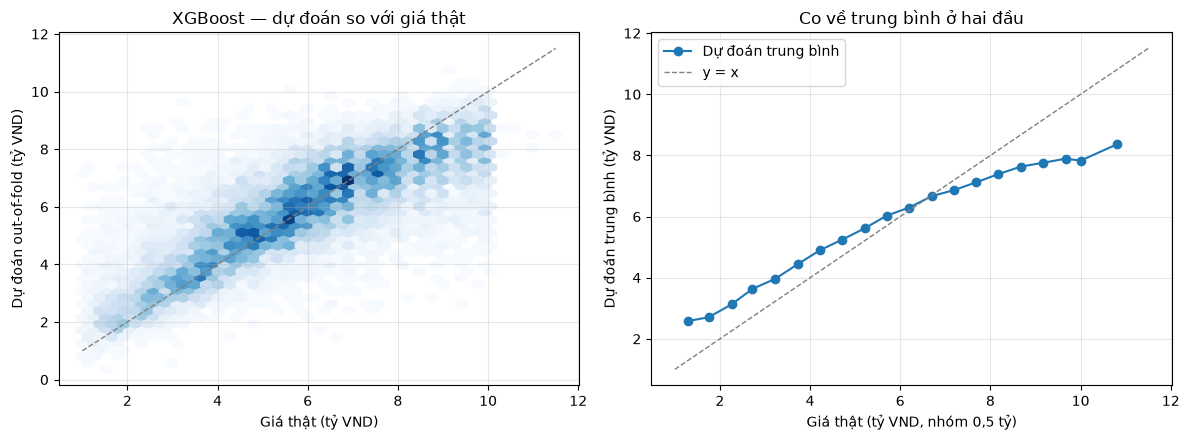

In [22]:
# C56 — Lỗi XGBoost theo nhóm (dự đoán out-of-fold, không train)
assert "v2_choice" in globals(), "Chạy C55 trước."

xgb_error_source = v2_choice["XGBoost"]
xgb_oof = load_oof_predictions(V2_GROUP, xgb_error_source)
assert xgb_oof["row_id"].equals(train_df["row_id"])

error_frame = X_train.copy()
error_frame.insert(0, "row_id", train_df["row_id"].to_numpy())
error_frame["actual_price"] = y_train.to_numpy()
error_frame["predicted_price"] = xgb_oof["predicted_price"].to_numpy()
error_frame["error"] = error_frame["predicted_price"] - error_frame["actual_price"]
error_frame["abs_error"] = error_frame["error"].abs()
error_frame["price_group"] = pd.cut(
    error_frame["actual_price"], bins=[-np.inf, 3, 5, 7, 9, np.inf],
    labels=["<3", "3–<5", "5–<7", "7–<9", "≥9"], right=False,
)
error_frame["area_group"] = pd.cut(
    error_frame["Area"], bins=[-np.inf, 50, 80, 120, 200, np.inf],
    labels=["<50", "50–<80", "80–<120", "120–<200", "≥200"], right=False,
)
for column in ["City", "District"]:
    error_frame[column] = error_frame[column].map(normalize_location_name).fillna("Unknown")


def error_table(frame, columns, min_rows=1):
    table = (
        frame.groupby(columns, observed=True)
        .agg(
            n=("abs_error", "size"),
            mean_actual=("actual_price", "mean"),
            mean_predicted=("predicted_price", "mean"),
            MAE=("abs_error", "mean"),
            bias=("error", "mean"),
            total_abs_error=("abs_error", "sum"),
        )
        .reset_index()
    )
    table["error_share_pct"] = table.pop("total_abs_error") / frame["abs_error"].sum() * 100
    return table.loc[table["n"] >= min_rows]


print(f"Nguồn: {xgb_error_source}; MAE out-of-fold = {error_frame['abs_error'].mean():.4f} tỷ VND")
print("Giá trong train nằm trong", y_train.min(), "–", y_train.max(), "tỷ VND.")
print("\n1. Theo nhóm giá thật (bias = dự đoán − thật):")
display(error_table(error_frame, ["price_group"]).round(4))
print("\n2. Theo nhóm diện tích:")
display(error_table(error_frame, ["area_group"]).round(4))
print("\n3. Thành phố có ít nhất 30 dòng, MAE cao nhất:")
display(error_table(error_frame, ["City"], 30).sort_values("MAE", ascending=False).head(10).round(4))
print("\n4. Quận/huyện có ít nhất 30 dòng, MAE cao nhất:")
display(error_table(error_frame, ["City", "District"], 30).sort_values("MAE", ascending=False).head(10).round(4))

# Dự đoán trung bình theo từng mức giá thật: đường nằm ngang hơn y = x nghĩa là co về trung bình.
price_bins = pd.cut(error_frame["actual_price"], bins=np.arange(1, 12, 0.5), right=False)
calibration_curve = error_frame.groupby(price_bins, observed=True).agg(
    actual=("actual_price", "mean"), predicted=("predicted_price", "mean"), n=("abs_error", "size"),
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hexbin(error_frame["actual_price"], error_frame["predicted_price"], gridsize=40, cmap="Blues", mincnt=1)
axes[0].plot([1, 11.5], [1, 11.5], color="grey", linestyle="--", linewidth=1)
axes[0].set_xlabel("Giá thật (tỷ VND)")
axes[0].set_ylabel("Dự đoán out-of-fold (tỷ VND)")
axes[0].set_title("XGBoost — dự đoán so với giá thật")
axes[1].plot(calibration_curve["actual"], calibration_curve["predicted"], marker="o", label="Dự đoán trung bình")
axes[1].plot([1, 11.5], [1, 11.5], color="grey", linestyle="--", linewidth=1, label="y = x")
axes[1].set_xlabel("Giá thật (tỷ VND, nhóm 0,5 tỷ)")
axes[1].set_ylabel("Dự đoán trung bình (tỷ VND)")
axes[1].set_title("Co về trung bình ở hai đầu")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
# C57 — Đọc các mẫu sai nhiều nhất và kiểm tra nguyên nhân có thể (không train)
assert "error_frame" in globals(), "Chạy C56 trước."

location_counts = error_frame.groupby(["City", "District"])["row_id"].transform("size")
city_counts = error_frame.groupby("City")["row_id"].transform("size")
ADMIN_PREFIX = re.compile(r"^(quận|huyện|thị xã|thành phố|tp\.?)\s+\D", re.IGNORECASE)
CITY_ALIASES = {"tp. hcm", "tphcm", "tp hồ chí minh", "tp.hcm", "tp. hồ chí minh"}

error_frame["address"] = raw_df["Address"].iloc[error_frame["row_id"].to_numpy()].to_numpy()
error_frame["flag_rare_location"] = location_counts < 5
error_frame["flag_location_alias"] = (
    error_frame["City"].str.lower().isin(CITY_ALIASES)
    | error_frame["District"].str.match(ADMIN_PREFIX)
    | city_counts.lt(3)
)
error_frame["flag_extreme_area"] = ~error_frame["Area"].between(15, 400)
error_frame["flag_price_text"] = error_frame["address"].str.contains(r"(?i)giá\s*\d|\d\s*tỷ", regex=True)
error_frame["flag_no_ward"] = error_frame["Ward"].isna()

# Tin đăng trùng: cùng Address, Area và Price (các cột khác có thể khác nhau).
# Dòng đánh giá có bản trùng trong phần train của fold dễ đoán hơn,
# làm điểm CV của mọi model lạc quan; split ngẫu nhiên của test cũng vậy.
twin_key = (
    error_frame["address"].fillna("NA").astype(str) + " | "
    + error_frame["Area"].astype(str) + " | "
    + error_frame["actual_price"].astype(str)
)
cv_twin_mask = np.zeros(len(error_frame), dtype=bool)
for fit_idx, assessment_idx in rf_cv_splits:
    cv_twin_mask[assessment_idx] = (
        twin_key.iloc[assessment_idx].isin(set(twin_key.iloc[fit_idx])).to_numpy()
    )
error_frame["flag_twin_in_fold_train"] = cv_twin_mask
flag_columns = [c for c in error_frame.columns if c.startswith("flag_")]

top_errors = error_frame.nlargest(20, "abs_error")
display(top_errors[[
    "row_id", "address", "Area", "Floors", "Frontage", "Access Road",
    "actual_price", "predicted_price", "error", *flag_columns,
]].round(3))

# Các dấu hiệu có làm lỗi lớn hơn không? So MAE của nhóm có dấu hiệu với phần còn lại.
flag_rows = []
for flag in flag_columns:
    mask = error_frame[flag]
    flag_rows.append({
        "flag": flag,
        "rows": int(mask.sum()),
        "share_of_top_200_pct": error_frame.nlargest(200, "abs_error")[flag].mean() * 100,
        "MAE_with_flag": error_frame.loc[mask, "abs_error"].mean(),
        "MAE_without_flag": error_frame.loc[~mask, "abs_error"].mean(),
    })
display(pd.DataFrame(flag_rows).round(4))

# Quận trung tâm có giá thật rất thấp so với mặt bằng quận đó.
district_median = error_frame.groupby(["City", "District"])["actual_price"].transform("median")
low_in_expensive = (
    (district_median >= 8) & (error_frame["actual_price"] <= district_median / 3)
)
print(f"Dòng có giá ≤ 1/3 median của quận khi median quận ≥ 8 tỷ: {int(low_in_expensive.sum())}; "
      f"MAE nhóm này = {error_frame.loc[low_in_expensive, 'abs_error'].mean():.3f} tỷ VND.")
print(
        f"Dòng thuộc nhóm tin trùng (Address, Area, Price): {twin_key.duplicated(keep=False).mean():.1%}; "
        f"dòng đánh giá có bản trùng trong phần train của fold: {cv_twin_mask.mean():.1%}."
    )
print("Không xóa hay sửa dòng nào; các dấu hiệu chỉ dùng để đọc nguyên nhân.")

,row_id,address,Area,Floors,Frontage,Access Road,actual_price,predicted_price,error,flag_rare_location,flag_location_alias,flag_extreme_area,flag_price_text,flag_no_ward,flag_twin_in_fold_train
15203,15674,"Đường Phạm Văn Thuận, Phường Tam Hiệp, Biên Hò...",73.0,1.0,NaN,NaN,9.30,2.616,-6.684,False,False,False,False,False,False
4752,21431,"Đường Trạng Trình, Phường Lê Lợi, Sơn Tây, Hà Nội",200.0,1.0,7.0,8.0,9.90,3.324,-6.576,True,False,False,False,False,False
17597,13814,"Hẻm 39, Đường Vườn Chuối, Phường 4, Quận 3, Hồ...",60.0,3.0,NaN,NaN,2.35,8.750,6.400,False,False,False,False,False,False
5538,13080,"Dự án Sapa Garden Hills, Đường Điện Biên Phủ, ...",95.0,4.0,5.0,30.0,3.20,9.513,6.313,False,False,False,False,False,False
9872,12289,"Xã Tả Phìn, Sa Pa, Lào Cai",117.0,NaN,NaN,NaN,1.20,7.380,6.180,False,False,False,False,False,False
2617,14289,"Đường Hạ Long, Phường Bãi Cháy, Hạ Long, Quảng...",60.0,3.0,5.0,NaN,10.00,3.855,-6.145,False,False,False,False,False,False
603,3435,"Đường Trần Đại Nghĩa, Xã Tân Kiên, Bình Chánh...",105.6,2.0,4.8,6.0,1.10,7.170,6.070,False,False,False,False,False,False
664,23447,"Đường Trương Hán Siêu, Phường Phú Thủy, Phan T...",100.0,3.0,5.0,NaN,10.00,3.933,-6.067,False,False,False,False,False,False
1684,14088,"Hẻm 198, Đường Điện Biên Phủ, Phường 17, Bình ...",70.0,4.0,5.0,7.0,3.10,9.072,5.972,False,False,False,False,False,False
1228,11538,"Đường Bạch Đằng, Phường 24, Bình Thạnh, Hồ Chí...",66.0,3.0,NaN,5.0,2.80,8.689,5.889,False,False,False,False,False,False


,flag,rows,share_of_top_200_pct,MAE_with_flag,MAE_without_flag
0,flag_rare_location,268,7.5,1.8050,0.9705
1,flag_location_alias,158,2.5,1.4258,0.9789
2,flag_extreme_area,90,2.0,1.0467,0.9825
3,flag_price_text,1,0.0,3.2364,0.9827
4,flag_no_ward,123,0.0,1.1849,0.9814
5,flag_twin_in_fold_train,1496,1.0,0.6916,1.0090


Dòng có giá ≤ 1/3 median của quận khi median quận ≥ 8 tỷ: 5; MAE nhóm này = 2.452 tỷ VND.
Dòng thuộc nhóm tin trùng (Address, Area, Price): 11.1%; dòng đánh giá có bản trùng trong phần train của fold: 8.2%.
Không xóa hay sửa dòng nào; các dấu hiệu chỉ dùng để đọc nguyên nhân.


In [24]:
# C57a — Rà soát giá nghi sai đơn vị (không train; giá/m² chỉ dùng để rà soát, không làm feature)
assert "error_frame" in globals(), "Chạy C57 trước."

audit = error_frame[[
    "row_id", "address", "City", "District", "Area", "Floors",
    "actual_price", "predicted_price", "error", "abs_error",
]].copy()
# Triệu VND/m² đất; so với median của chính quận đó (chỉ quận có ≥ 30 dòng).
audit["price_per_m2"] = audit["actual_price"] * 1000 / audit["Area"]
district_size = audit.groupby(["City", "District"])["row_id"].transform("size")
district_ppm2 = audit.groupby(["City", "District"])["price_per_m2"].transform("median")
audit["ppm2_vs_district"] = audit["price_per_m2"] / district_ppm2
reliable_district = district_size >= 30

audit_flags = {
    "giá/m² < 1/3 median quận": reliable_district & audit["ppm2_vs_district"].lt(1 / 3),
    "giá/m² > 3 lần median quận": reliable_district & audit["ppm2_vs_district"].gt(3),
    "Area < 15 m²": audit["Area"].lt(15),
    "Area > 400 m²": audit["Area"].gt(400),
    "giá ở mức sàn 1,0 tỷ": audit["actual_price"].le(1.0),
    "giá ở mức trần ≥ 11 tỷ": audit["actual_price"].ge(11),
}
audit_rows = []
for name, mask in audit_flags.items():
    audit_rows.append({
        "dấu hiệu": name,
        "rows": int(mask.sum()),
        "MAE": audit.loc[mask, "abs_error"].mean(),
        "bias": audit.loc[mask, "error"].mean(),
        "share_of_top_200_pct": audit.nlargest(200, "abs_error").index.isin(audit.index[mask]).mean() * 100,
    })
display(pd.DataFrame(audit_rows).round(4))

any_flag = np.logical_or.reduce([mask.to_numpy() for mask in audit_flags.values()])
print(
    f"Dòng có ít nhất một dấu hiệu: {any_flag.sum()} ({any_flag.mean():.1%}). "
    f"R² out-of-fold: toàn bộ = {r2_score(audit['actual_price'], audit['predicted_price']):.4f}; "
    f"không tính các dòng này = {r2_score(audit.loc[~any_flag, 'actual_price'], audit.loc[~any_flag, 'predicted_price']):.4f} "
    "(chỉ để đọc mức ảnh hưởng, không loại dòng nào)."
)

print("\nVí dụ giá/m² rất thấp so với quận:")
display(audit.loc[audit_flags["giá/m² < 1/3 median quận"]].nsmallest(8, "ppm2_vs_district")[[
    "address", "Area", "Floors", "actual_price", "predicted_price", "price_per_m2", "ppm2_vs_district",
]].round(3))
print("Ví dụ giá/m² rất cao so với quận:")
display(audit.loc[audit_flags["giá/m² > 3 lần median quận"]].nlargest(8, "ppm2_vs_district")[[
    "address", "Area", "Floors", "actual_price", "predicted_price", "price_per_m2", "ppm2_vs_district",
]].round(3))

,dấu hiệu,rows,MAE,bias,share_of_top_200_pct
0,giá/m² < 1/3 median quận,130,2.7458,2.5207,15.0
1,giá/m² > 3 lần median quận,21,3.3374,-3.2710,3.5
2,Area < 15 m²,41,0.7469,0.2707,0.0
3,Area > 400 m²,49,1.2976,0.0770,2.0
4,"giá ở mức sàn 1,0 tỷ",6,0.5268,0.5268,0.0
5,giá ở mức trần ≥ 11 tỷ,1,2.9554,-2.9554,0.0


Dòng có ít nhất một dấu hiệu: 238 (1.3%). R² out-of-fold: toàn bộ = 0.6421; không tính các dòng này = 0.6519 (chỉ để đọc mức ảnh hưởng, không loại dòng nào).

Ví dụ giá/m² rất thấp so với quận:


,address,Area,Floors,actual_price,predicted_price,price_per_m2,ppm2_vs_district
6818,"Xã Vĩnh Trung, Nha Trang, Khánh Hòa",228.0,1.0,1.35,2.759,5.921,0.100
2719,"Đường Đinh Đức Thiện, Xã Bình Chánh, Bình Chán...",250.0,NaN,2.30,5.701,9.200,0.128
11924,"Xã Tân Tiến, Chương Mỹ, Hà Nội",539.0,NaN,4.20,4.847,7.792,0.129
8056,"Xã Vĩnh Phương, Nha Trang, Khánh Hòa",190.0,1.0,1.60,3.342,8.421,0.142
603,"Đường Trần Đại Nghĩa, Xã Tân Kiên, Bình Chánh...",105.6,2.0,1.10,7.170,10.417,0.145
16638,"Xã Tiên Phương, Chương Mỹ, Hà Nội",420.0,NaN,3.80,3.975,9.048,0.150
2546,"Thôn Đông, Xã Vĩnh Phương, Nha Trang, Khánh Hòa",178.6,2.0,1.60,1.887,8.959,0.151
2102,"Đường Lê Cơ, Phường An Lạc, Bình Tân, Hồ Chí Minh",523.5,1.0,7.00,8.607,13.372,0.153


Ví dụ giá/m² rất cao so với quận:


,address,Area,Floors,actual_price,predicted_price,price_per_m2,ppm2_vs_district
16861,"Đường Đinh Tiên Hoàng, Phường Tự An, Buôn Ma T...",4.0,3.0,6.4,2.696,1600.000,48.696
1144,"Đường Ninh Tốn, Thị trấn Củ Chi, Củ Chi, Hồ Ch...",90.0,2.0,9.6,7.155,106.667,6.476
6192,"Đường Giáp Hải, Xã Tân An Hội, Củ Chi, Hồ Chí ...",109.2,NaN,8.8,2.920,80.586,4.893
11751,"Đường Giáp Hải, Xã Tân An Hội, Củ Chi, Hồ Chí ...",124.6,2.0,9.6,7.107,77.047,4.678
5098,"Đường Giáp Hải, Xã Tân An Hội, Củ Chi, Hồ Chí ...",79.8,2.0,5.8,6.497,72.682,4.413
13545,"Đường Phan Đình Phùng, Phường Quang Vinh, Biên...",60.0,4.0,10.0,5.240,166.667,4.176
9115,"Đường Đinh Tiên Hoàng, Phường Tự An, Buôn Ma T...",47.3,3.0,6.4,5.042,135.307,4.118
17811,"Đường Nguyễn Thị Minh Khai, Phường Phước Hòa, ...",27.0,2.0,6.2,4.737,229.630,3.859


### Nhận xét — Lỗi của XGBoost

**XGBoost gặp đúng tình trạng của RF (C07).** Nhà dưới 3 tỷ bị dự đoán cao trung bình +0,95 tỷ, nhà từ 9 tỷ trở lên bị dự đoán thấp −1,71 tỷ. Nhóm ≥ 9 tỷ chỉ chiếm 9,8% số dòng nhưng chiếm 17% tổng sai số tuyệt đối. Nhãn trong dữ liệu bị giới hạn trong khoảng 1–11,5 tỷ, nên khi thiếu thông tin, model co dự đoán về giữa; đường dự đoán trung bình (C56) nằm ngang hơn y = x ở cả hai đầu. MAE cũng tăng theo diện tích (≥ 200 m²: 1,52 tỷ) và cao ở các vùng ít dữ liệu, giá phân tán (Củ Chi, Đà Lạt, Lâm Đồng).

**Đọc 20 mẫu sai nhiều nhất (C57)** thấy bốn nhóm nguyên nhân:
1. **Nhãn mâu thuẫn:** cùng một căn được đăng nhiều lần với giá khác nhau. Ví dụ Sapa Garden Hills, 95 m², 4 tầng, 8 phòng ngủ, có tin 3,2 tỷ và có tin 9,5 tỷ. Model không thể đúng cả hai.
2. **Giá thấp bất thường ở quận đắt:** Quận 1, Quận 3, Bình Thạnh, 50–70 m², 3–4 tầng mà giá 2,3–3,1 tỷ, trong khi median của quận là 6,7–7,2 tỷ. Có thể là sai đơn vị, giá thuê/đặt cọc, hoặc tin sai; dữ liệu không đủ để khẳng định.
3. **Giá cao ở khu rẻ:** Biên Hòa, Sơn Tây, Bãi Cháy, Phan Thiết, giá 9–10 tỷ. Có thể là nhà mặt đường lớn hoặc dùng để kinh doanh; feature hiện có không mô tả được.
4. **Thiếu thông tin vị trí và căn nhà:**
   - Địa danh hiếm (< 5 dòng): MAE 1,81 so với 0,97.
   - Tên địa phương viết khác, ví dụ "TP. HCM", "quận Tân Bình": MAE 1,43 so với 0,98.
   - Nhiều mẫu sai lớn thiếu Floors/Bedrooms.

**Tin đăng trùng:** 11,1% dòng train thuộc nhóm trùng (cùng Address, Area, Price). 8,2% dòng đánh giá có bản trùng trong phần train của fold và dễ đoán hơn hẳn, nên điểm CV của mọi model hơi lạc quan.

**Rà soát giá nghi sai đơn vị (C57a).** Giá/m² chỉ dùng để rà soát, không đưa vào model. So với median giá/m² của chính quận đó (chỉ xét quận có ≥ 30 dòng):

- **130 dòng có giá/m² < 1/3 mặt bằng quận:** MAE 2,75; bị dự đoán cao +2,52 tỷ; chiếm 15% trong 200 lỗi lớn nhất. Phần lớn là lô đất lớn ở **xã** ngoại thành (xã thuộc Nha Trang, Bình Chánh, Chương Mỹ): rẻ thật so với phường nội thành, không hẳn sai đơn vị. Đây đúng loại lỗi feature phường giải quyết được. Một số dòng vẫn đáng ngờ, ví dụ 105,6 m², 2 tầng ở Bình Chánh giá 1,1 tỷ.
- **21 dòng có giá/m² > 3 lần mặt bằng quận:** có ít nhất một lỗi đơn vị gần như chắc chắn — nhà 3 tầng ghi **Area = 4 m²**, giá 6,4 tỷ (Buôn Ma Thuột). Nhiều dòng khác là cùng một nhóm tin (ba tin đường Giáp Hải, Củ Chi).
- Area < 15 m² (41 dòng) không làm model sai nhiều (MAE 0,75). Chỉ 6 dòng ở mức sàn 1,0 tỷ và 1 dòng ≥ 11 tỷ.
- Có 238 dòng (1,3%) mang ít nhất một dấu hiệu. Không tính các dòng này, R² out-of-fold tăng từ 0,642 lên 0,652. Đây chỉ là con số đo ảnh hưởng; không dòng nào bị loại.

Không xóa hay sửa mẫu nào. Nhóm 1–2 cần nhóm dữ liệu quyết định cách xử lý (kiểm tra nguồn, gộp tin trùng), không nên quyết bằng sai số của model. Nhóm 3–4 gợi ý feature vị trí chi tiết hơn, được thử ở C58.

## 16. Feature engineering theo giả thuyết — vị trí và đặc điểm căn nhà

Mỗi block được thử riêng trên cấu hình missing đã chọn ở C55 (đối chứng), rồi quyết định theo quy tắc Phần B. Nếu từ hai block được nhận thì thử thêm tổ hợp.

| Block | Feature | Giả thuyết / ý nghĩa |
|---|---|---|
| `location_te` | Target Encoding của City và City_District | Mức giá khu vực dạng số; ở Phần A giúp LightGBM, chưa giúp XGBoost |
| `ward_te` | Target Encoding của City_District_Ward | Giá chênh nhiều giữa các phường trong cùng quận; Address có phường/xã cho hầu hết dòng (C53) |
| `project_te` | Target Encoding của City_Project | Nhà trong dự án có mặt bằng giá riêng; chỉ khoảng 12% dòng có tên dự án |
| `area_x_location` | Area × mức giá City_District | Tác động của diện tích lên giá phụ thuộc vị trí; đưa sẵn tương tác thay vì để cây tự tìm |
| `floor_area` | Area × Floors | **Chỉ là tích số**: Area là diện tích đất/sàn đăng tin, tầng có thể không phủ toàn bộ diện tích, nên không phải diện tích sử dụng thực tế |
| `room_density` | (Bedrooms + Bathrooms) / Area | Nhiều phòng trên diện tích nhỏ thường là nhà xây kín hoặc nhà cho thuê; thiếu phòng thì feature thiếu |
| `log_area` | log(Area) thay Area | Với model cây, biến đổi đơn điệu gần như không đổi cách chia; kỳ vọng thay đổi rất nhỏ — dùng để kiểm chứng |

Cột `MAE_gain_no_twin_pct` ở C59 tính lại mức cải thiện chỉ trên các dòng không có tin trùng trong phần train của fold, để kiểm tra feature vị trí chi tiết (phường, dự án) có "nhớ" giá của tin trùng hay không.

Target Encoding học trong phần train của fold, cross-fitting 5 fold nội bộ; không feature nào dùng Price của chính dòng đó. Không dùng Price/Area làm feature. Phường/dự án chưa có ô nhập trong app hiện tại; nếu được chọn thì app phải bổ sung.

In [25]:
# C58 — Chạy từng block FE trên cấu hình missing đã chọn
assert "v2_choice" in globals(), "Chạy C55 trước."

V2_FE_BLOCKS = [
    "location_te", "ward_te", "project_te", "area_x_location",
    "floor_area", "room_density", "log_area",
]
v2_fe_control = dict(v2_choice)
for model_name in V2_MODELS:
    base_blocks = v2_runs[v2_fe_control[model_name]]["blocks"]
    for block in V2_FE_BLOCKS:
        run_v2(f"{model_name}_v2_{block}", model_name, base_blocks + [block])

display(v2_summary([
    name for model_name in V2_MODELS
    for name in [v2_fe_control[model_name], *[f"{model_name}_v2_{b}" for b in V2_FE_BLOCKS]]
]).round(6))


XGBoost_v2_location_te


  Fold 1: đọc lại, MAE=0.995642


  Fold 2: đọc lại, MAE=0.990028


  Fold 3: đọc lại, MAE=0.980026



XGBoost_v2_ward_te


...


LightGBM_v2_log_area


  Fold 1: đọc lại, MAE=1.006959


  Fold 2: đọc lại, MAE=0.994325


  Fold 3: đọc lại, MAE=0.994551


,model,blocks,mean_train_MAE,mean_cv_MAE,std_cv_MAE,mean_cv_RMSE,mean_cv_R2,mean_MAE_gap,mean_selected_trees,limit_hit_folds,mean_fit_seconds
0,XGBoost_v2_median,median,0.493299,0.982824,0.004811,1.324574,0.641940,0.489525,1104.000000,0,57.127989
1,XGBoost_v2_location_te,location_te,0.625175,0.988565,0.006459,1.322105,0.643276,0.363390,600.000000,0,19.389443
2,XGBoost_v2_ward_te,ward_te,0.578488,0.938272,0.006051,1.269788,0.670993,0.359784,776.000000,0,21.721757
3,XGBoost_v2_project_te,project_te,0.586888,0.975434,0.004902,1.306427,0.651702,0.388546,882.333333,0,24.337999
4,XGBoost_v2_area_x_location,area_x_location,0.568744,0.987028,0.006218,1.327070,0.640612,0.418284,777.666667,0,23.696636
5,XGBoost_v2_floor_area,floor_area,0.522608,0.984687,0.006571,1.325216,0.641580,0.462078,927.333333,0,22.379193
6,XGBoost_v2_room_density,room_density,0.512053,0.990075,0.004345,1.327427,0.640435,0.478022,950.333333,0,25.606561
7,XGBoost_v2_log_area,log_area,0.493299,0.982824,0.004811,1.324574,0.641940,0.489525,1104.000000,0,31.129230
8,LightGBM_v2_native,fa_native,0.654553,0.993600,0.002583,1.327014,0.640643,0.339047,565.000000,0,24.928791
9,LightGBM_v2_location_te,fa_native+location_te,0.741889,0.998390,0.005732,1.329389,0.639364,0.256501,415.666667,0,32.065682


In [26]:
# C59 — Nhận/loại từng block (kiểm tra 3 seed nếu cần) và thử tổ hợp
assert "v2_fe_control" in globals(), "Chạy C58 trước."

assert "cv_twin_mask" in globals(), "Chạy C57 trước."


def gain_without_twins(control_name, candidate_name):
    """Mức giảm MAE (%) chỉ trên dòng không có tin trùng trong phần train của fold."""
    errors = {
        name: (frame["predicted_price"] - frame["actual_price"]).abs().to_numpy()[~cv_twin_mask]
        for name, frame in [
            (control_name, load_oof_predictions(V2_GROUP, control_name)),
            (candidate_name, load_oof_predictions(V2_GROUP, candidate_name)),
        ]
    }
    control_mae = errors[control_name].mean()
    return (control_mae - errors[candidate_name].mean()) / control_mae * 100


v2_fe_decisions = {}
for model_name in V2_MODELS:
    control = v2_fe_control[model_name]
    decisions = decide_v2(control, [f"{model_name}_v2_{b}" for b in V2_FE_BLOCKS])
    # Đọc thêm: lợi ích có đến từ tin đăng trùng không (không dùng trong quy tắc).
    decisions["MAE_gain_no_twin_pct"] = [
        gain_without_twins(control, name) for name in decisions["candidate"]
    ]
    print(f"\n{model_name} — so với {control}:")
    display(decisions.round(6))
    accepted = decisions.loc[decisions["accepted"], "candidate"].tolist()

    candidates = list(accepted)
    if len(accepted) >= 2:
        blocks = sorted({b for name in accepted for b in v2_runs[name]["blocks"]})
        combined = f"{model_name}_v2_" + "__".join(b for b in blocks if b in V2_FE_BLOCKS)
        run_v2(combined, model_name, blocks)
        combined_decision = decide_v2(control, [combined])
        display(combined_decision.round(6))
        if combined_decision["accepted"].iloc[0]:
            candidates.append(combined)

    v2_fe_decisions[model_name] = decisions
    v2_choice[model_name] = (
        min(candidates, key=lambda n: v2_runs[n]["folds"]["cv_MAE"].mean())
        if candidates else control
    )
    print(f"{model_name}: dùng {v2_choice[model_name]} — blocks {v2_runs[v2_choice[model_name]]['blocks']}")

  XGBoost_v2_median_seed7


  Fold 1: đọc lại, MAE=0.988249


  Fold 2: đọc lại, MAE=0.983445


  Fold 3: đọc lại, MAE=0.978865


  XGBoost_v2_median_seed2026


...

  Fold 1: đọc lại, MAE=0.940501


  Fold 2: đọc lại, MAE=0.928677


  Fold 3: đọc lại, MAE=0.925649


,candidate,MAE_control,MAE_candidate,MAE_gain_pct,folds_won,RMSE_change,R2_change,seed_check,accepted
0,LightGBM_v2_project_te__ward_te,0.9936,0.93398,6.000449,3,-0.064796,0.036529,"MAE 3 seed +6.438%, thắng 3/3 seed",True


LightGBM: dùng LightGBM_v2_project_te__ward_te — blocks ['fa_native', 'project_te', 'ward_te']


### Nhận xét — Feature theo giả thuyết

| Block | XGBoost: MAE (3 seed) | LightGBM: MAE (3 seed) | Kết luận |
|---|---|---|---|
| `ward_te` — phường/xã từ Address | −4,53% (−4,69%), R² +0,027 | −5,12% (−5,31%), R² +0,029 | Nhận |
| `project_te` — dự án từ Address | −0,75% (−0,64%), R² +0,008 | −0,95% (−1,34%), R² +0,010 | Nhận |
| Tổ hợp phường + dự án | **−5,42% (−5,26%), R² +0,031** | **−6,00% (−6,44%), R² +0,037** | **Chọn** |
| `location_te` — City, City_District | +0,58% | +0,48% | Loại |
| `area_x_location` | +0,43% | +0,08% | Loại |
| `floor_area` — Area × Floors | +0,19% | +0,55% | Loại |
| `room_density` | +0,74% | +0,84% | Loại |
| `log_area` | 0,00% (giống hệt) | +0,50% | Loại |

(Số dương ở cột MAE nghĩa là MAE tăng, tức xấu hơn.)

- **Vị trí chi tiết là nguồn cải thiện lớn nhất từ đầu notebook.** Đúng như góp ý, gộp Address thành City/District đã làm mất thông tin phường; thêm lại phường giảm MAE khoảng 5%. Lợi ích không đến từ tin trùng: tính riêng trên dòng không có bản trùng trong phần train của fold (`MAE_gain_no_twin_pct`), mức giảm vẫn khoảng 4,5–5,5%.
- Mã hóa City/City_District thành số không giúp thêm khi One-Hot đã có hai cột này. Ở Phần A nó giúp LightGBM, nhưng trên v2 với tham số mới thì không.
- `log_area` cho XGBoost kết quả giống hệt `median`, xác nhận model cây không bị ảnh hưởng bởi biến đổi đơn điệu. LightGBM thay đổi nhẹ vì cách chia bin quanh giá trị 0 sau khi scale.
- Area × Floors không giúp. Khớp với lưu ý của góp ý: tích này không phải diện tích sử dụng (Floors thiếu 12%, tầng không nhất thiết phủ hết diện tích). Mật độ phòng cũng không giúp.
- C59a thử thêm **đường** (phần còn lại góp ý nêu) trên cấu hình này.
- **Hệ quả cho app:** cấu hình chọn cần phường/xã, tên đường (C59a) và tên dự án nếu có làm đầu vào. App hiện chỉ có City/District nên phải bổ sung ô nhập; nếu không có phường, dùng cấu hình của C55 (MAE CV khoảng 0,98 so với 0,92, tức cao hơn khoảng 6%).

### Feature đường (bổ sung theo góp ý)

Góp ý nêu ba phần địa chỉ bị mất: phường, đường, dự án. C58–C59 đã thử phường và dự án. C59a thử **đường**: lấy phần đứng ngay trước phường/xã trong Address (bắt đầu bằng Đường, Phố, Quốc lộ, Tỉnh lộ, Đại lộ), mã hóa City_District_Street bằng Target Encoding học trong fold.

**Giả thuyết:** trong cùng một phường, nhà trên trục đường lớn hoặc đường thương mại có giá khác nhà trong khu dân cư. Tên đường có thể mang thông tin mà phường chưa có.

Có 3.839 khóa đường nhưng chỉ khoảng 350 khóa có ≥ 10 dòng, nên phần lớn mã hóa sẽ co về mức trung bình (smoothing). Thử hai cách, cùng quy tắc Phần B:
1. Đường riêng, so với đối chứng của C58.
2. Đường thêm vào cấu hình đã chọn ở C59 (phường + dự án).

In [27]:
# C59a — Feature đường: riêng và thêm vào cấu hình phường + dự án
assert "v2_fe_decisions" in globals(), "Chạy C59 trước."

v2_street_decisions = {}
for model_name in V2_MODELS:
    base_control = v2_fe_control[model_name]
    chosen = v2_choice[model_name]
    street_only = f"{model_name}_v2_street_te"
    with_street = f"{chosen}__street_te"
    run_v2(street_only, model_name, v2_runs[base_control]["blocks"] + ["street_te"])
    run_v2(with_street, model_name, v2_runs[chosen]["blocks"] + ["street_te"])

    parts = []
    for control, candidate in [(base_control, street_only), (chosen, with_street)]:
        decision = decide_v2(control, [candidate])
        decision.insert(1, "control", control)
        decision["MAE_gain_no_twin_pct"] = [gain_without_twins(control, candidate)]
        parts.append(decision)
    decisions = pd.concat(parts, ignore_index=True)
    print(f"\n{model_name}:")
    display(decisions.round(6))
    v2_street_decisions[model_name] = decisions

    if decisions.loc[decisions["candidate"].eq(with_street), "accepted"].iloc[0]:
        v2_choice[model_name] = with_street
    print(f"{model_name}: dùng {v2_choice[model_name]} — blocks {v2_runs[v2_choice[model_name]]['blocks']}")


XGBoost_v2_street_te


  Fold 1: đọc lại, MAE=0.961305


  Fold 2: đọc lại, MAE=0.955857


  Fold 3: đọc lại, MAE=0.963703



XGBoost_v2_project_te__ward_te__street_te


...

  Fold 2: đọc lại, MAE=0.916243


  Fold 3: đọc lại, MAE=0.932726



LightGBM:


,candidate,control,MAE_control,MAE_candidate,MAE_gain_pct,folds_won,RMSE_change,R2_change,seed_check,accepted,MAE_gain_no_twin_pct
0,LightGBM_v2_street_te,LightGBM_v2_native,0.99360,0.964308,2.948053,3,-0.029596,0.017609,"MAE 3 seed +3.311%, thắng 3/3 seed",True,2.324681
1,LightGBM_v2_project_te__ward_te__street_te,LightGBM_v2_project_te__ward_te,0.93398,0.925978,0.856732,3,-0.007586,0.003049,"MAE 3 seed +0.731%, thắng 3/3 seed",True,0.541941


LightGBM: dùng LightGBM_v2_project_te__ward_te__street_te — blocks ['fa_native', 'project_te', 'street_te', 'ward_te']


### Nhận xét — Feature đường

| Thử | XGBoost: MAE (3 seed) | LightGBM: MAE (3 seed) | Trên dòng không có tin trùng |
|---|---|---|---|
| Đường riêng, so với đối chứng C58 | −2,29% (−2,52%), R² +0,017 | −2,95% (−3,31%), R² +0,018 | −1,78% / −2,32% |
| Đường thêm vào phường + dự án | −0,52% (−0,90%), R² +0,004 | −0,86% (−0,73%), R² +0,003 | **−0,10%** / −0,54% |

- Đường dùng riêng mang nhiều thông tin, nhưng phần lớn đã có trong phường. Thêm vào phường + dự án chỉ giảm MAE thêm khoảng 0,5–0,9%; cả hai model đều qua quy tắc (thắng 3/3 seed, R² không giảm), nên được nhận.
- **Cần lưu ý:** với XGBoost, trên các dòng không có tin trùng, lợi ích chỉ còn 0,10%. Khóa đường rất chi tiết (3.655 khóa, chỉ 354 khóa có ≥ 10 dòng), nên một phần lợi ích đến từ việc "nhớ" giá của tin đăng trùng cùng con đường. LightGBM giữ được 0,54%. Nếu nhóm quyết định chia tập theo nhóm tin trùng (xem kết luận), nên kiểm tra lại feature này trước tiên.
- App cần thêm ô nhập tên đường, bên cạnh phường/xã và dự án.

## 17. Chọn theo MAE hay theo RMSE/R²; thử log-price

Đến đây mọi lựa chọn dùng MAE. Mục tiêu dự án đo bằng R², tương đương với MSE trên cùng một tập: R² = 1 − MSE / Var(y). Cấu hình tốt nhất theo MAE chưa chắc tốt nhất theo MSE, vì MAE ít phạt lỗi lớn hơn MSE.

- **C60 (không train):** trên mỗi lượt tìm kiếm đã lưu, so cấu hình được chọn theo MAE, theo RMSE và theo R² trên cùng các fold.
- **C61 (train):** với cấu hình chọn ở C59, thử (a) early stopping theo RMSE thay vì MAE, (b) train trên log(Price) rồi đổi dự đoán về giá gốc bằng exp trước khi tính MAE/RMSE/R².

In [28]:
# C60 — Cấu hình chọn theo MAE, RMSE và R² trên cùng các fold (không train)
assert "v2_choice" in globals(), "Chạy C59 trước."


def pick_by_metric(source, folds, id_column):
    means = folds.groupby(id_column)[["cv_MAE", "cv_RMSE", "cv_R2"]].mean()
    picks = {
        "MAE": means["cv_MAE"].idxmin(),
        "RMSE": means["cv_RMSE"].idxmin(),
        "R2": means["cv_R2"].idxmax(),
    }
    rows = []
    for criterion, picked in picks.items():
        rows.append({
            "source": source, "criterion": criterion, "picked": picked,
            "same_as_MAE_pick": picked == picks["MAE"],
            **means.loc[picked].to_dict(),
        })
    return rows


metric_rows = []
for source, folder, n_candidates in [
    ("LightGBM grid lượt 1 (v1)", "lightgbm_grid_search", 36),
    ("XGBoost grid lượt 1 (v1)", "xgboost_grid_search", 36),
    ("CatBoost grid lượt 1 (v1)", "catboost_grid_search", 27),
]:
    folds = pd.read_csv(EXPERIMENT_DIR / folder / "round1_fold_results.csv")
    assert folds["candidate_id"].nunique() == n_candidates
    metric_rows += pick_by_metric(source, folds, "candidate_id")

for model_name in ROUND2_GRIDS:
    names = [n for n, meta in round2_meta.items() if meta["model"] == model_name]
    folds = pd.concat([round2_folds[n].assign(config=n) for n in names])
    metric_rows += pick_by_metric(f"{model_name} tuning lượt 2 (v1)", folds, "config")

for model_name in V2_MODELS:
    names = [n for n, run in v2_runs.items() if run["model"] == model_name]
    folds = pd.concat([v2_runs[n]["folds"].assign(config=n) for n in names])
    metric_rows += pick_by_metric(f"{model_name} Phần B (v2)", folds, "config")

metric_picks = pd.DataFrame(metric_rows)
display(metric_picks.round(6))

disagreements = metric_picks.loc[~metric_picks["same_as_MAE_pick"]]
print(f"Số lượt tìm kiếm mà RMSE/R² chọn khác MAE: "
      f"{disagreements['source'].nunique()}/{metric_picks['source'].nunique()}")
if not disagreements.empty:
    loss_rows = []
    for source, group in metric_picks.groupby("source", sort=False):
        mae_pick = group.loc[group["criterion"].eq("MAE")].iloc[0]
        r2_pick = group.loc[group["criterion"].eq("R2")].iloc[0]
        loss_rows.append({
            "source": source,
            "R2_lost_by_choosing_MAE": r2_pick["cv_R2"] - mae_pick["cv_R2"],
            "MAE_lost_by_choosing_R2": r2_pick["cv_MAE"] - mae_pick["cv_MAE"],
        })
    print("Mức đánh đổi giữa hai cách chọn:")
    display(pd.DataFrame(loss_rows).round(6))

,source,criterion,picked,same_as_MAE_pick,cv_MAE,cv_RMSE,cv_R2
0,LightGBM grid lượt 1 (v1),MAE,27,True,1.012007,1.348392,0.628999
1,LightGBM grid lượt 1 (v1),RMSE,26,False,1.012847,1.347719,0.629376
2,LightGBM grid lượt 1 (v1),R2,26,False,1.012847,1.347719,0.629376
3,XGBoost grid lượt 1 (v1),MAE,13,True,0.986403,1.325621,0.641410
4,XGBoost grid lượt 1 (v1),RMSE,7,False,0.988552,1.322597,0.643052
5,XGBoost grid lượt 1 (v1),R2,7,False,0.988552,1.322597,0.643052
6,CatBoost grid lượt 1 (v1),MAE,24,True,1.025735,1.354842,0.625408
7,CatBoost grid lượt 1 (v1),RMSE,24,True,1.025735,1.354842,0.625408
8,CatBoost grid lượt 1 (v1),R2,24,True,1.025735,1.354842,0.625408
9,XGBoost tuning lượt 2 (v1),MAE,XGBoost_r2_c01,True,0.982611,1.319123,0.644910


Số lượt tìm kiếm mà RMSE/R² chọn khác MAE: 2/7
Mức đánh đổi giữa hai cách chọn:


,source,R2_lost_by_choosing_MAE,MAE_lost_by_choosing_R2
0,LightGBM grid lượt 1 (v1),0.000377,0.000840
1,XGBoost grid lượt 1 (v1),0.001642,0.002149
2,CatBoost grid lượt 1 (v1),0.000000,0.000000
3,XGBoost tuning lượt 2 (v1),0.000000,0.000000
4,LightGBM tuning lượt 2 (v1),0.000000,0.000000
5,XGBoost Phần B (v2),0.000000,0.000000
6,LightGBM Phần B (v2),0.000000,0.000000


In [29]:
# C61 — Early stopping theo RMSE và log-price trên cấu hình C59
assert "v2_street_decisions" in globals(), "Chạy C59a trước."

RMSE_STOPPING = {"xgb": {"eval_metric": "rmse"}, "lgb": {"metric": "rmse"}}
v2_metric_decisions = {}
for model_name in V2_MODELS:
    reference = v2_choice[model_name]
    run = v2_runs[reference]
    stop_rmse = f"{reference}__stop_rmse"
    log_price = f"{reference}__log_price"
    run_v2(stop_rmse, model_name, run["blocks"],
           params={**run["params"], **RMSE_STOPPING[run["family"]]})
    run_v2(log_price, model_name, run["blocks"], params=run["params"], target_transform="log")

    decisions = decide_v2(reference, [stop_rmse, log_price])
    print(f"\n{model_name} — so với {reference}:")
    display(v2_summary([reference, stop_rmse, log_price]).round(6))
    display(decisions.round(6))
    v2_metric_decisions[model_name] = decisions

    # Ghi nhận riêng: biến thể tăng R² nhưng không qua quy tắc MAE.
    for row in decisions.itertuples():
        if not row.accepted and row.R2_change > 0:
            print(f"  {row.candidate}: R² {row.R2_change:+.4f} nhưng MAE {row.MAE_gain_pct:+.3f}% — không nhận theo quy tắc hiện tại.")

    accepted = decisions.loc[decisions["accepted"], "candidate"].tolist()
    if accepted:
        v2_choice[model_name] = min(accepted, key=lambda n: v2_runs[n]["folds"]["cv_MAE"].mean())
    print(f"{model_name}: cấu hình cuối Phần B = {v2_choice[model_name]}")


XGBoost_v2_project_te__ward_te__street_te__stop_rmse


  Fold 1: đọc lại, MAE=0.932489


  Fold 2: đọc lại, MAE=0.916969


  Fold 3: đọc lại, MAE=0.923811



XGBoost_v2_project_te__ward_te__street_te__log_price


...

  Fold 3: đọc lại, MAE=0.926500



LightGBM — so với LightGBM_v2_project_te__ward_te__street_te:


,model,blocks,mean_train_MAE,mean_cv_MAE,std_cv_MAE,mean_cv_RMSE,mean_cv_R2,mean_MAE_gap,mean_selected_trees,limit_hit_folds,mean_fit_seconds
0,LightGBM_v2_project_te__ward_te__street_te,fa_native+project_te+street_te+ward_te,0.631511,0.925978,0.006943,1.254633,0.678811,0.294467,588.333333,0,45.294608
1,LightGBM_v2_project_te__ward_te__street_te__st...,fa_native+project_te+street_te+ward_te,0.661124,0.927328,0.007443,1.252248,0.680023,0.266204,412.666667,0,47.486080
2,LightGBM_v2_project_te__ward_te__street_te__lo...,fa_native+project_te+street_te+ward_te,0.650456,0.929888,0.004919,1.274526,0.668515,0.279431,516.000000,0,54.851188


,candidate,MAE_control,MAE_candidate,MAE_gain_pct,folds_won,RMSE_change,R2_change,seed_check,accepted
0,LightGBM_v2_project_te__ward_te__street_te__st...,0.925978,0.927328,-0.145773,0,-0.002385,0.001213,—,False
1,LightGBM_v2_project_te__ward_te__street_te__lo...,0.925978,0.929888,-0.422214,1,0.019894,-0.010296,—,False


  LightGBM_v2_project_te__ward_te__street_te__stop_rmse: R² +0.0012 nhưng MAE -0.146% — không nhận theo quy tắc hiện tại.
LightGBM: cấu hình cuối Phần B = LightGBM_v2_project_te__ward_te__street_te


### Nhận xét — Chọn theo MAE hay theo RMSE/R²

- **C60:** trong 7 lượt tìm kiếm, chọn theo RMSE/R² cho cấu hình khác chọn theo MAE ở 2 lượt (grid lượt 1 của LightGBM và XGBoost). R² mất đi khi chọn theo MAE chỉ 0,0004 và 0,0016. Ở tuning lượt 2 và toàn bộ Phần B, ba tiêu chí chọn cùng một cấu hình.
- **Early stopping theo RMSE (C61):** gần như không đổi.
  - XGBoost: MAE −0,03%, chỉ thắng 1/3 fold; R² +0,0001.
  - LightGBM: MAE +0,15%, R² +0,0012.
  - Không biến thể nào qua quy tắc.
- **log-price (C61):** dự đoán được đổi về giá gốc bằng exp trước khi chấm.
  - XGBoost: MAE +0,18%, **R² −0,008**.
  - LightGBM: MAE +0,42%, **R² −0,010**.
  - Ở lần chạy trước, trên cấu hình chỉ có phường + dự án, log-price giảm MAE của XGBoost 0,37% nhưng R² vẫn giảm khoảng 0,007. Train trên log luôn kéo dự đoán của nhà đắt xuống, đúng nhóm đang bị đoán thấp nhất (C56), nên R² giảm. Bị loại.
- **Thống nhất cách chọn:** giữ MAE làm metric quyết định (dễ diễn giải theo tỷ đồng), kèm điều kiện R² CV không giảm, và báo cáo cả MAE, RMSE, R². Với dữ liệu này, hai tiêu chí gần như luôn chọn cùng một cấu hình; trường hợp khác biệt có ý nghĩa (log-price) đã bị điều kiện R² chặn. Nhóm cần xác nhận quy tắc này là chuẩn chung.

In [30]:
# C62 — Cấu hình cuối của mỗi model trên v2 và tiến trình so với v1
assert "v2_metric_decisions" in globals(), "Chạy C61 trước."

final_cv_candidates = {}
for model_name, name in v2_choice.items():
    run = v2_runs[name]
    final_cv_candidates[model_name] = {
        "name": name,
        "family": run["family"],
        "params": run["params"],
        "blocks": run["blocks"],
        "group": V2_GROUP,
        "result_name": name,
        "folds": run["folds"],
        "make": make_preprocessing_v2,
        "describe": describe_preprocessing_v2,
        "target_transform": run["target_transform"],
    }

progress_rows = []
for model_name in V2_MODELS:
    steps = [
        ("v1 — cấu hình cuối Phần A (C47)", final_cv_candidates_v1[model_name]["folds"]),
        ("v2 — median trong fold (C55)", v2_runs[f"{model_name}_v2_median"]["folds"]),
        ("v2 — sau xử lý missing (C55)", v2_runs[v2_fe_control[model_name]]["folds"]),
        ("v2 — sau feature engineering và metric (C59–C61)", final_cv_candidates[model_name]["folds"]),
    ]
    for step, folds in steps:
        progress_rows.append({
            "model": model_name, "step": step,
            "cv_MAE": folds["cv_MAE"].mean(), "cv_RMSE": folds["cv_RMSE"].mean(),
            "cv_R2": folds["cv_R2"].mean(),
        })
display(pd.DataFrame(progress_rows).round(6))
for model_name, candidate in final_cv_candidates.items():
    print(f"{model_name}: {candidate['name']} | blocks={candidate['blocks']} | "
          f"target_transform={candidate['target_transform']}")

,model,step,cv_MAE,cv_RMSE,cv_R2
0,XGBoost,v1 — cấu hình cuối Phần A (C47),0.985538,1.322437,0.643122
1,XGBoost,v2 — median trong fold (C55),0.982824,1.324574,0.641940
2,XGBoost,v2 — sau xử lý missing (C55),0.982824,1.324574,0.641940
3,XGBoost,v2 — sau feature engineering và metric (C59–C61),0.924716,1.256240,0.677980
4,LightGBM,v1 — cấu hình cuối Phần A (C47),0.996329,1.331269,0.638346
5,LightGBM,v2 — median trong fold (C55),0.998334,1.332580,0.637632
6,LightGBM,v2 — sau xử lý missing (C55),0.993600,1.327014,0.640643
7,LightGBM,v2 — sau feature engineering và metric (C59–C61),0.925978,1.254633,0.678811


XGBoost: XGBoost_v2_project_te__ward_te__street_te | blocks=['project_te', 'street_te', 'ward_te'] | target_transform=None
LightGBM: LightGBM_v2_project_te__ward_te__street_te | blocks=['fa_native', 'project_te', 'street_te', 'ward_te'] | target_transform=None


## 18. Ensemble XGBoost + LightGBM (không train thêm)

Hai model cuối ở C62 đã có dự đoán out-of-fold cho mọi dòng train trên cùng 3 fold, nên có thể đánh giá trung bình có trọng số mà không train lại: với mỗi fold, cả hai model đều không thấy phần giữ lại khi train.

Thử trọng số XGBoost 0; 0,1; …; 1 (LightGBM nhận phần còn lại). Dùng ensemble nếu trọng số tốt nhất nằm giữa 0 và 1, giảm MAE CV so với model đơn tốt nhất và thắng ít nhất 2/3 fold. Trọng số được chọn trên chính dự đoán OOF nên điểm ensemble hơi lạc quan; C64 đối chiếu trên validation.

,xgb_weight,mean_cv_MAE,std_cv_MAE,mean_cv_RMSE,mean_cv_R2
0,0.0,0.925978,0.006943,1.254633,0.678811
1,0.1,0.922286,0.007111,1.250277,0.681037
2,0.2,0.919355,0.007286,1.246914,0.682750
3,0.3,0.917219,0.007382,1.244553,0.683950
4,0.4,0.915860,0.007439,1.243199,0.684637
5,0.5,0.915293,0.007480,1.242855,0.684810
6,0.6,0.915514,0.007409,1.243523,0.684470
7,0.7,0.916507,0.007210,1.245201,0.683618
8,0.8,0.918404,0.006970,1.247885,0.682252
9,0.9,0.921134,0.006728,1.251567,0.680373


,comparison,control_MAE,candidate_MAE,MAE_reduction,gain_pct,folds_won
0,w=0.5 so với XGBoost,0.924716,0.915293,0.009423,1.019008,3
1,w=0.5 so với XGBoost,0.924716,0.915293,0.009423,1.019008,3


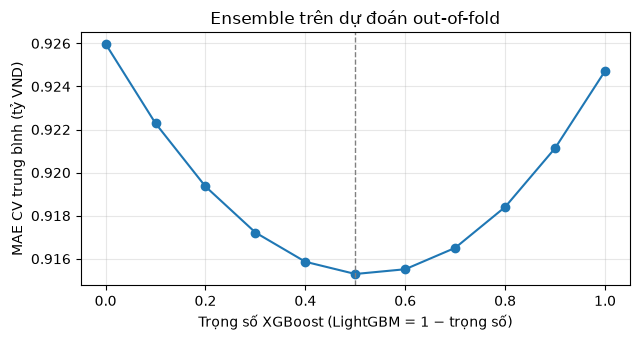

Model đơn tốt nhất theo CV: XGBoost
Dùng ensemble: True


In [31]:
# C63 — Ensemble trung bình có trọng số từ dự đoán out-of-fold (không train)
assert "final_cv_candidates" in globals(), "Chạy C62 trước."

ENSEMBLE_DIR = EXPERIMENT_DIR / "ensemble_oof"
ENSEMBLE_DIR.mkdir(parents=True, exist_ok=True)

oof_predictions = {}
for model_name, candidate in final_cv_candidates.items():
    frame = load_oof_predictions(candidate["group"], candidate["result_name"])
    # Dự đoán đọc từ file phải tái tạo MAE từng fold đã lưu.
    saved_mae = candidate["folds"].set_index("fold")["cv_MAE"]
    for fold, part in frame.groupby("fold"):
        recomputed = mean_absolute_error(part["actual_price"], part["predicted_price"])
        assert np.isclose(recomputed, saved_mae.loc[fold], atol=1e-5), (model_name, fold)
    oof_predictions[model_name] = frame

xgb_oof = oof_predictions["XGBoost"]
lgb_oof = oof_predictions["LightGBM"]
assert xgb_oof["row_id"].equals(lgb_oof["row_id"])
assert xgb_oof["fold"].equals(lgb_oof["fold"])

ENSEMBLE_WEIGHTS = np.round(np.linspace(0, 1, 11), 2)  # trọng số của XGBoost
blend_rows = []
for weight in ENSEMBLE_WEIGHTS:
    blended = (
        weight * xgb_oof["predicted_price"]
        + (1 - weight) * lgb_oof["predicted_price"]
    )
    for fold in range(1, len(rf_cv_splits) + 1):
        mask = xgb_oof["fold"].eq(fold)
        metrics = evaluate(xgb_oof.loc[mask, "actual_price"], blended[mask])
        blend_rows.append({
            "xgb_weight": weight,
            "fold": fold,
            "cv_MAE": metrics["MAE"],
            "cv_RMSE": metrics["RMSE"],
            "cv_R2": metrics["R2"],
        })

blend_folds = pd.DataFrame(blend_rows)
blend_summary = blend_folds.groupby("xgb_weight", as_index=False).agg(
    mean_cv_MAE=("cv_MAE", "mean"),
    std_cv_MAE=("cv_MAE", lambda x: x.std(ddof=0)),
    mean_cv_RMSE=("cv_RMSE", "mean"),
    mean_cv_R2=("cv_R2", "mean"),
)
display(blend_summary.round(6))


def blend_at(weight):
    return blend_folds.loc[np.isclose(blend_folds["xgb_weight"], weight)]


best_single = min(
    final_cv_candidates,
    key=lambda name: final_cv_candidates[name]["folds"]["cv_MAE"].mean(),
)
single_weight = 1.0 if best_single == "XGBoost" else 0.0
ensemble_weight = float(
    blend_summary.sort_values(["mean_cv_MAE", "xgb_weight"]).iloc[0]["xgb_weight"]
)
ensemble_comparison = paired_comparison(blend_at(single_weight), blend_at(ensemble_weight))
equal_comparison = paired_comparison(blend_at(single_weight), blend_at(0.5))
use_ensemble = (
    0 < ensemble_weight < 1
    and ensemble_comparison["MAE_reduction"] > 0
    and ensemble_comparison["folds_won"] >= MIN_FOLDS_WON
)

display(pd.DataFrame([
    {"comparison": f"w={ensemble_weight:.1f} so với {best_single}", **ensemble_comparison},
    {"comparison": f"w=0.5 so với {best_single}", **equal_comparison},
]).round(6))

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(blend_summary["xgb_weight"], blend_summary["mean_cv_MAE"], marker="o")
ax.axvline(ensemble_weight, linestyle="--", linewidth=1, color="grey")
ax.set_xlabel("Trọng số XGBoost (LightGBM = 1 − trọng số)")
ax.set_ylabel("MAE CV trung bình (tỷ VND)")
ax.set_title("Ensemble trên dự đoán out-of-fold")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

blend_summary.to_csv(ENSEMBLE_DIR / "blend_summary.csv", index=False)
print("Model đơn tốt nhất theo CV:", best_single)
print("Dùng ensemble:", use_ensemble)

## 19. Fit trên toàn bộ train, kiểm tra trên validation và giải thích model

Fit hai model cuối trên toàn bộ train bằng đúng quy trình trong fold: chọn số cây trên 15% train, rồi refit trên toàn bộ train. Validation chỉ dùng để đối chiếu lựa chọn từ CV, không dùng để early stopping hay chọn tham số. Validation đã được dùng cho các lựa chọn thô ở C04–C21 (chuẩn hóa địa phương, mean imputation), nên không độc lập hoàn toàn. Calibration và test vẫn chưa mở.

Kết quả validation ở C19–C21 dùng chính validation để early stopping nên lạc quan; chỉ dùng để tham khảo, không so sánh ngang hàng.

C65 giải thích model đã chọn trên validation bằng hai cách:
- Permutation importance theo các cột đầu vào (12 cột gốc và cột lấy từ Address nếu có): MAE tăng bao nhiêu khi xáo trộn một cột.
- SHAP (TreeSHAP có sẵn trong XGBoost/LightGBM) gộp theo cột trước One-Hot. Với ensemble, SHAP là tổng có trọng số của hai model.

In [32]:
# C64 — Fit cấu hình cuối trên toàn bộ train, kiểm tra trên validation
assert "use_ensemble" in globals(), "Chạy C63 trước."

FINAL_DIR = EXPERIMENT_DIR / "final_selection"
FINAL_DIR.mkdir(parents=True, exist_ok=True)

final_pipelines = {}
final_trees = {}
for model_name, candidate in final_cv_candidates.items():
    start = perf_counter()
    pipeline, trees, rounds_run = fit_with_inner_stopping(
        candidate["family"],
        candidate["params"],
        candidate.get("make", make_preprocessing)(candidate["blocks"]),
        X_train,
        y_train,
        candidate.get("target_transform"),
    )
    final_pipelines[model_name] = pipeline
    final_trees[model_name] = trees
    print(
        f"{model_name}: chọn {trees} cây sau {rounds_run} vòng; "
        f"fit {perf_counter() - start:.0f} giây"
    )

ensemble_name = f"Ensemble_w{ensemble_weight:.1f}"
val_predictions = {
    name: pipeline.predict(X_val) for name, pipeline in final_pipelines.items()
}
val_predictions[ensemble_name] = (
    ensemble_weight * val_predictions["XGBoost"]
    + (1 - ensemble_weight) * val_predictions["LightGBM"]
)

cv_mae_lookup = {
    name: candidate["folds"]["cv_MAE"].mean()
    for name, candidate in final_cv_candidates.items()
}
cv_mae_lookup[ensemble_name] = blend_at(ensemble_weight)["cv_MAE"].mean()

final_validation = pd.DataFrame([
    {
        "model": name,
        "cv_MAE": cv_mae_lookup[name],
        **{f"val_{key}": value for key, value in evaluate(y_val, prediction).items()},
    }
    for name, prediction in val_predictions.items()
]).sort_values("val_MAE").reset_index(drop=True)
display(final_validation.round(6))

final_choice = ensemble_name if use_ensemble else best_single
final_weights = (
    {"XGBoost": ensemble_weight, "LightGBM": 1 - ensemble_weight}
    if use_ensemble else {best_single: 1.0}
)
final_val_pred = val_predictions[final_choice]

cv_rank = final_validation.sort_values("cv_MAE")["model"].tolist()
val_rank = final_validation["model"].tolist()
print("Lựa chọn theo CV:", final_choice)
print("Thứ hạng theo CV:        ", cv_rank)
print("Thứ hạng theo validation:", val_rank)
print("Validation đồng ý với CV ở vị trí dẫn đầu:", cv_rank[0] == val_rank[0])

if "final_model_summary" in globals():
    print("\nTham khảo C21 (boosting dùng validation để early stopping nên lạc quan):")
    display(
        final_model_summary.loc[
            final_model_summary["model"].isin([
                "XGBoost_initial", "LightGBM_initial",
                "CatBoost_max3000", "RF_scaled_mean",
            ]),
            ["model", "val_MAE", "val_RMSE", "val_R2"],
        ].round(6)
    )

# Lỗi theo nhóm giá thật, cùng ngưỡng C07 và C56.
final_errors = val_df[["row_id", "City", "District", "Area"]].copy()
final_errors["actual_price"] = y_val.to_numpy()
final_errors["predicted_price"] = final_val_pred
final_errors["error"] = final_errors["predicted_price"] - final_errors["actual_price"]
final_errors["abs_error"] = final_errors["error"].abs()
final_errors["price_group"] = pd.cut(
    final_errors["actual_price"],
    bins=[-float("inf"), 3, 5, 7, 9, float("inf")],
    labels=["<3", "3–<5", "5–<7", "7–<9", "≥9"],
    right=False,
)
price_group_errors = (
    final_errors.groupby("price_group", observed=True)
    .agg(
        n=("abs_error", "size"),
        mean_actual_price=("actual_price", "mean"),
        MAE=("abs_error", "mean"),
        bias=("error", "mean"),
    )
    .reset_index()
)
print(f"\nLỗi validation theo nhóm giá thật — {final_choice} (bias = dự đoán − thật):")
display(price_group_errors.round(4))

# Tin đăng trùng giữa validation và train (cùng Address, Area, Price): dễ đoán hơn.
def listing_keys(frame, prices):
    addresses = (
        raw_df["Address"].iloc[frame["row_id"].to_numpy()]
        .fillna("NA").astype(str).reset_index(drop=True)
    )
    return (
        addresses + " | " + frame["Area"].astype(str).reset_index(drop=True)
        + " | " + prices.astype(str).reset_index(drop=True)
    )


if "raw_df" in globals():
    val_twin = listing_keys(val_df, y_val).isin(set(listing_keys(train_df, y_train))).to_numpy()
    val_abs_error = np.abs(final_val_pred - y_val.to_numpy())
    print(
        f"Validation có bản trùng trong train: {val_twin.mean():.1%}; "
        f"MAE dòng có bản trùng = {val_abs_error[val_twin].mean():.4f}, "
        f"không có = {val_abs_error[~val_twin].mean():.4f} tỷ VND."
    )

pd.DataFrame({
    "row_id": val_df["row_id"].to_numpy(),
    "actual_price": y_val.to_numpy(),
    **{f"pred_{name}": prediction for name, prediction in val_predictions.items()},
}).to_csv(
    FINAL_DIR / "validation_predictions.csv.gz",
    index=False, compression="gzip", float_format="%.6f",
)

XGBoost: chọn 1057 cây sau 1157 vòng; fit 25 giây


LightGBM: chọn 859 cây sau 959 vòng; fit 34 giây


,model,cv_MAE,val_MAE,val_RMSE,val_R2
0,Ensemble_w0.5,0.915293,0.880207,1.209953,0.694722
1,XGBoost,0.924716,0.885901,1.218976,0.690152
2,LightGBM,0.925978,0.893023,1.225211,0.686974


Lựa chọn theo CV: Ensemble_w0.5
Thứ hạng theo CV:         ['Ensemble_w0.5', 'XGBoost', 'LightGBM']
Thứ hạng theo validation: ['Ensemble_w0.5', 'XGBoost', 'LightGBM']
Validation đồng ý với CV ở vị trí dẫn đầu: True

Lỗi validation theo nhóm giá thật — Ensemble_w0.5 (bias = dự đoán − thật):


,price_group,n,mean_actual_price,MAE,bias
0,<3,494,2.2270,0.9046,0.8079
1,3–<5,1126,4.0619,0.7902,0.5295
2,5–<7,1439,6.0054,0.7352,0.2149
3,7–<9,1045,7.9231,0.8703,-0.5812
4,≥9,431,9.5120,1.5954,-1.5828


Validation có bản trùng trong train: 10.5%; MAE dòng có bản trùng = 0.5341, không có = 0.9209 tỷ VND.


Model: Ensemble_w0.5; MAE validation = 0.880207 tỷ VND


,feature,MAE_increase,MAE_increase_std
0,Area,0.6754,0.0100
1,District,0.4874,0.0074
2,City,0.4803,0.0086
3,Floors,0.1779,0.0067
4,Ward,0.1487,0.0012
5,Access Road,0.1163,0.0050
6,Bathrooms,0.0630,0.0043
7,Street,0.0378,0.0009
8,Project,0.0352,0.0017
9,Bedrooms,0.0257,0.0029


,feature,mean_abs_SHAP
0,Area,0.7127
1,City_District_Ward,0.5240
2,City,0.3367
3,District,0.3163
4,Floors,0.3110
5,Access Road,0.2322
6,Bathrooms,0.2246
7,City_District_Street,0.2063
8,Bedrooms,0.1397
9,City_Project,0.0678


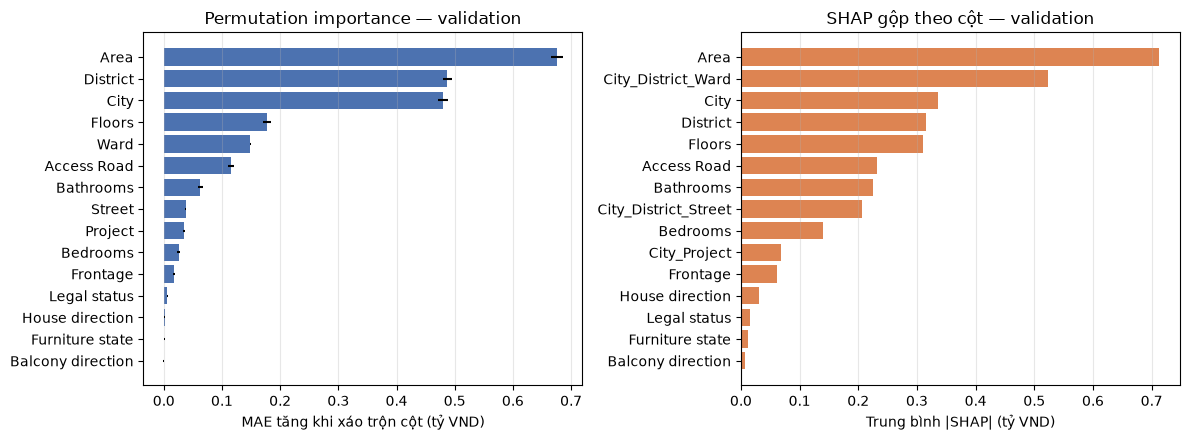

In [33]:
# C65 — Giải thích model đã chọn trên validation
assert "final_weights" in globals(), "Chạy C64 trước."


def predict_final(X):
    return sum(
        weight * final_pipelines[name].predict(X)
        for name, weight in final_weights.items()
    )


assert np.allclose(predict_final(X_val), final_val_pred)

# 1. Permutation importance theo các cột đầu vào (12 cột gốc và cột lấy từ Address).
N_REPEATS = 5
permutation_rng = np.random.default_rng(SEED)
reference_mae = mean_absolute_error(y_val, final_val_pred)
permutation_rows = []
for feature in X_val.columns:
    increases = []
    for _ in range(N_REPEATS):
        permuted = X_val.copy()
        permuted[feature] = permutation_rng.permutation(permuted[feature].to_numpy())
        increases.append(
            mean_absolute_error(y_val, predict_final(permuted)) - reference_mae
        )
    permutation_rows.append({
        "feature": feature,
        "MAE_increase": np.mean(increases),
        "MAE_increase_std": np.std(increases),
    })
permutation_table = (
    pd.DataFrame(permutation_rows)
    .sort_values("MAE_increase", ascending=False)
    .reset_index(drop=True)
)


# 2. SHAP gộp theo cột trước One-Hot.
def output_feature_sources(preprocessing):
    """Tên cột (trước encoding) tương ứng với từng cột đầu ra của preprocessing."""
    sources = []
    for name, transformer, columns in preprocessing.named_steps["columns"].transformers_:
        if transformer == "drop" or len(columns) == 0:
            continue
        if name == "cat":
            encoder = transformer.named_steps["onehot"]
            for column, categories in zip(columns, encoder.categories_):
                sources.extend([column] * len(categories))
        else:
            # Cột chỉ báo thiếu được gộp vào cột gốc của nó.
            sources.extend(
                str(feature).replace("missingindicator_", "")
                for feature in transformer.get_feature_names_out(columns)
            )
    return sources


shap_by_model = {}
if any(isinstance(final_pipelines[name], LogTargetModel) for name in final_weights):
    print("Có thành phần train trên log(Price): SHAP tính trên thang log, không cộng được với thang giá gốc.")
for model_name, weight in final_weights.items():
    pipeline = final_pipelines[model_name]
    if isinstance(pipeline, LogTargetModel):
        pipeline = pipeline.pipeline
    preprocessing = pipeline.named_steps["preprocessing"]
    model = pipeline.named_steps["model"]
    # Giữ đúng định dạng ma trận lúc train (XGBoost coi ô rỗng của sparse là thiếu).
    matrix = preprocessing.transform(X_val)
    sources = output_feature_sources(preprocessing)
    assert len(sources) == matrix.shape[1]

    if model_name == "XGBoost":
        contributions = model.get_booster().predict(
            xgboost.DMatrix(matrix), pred_contribs=True
        )
    else:
        contributions = model.booster_.predict(matrix, pred_contrib=True)
    contributions = to_dense(contributions)
    assert contributions.shape[1] == matrix.shape[1] + 1
    # Tổng đóng góp + bias phải bằng dự đoán của model.
    assert np.allclose(contributions.sum(axis=1), model.predict(matrix), atol=1e-3)

    shap_by_model[model_name] = weight * (
        pd.DataFrame(contributions[:, :-1], columns=sources)
        .T.groupby(level=0).sum().T
    )

shap_values = sum(shap_by_model.values()).fillna(0.0)
shap_table = (
    shap_values.abs().mean()
    .sort_values(ascending=False)
    .rename("mean_abs_SHAP").reset_index()
    .rename(columns={"index": "feature"})
)

print(f"Model: {final_choice}; MAE validation = {reference_mae:.6f} tỷ VND")
display(permutation_table.round(4))
display(shap_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
permutation_plot = permutation_table.sort_values("MAE_increase")
axes[0].barh(
    permutation_plot["feature"], permutation_plot["MAE_increase"],
    xerr=permutation_plot["MAE_increase_std"], color="#4C72B0",
)
axes[0].set_xlabel("MAE tăng khi xáo trộn cột (tỷ VND)")
axes[0].set_title("Permutation importance — validation")
shap_plot = shap_table.sort_values("mean_abs_SHAP")
axes[1].barh(shap_plot["feature"], shap_plot["mean_abs_SHAP"], color="#DD8452")
axes[1].set_xlabel("Trung bình |SHAP| (tỷ VND)")
axes[1].set_title("SHAP gộp theo cột — validation")
for ax in axes:
    ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

permutation_table.to_csv(FINAL_DIR / "permutation_importance.csv", index=False)
shap_table.to_csv(FINAL_DIR / "shap_importance.csv", index=False)

In [34]:
# C66 — Lưu lựa chọn cho notebook 04 (không lưu model)
assert "final_choice" in globals(), "Chạy C64 trước."

final_metrics = final_validation.set_index("model").loc[final_choice]
components = []
for model_name, weight in final_weights.items():
    candidate = final_cv_candidates[model_name]
    components.append({
        "model": model_name,
        "family": candidate["family"],
        "weight": float(weight),
        "params": candidate["params"],
        "n_estimators_full_train": int(final_trees[model_name]),
        "preprocessing": candidate.get("describe", describe_preprocessing)(candidate["blocks"]),
        "target_transform": candidate.get("target_transform"),
        "cv_experiment": f"experiments/{candidate['group']}/{candidate['result_name']}",
        "cv_MAE": float(cv_mae_lookup[model_name]),
    })

selection_manifest = {
    "status": "selected_by_cv_checked_on_validation",
    "source": "notebooks/03_model_experiments.ipynb, C51",
    "final_choice": final_choice,
    "components": components,
    "features": list(X_train.columns),
    "target": f"{TARGET} (tỷ VND)",
    "selection_protocol": {
        "cv": {"n_splits": 3, "shuffle": True, "random_state": 42},
        "inner_split": INNER_SPLIT,
        "early_stopping_rounds": EARLY_STOPPING_ROUNDS,
        "metric": "MAE CV trung bình",
        "change_rule": (
            f"MAE giảm, thắng >= {MIN_FOLDS_WON}/3 fold, qua 3 seed nếu model lấy mẫu "
            "ngẫu nhiên, và R² CV không giảm"
        ),
    },
    "cv_metrics": {"MAE": float(cv_mae_lookup[final_choice])},
    "validation_metrics": {
        key: float(final_metrics[f"val_{key}"]) for key in ["MAE", "RMSE", "R2"]
    },
    "data": {
        "split_dir": f"data/processed/{SPLIT_DIR.name}",
        **{f"{name}_sha256": value for name, value in split_fingerprints.items()},
    },
    "versions": environment_versions,
    "left_for_notebook_04": [
        "refit cấu hình này (cân nhắc train + validation)",
        "calibration khoảng dự đoán trên calibration",
        "đánh giá một lần trên test",
        "lưu/nạp artifact và inference cho app",
    ],
}
write_json_atomic(FINAL_DIR / "selection_manifest.json", selection_manifest)

display(pd.DataFrame([
    {
        "component": c["model"],
        "weight": c["weight"],
        "feature_blocks": "+".join(c["preprocessing"]["blocks"]) or "base",
        "n_estimators_full_train": c["n_estimators_full_train"],
        "cv_MAE": c["cv_MAE"],
    }
    for c in components
]).round(6))
print("Lựa chọn cuối:", final_choice)
print(
    f"MAE CV = {cv_mae_lookup[final_choice]:.6f}; "
    f"validation MAE = {final_metrics['val_MAE']:.6f}, "
    f"RMSE = {final_metrics['val_RMSE']:.6f}, R² = {final_metrics['val_R2']:.6f}"
)
print("Đã lưu:", (FINAL_DIR / "selection_manifest.json").relative_to(PROJECT_ROOT))
print("Không lưu model; notebook 04 refit, calibration và đánh giá test.")

,component,weight,feature_blocks,n_estimators_full_train,cv_MAE
0,XGBoost,0.5,project_te+street_te+ward_te,1057,0.924716
1,LightGBM,0.5,fa_native+project_te+street_te+ward_te,859,0.925978


Lựa chọn cuối: Ensemble_w0.5
MAE CV = 0.915293; validation MAE = 0.880207, RMSE = 1.209953, R² = 0.694722
Đã lưu: experiments\final_selection\selection_manifest.json
Không lưu model; notebook 04 refit, calibration và đánh giá test.


## 20. Kết luận và bàn giao notebook 04

**Cấu hình chọn (C66):** trung bình **0,5 × XGBoost + 0,5 × LightGBM** trên `splits_v2`; cả hai dùng Target Encoding của **phường, đường và dự án** lấy từ Address.

| Thành phần | Tiền xử lý | Tham số chính | Số cây (toàn bộ train) |
|---|---|---|---|
| XGBoost | Frontage/Access Road: median học trong fold; One-Hot 6 cột phân loại; TE phường, đường, dự án | `max_depth=9`, `min_child_weight=1`, `subsample=0.8`, `colsample_bytree=0.7`, `learning_rate=0.05` | 1.057 |
| LightGBM | Frontage/Access Road: để model tự xử lý; One-Hot; TE phường, đường, dự án | `num_leaves=63`, `min_child_samples=5`, `colsample_bytree=0.7`, `learning_rate=0.05` | 859 |

**Kết quả** (MAE/RMSE: tỷ VND):

| | MAE | RMSE | R² |
|---|---|---|---|
| CV — XGBoost lượt 1 trên v1 (mốc góp ý) | 0,9855 | 1,3224 | 0,643 |
| CV — XGBoost trên v2, chưa có địa chỉ chi tiết (C55) | 0,9828 | 1,3246 | 0,642 |
| CV — XGBoost + phường + dự án (C59) | 0,9296 | 1,2609 | 0,676 |
| CV — XGBoost + phường + dự án + đường (C59a) | 0,9247 | 1,2562 | 0,678 |
| CV — **Ensemble 0,5/0,5** | **0,9153** | **1,2429** | **0,685** |
| Validation — Ensemble (fit toàn bộ train) | 0,8802 | 1,2100 | 0,695 |
| **Test — Ensemble (C67, một lần)** | **0,8917** | **1,2188** | **0,699** |

- **Nguồn cải thiện chính:** thông tin vị trí chi tiết lấy lại từ Address, chủ yếu là phường (khoảng +0,03 R²). Dự án, đường và ensemble cộng thêm khoảng +0,01. Các thay đổi khác (xử lý missing, tuning lượt 2, log-price, feature số dẫn xuất) gần như không đổi hoặc bị loại.
- **CV và validation đồng ý** về thứ tự: Ensemble > XGBoost > LightGBM. Validation tốt hơn CV một phần vì 10,5% dòng validation có tin trùng trong train (MAE 0,53). Trên dòng không trùng, MAE validation là 0,92, gần với CV.
- **Tiêu chí nghiệm thu chưa đạt.** Notebook 01 đặt mục tiêu R² test ≥ 0,7. Test (C67, chấm một lần) cho R² = 0,6986, thiếu 0,0014. Không tính 10,7% dòng test có tin trùng trong train thì R² = 0,677.
- **Quan trọng nhất (C65):** Area, vị trí (City, District, phường) và số tầng. Hướng nhà, hướng ban công và nội thất gần như không đóng góp.
- **Lỗi còn lại:** vẫn co về trung bình ở hai đầu giá. Trên validation, nhà dưới 3 tỷ bị đoán cao +0,81 tỷ, nhà từ 9 tỷ bị đoán thấp −1,58 tỷ. Một phần lỗi lớn đến từ dữ liệu: nhãn mâu thuẫn, giá nghi sai đơn vị (C57a).

**Việc cần nhóm quyết định trước hoặc trong notebook 04:**
1. **Tin đăng trùng:** khoảng 11% dòng train trùng Address, Area, Price với dòng khác; validation/test chia ngẫu nhiên nên cũng có bản trùng trong train. Điểm hiện tại hơi lạc quan, nhất là với feature đường. Cân nhắc chia theo nhóm (GroupKFold theo tin) hoặc gộp tin trùng; đây là quyết định về dữ liệu, không nên xóa theo sai số của model.
2. **Dữ liệu nghi sai:** 238 dòng có dấu hiệu bất thường (C57a), trong đó có lỗi đơn vị gần như chắc chắn (Area = 4 m²). Cần nhóm dữ liệu kiểm tra nguồn trước khi quyết định sửa hay giữ.
3. **Đầu vào của app:** cấu hình chọn cần phường/xã, tên đường và tên dự án (tùy chọn). App hiện chỉ có City/District. Nếu không bổ sung, dùng cấu hình C55; MAE CV khoảng 0,98 thay vì 0,92.
4. **Quy tắc chọn model:** MAE quyết định, kèm R² không giảm (C60–C61); nhóm cần xác nhận.
5. **Chuẩn hóa tên địa phương** ("TP. HCM", "quận Tân Bình", "Thành phố Phan Thiết"…): ảnh hưởng khoảng 160 dòng train, nhưng các dòng này có MAE cao.

Notebook 01 và `cleandata_estate_aiqs.ipynb` đã có ghi chú đính chính về việc điền missing trước khi chia tập.

**Bàn giao notebook 04:** đọc `experiments/final_selection/selection_manifest.json` (tham số, tiền xử lý, số cây, trọng số, phiên bản thư viện, hash dữ liệu). Notebook 04 sẽ:
1. Refit, cân nhắc dùng train + validation.
2. Calibration khoảng dự đoán trên tập calibration, kiểm tra riêng theo nhóm giá vì lỗi không đều.
3. Test đã chấm ở C67; không chấm lại cho cấu hình này.
4. Lưu/nạp artifact cho app.

Model đã khóa được xuất ở C68 (`models/candidates/final_v2_2026-10-20/house_price_ensemble.pkl`). Test đã chấm một lần ở C67, nên notebook 04 tập trung vào calibration khoảng dự đoán, lưu artifact chính thức và tích hợp app.

## 21. Đánh giá test chính thức — một lần

Ngày 2026-10-20, nhóm quyết định xem R² test ngay với cấu hình đã chốt ở C66, thay vì chờ notebook 04. Vì vậy:

- C67 dùng chính hai pipeline đã fit trên **train** ở C64 (không fit lại, không đổi tham số, feature hay trọng số) và chỉ dự đoán trên `splits_v2/test.csv`.
- Kết quả là **đánh giá test chính thức của cấu hình này**. Từ đây cấu hình được **khóa**: mọi thay đổi sau này phải chọn bằng CV, và báo cáo phải ghi rõ là test đã được xem trước.
- C67 ghi kết quả vào `experiments/final_selection/test_evaluation.json`. Chạy lại cell chỉ kiểm tra kết quả trùng với lần đầu, không ghi đè.
- Calibration chưa dùng; vẫn để dành cho notebook 04.

In [35]:
# C67 — Đánh giá test chính thức, một lần (cấu hình C66 đã chốt, model fit trên train)
assert "final_pipelines" in globals() and "predict_final" in globals(), "Chạy C64–C65 trước."

TEST_RESULT_PATH = FINAL_DIR / "test_evaluation.json"
selection_bytes = (FINAL_DIR / "selection_manifest.json").read_bytes()
locked_selection = json.loads(selection_bytes)
assert locked_selection["final_choice"] == final_choice
assert {c["model"]: c["weight"] for c in locked_selection["components"]} == {
    name: float(weight) for name, weight in final_weights.items()
}

test_df = pd.read_csv(SPLIT_DIR / "test.csv")
assert test_df["row_id"].is_unique
assert set(test_df["row_id"]).isdisjoint(train_df["row_id"])
assert set(test_df["row_id"]).isdisjoint(val_df["row_id"])
X_test = test_df[FEATURES].join(address_frame(test_df))
y_test = test_df[TARGET].copy()

test_predictions = {name: pipeline.predict(X_test) for name, pipeline in final_pipelines.items()}
test_predictions[final_choice] = predict_final(X_test)

# Tin đăng trùng với train (cùng Address, Area, Price), đo như C57/C64.
test_twin = listing_keys(test_df, y_test).isin(set(listing_keys(train_df, y_train))).to_numpy()

rows = []
for name, prediction in test_predictions.items():
    rows.append({
        "model": name,
        **{f"test_{k}": v for k, v in evaluate(y_test, prediction).items()},
        **{f"test_no_twin_{k}": v for k, v in evaluate(y_test[~test_twin], prediction[~test_twin]).items()},
    })
test_results = pd.DataFrame(rows).set_index("model")
display(test_results.round(6))

final_test = test_results.loc[final_choice]
final_validation_row = final_validation.set_index("model").loc[final_choice]
print(f"Cấu hình: {final_choice}; {len(y_test)} dòng test.")
print(
    f"Test:       MAE = {final_test['test_MAE']:.4f}, RMSE = {final_test['test_RMSE']:.4f}, "
    f"R² = {final_test['test_R2']:.4f}"
)
print(
    f"Validation: MAE = {final_validation_row['val_MAE']:.4f}, RMSE = {final_validation_row['val_RMSE']:.4f}, "
    f"R² = {final_validation_row['val_R2']:.4f}"
)
print(f"Tiêu chí nghiệm thu R² test ≥ 0,7: {'ĐẠT' if final_test['test_R2'] >= 0.7 else 'CHƯA ĐẠT'}")
print(
    f"Test có bản trùng trong train: {test_twin.mean():.1%}; "
    f"không tính các dòng này: MAE = {final_test['test_no_twin_MAE']:.4f}, R² = {final_test['test_no_twin_R2']:.4f}."
)

test_errors = pd.DataFrame({
    "actual_price": y_test.to_numpy(),
    "error": test_predictions[final_choice] - y_test.to_numpy(),
})
test_errors["price_group"] = pd.cut(
    test_errors["actual_price"], bins=[-np.inf, 3, 5, 7, 9, np.inf],
    labels=["<3", "3–<5", "5–<7", "7–<9", "≥9"], right=False,
)
print("\nLỗi test theo nhóm giá thật (bias = dự đoán − thật):")
display(
    test_errors.groupby("price_group", observed=True)
    .agg(n=("error", "size"), MAE=("error", lambda e: e.abs().mean()), bias=("error", "mean"))
    .reset_index().round(4)
)

test_record = {
    "status": "official_single_test_evaluation",
    "source": "notebooks/03_model_experiments.ipynb, C67",
    "final_choice": final_choice,
    "selection_manifest_sha256": hashlib.sha256(selection_bytes).hexdigest(),
    "test_sha256": hashlib.sha256((SPLIT_DIR / "test.csv").read_bytes()).hexdigest(),
    "rows": int(len(y_test)),
    "metrics": {k.replace("test_", ""): float(v) for k, v in final_test.items() if not k.startswith("test_no_twin")},
    "metrics_without_twins": {k.replace("test_no_twin_", ""): float(v) for k, v in final_test.items() if k.startswith("test_no_twin")},
    "twin_share": float(test_twin.mean()),
    "components": {
        name: {k.replace("test_", ""): float(v) for k, v in test_results.loc[name].items() if not k.startswith("test_no_twin")}
        for name in final_pipelines
    },
    "acceptance_R2_at_least_0_7": bool(final_test["test_R2"] >= 0.7),
}
if TEST_RESULT_PATH.exists():
    # Không đánh giá lại: kết quả chạy lại phải trùng lần đầu.
    first = json.loads(TEST_RESULT_PATH.read_text(encoding="utf-8"))
    assert first["selection_manifest_sha256"] == test_record["selection_manifest_sha256"], (
        "Cấu hình đã thay đổi sau khi xem test; không ghi đè kết quả test chính thức."
    )
    assert all(np.isclose(first["metrics"][k], test_record["metrics"][k]) for k in first["metrics"])
    print("\nĐã có kết quả test chính thức; lần chạy này trùng khớp, không ghi đè.")
else:
    write_json_atomic(TEST_RESULT_PATH, test_record)
    print("\nĐã lưu:", TEST_RESULT_PATH.relative_to(PROJECT_ROOT))

,test_MAE,test_RMSE,test_R2,test_no_twin_MAE,test_no_twin_RMSE,test_no_twin_R2
model,,,,,,
XGBoost,0.896717,1.229452,0.693303,0.939557,1.276943,0.671421
LightGBM,0.905192,1.230542,0.692760,0.947554,1.277475,0.671147
Ensemble_w0.5,0.891668,1.218780,0.698605,0.934313,1.265862,0.677099


Cấu hình: Ensemble_w0.5; 4535 dòng test.
Test:       MAE = 0.8917, RMSE = 1.2188, R² = 0.6986
Validation: MAE = 0.8802, RMSE = 1.2100, R² = 0.6947
Tiêu chí nghiệm thu R² test ≥ 0,7: CHƯA ĐẠT
Test có bản trùng trong train: 10.7%; không tính các dòng này: MAE = 0.9343, R² = 0.6771.

Lỗi test theo nhóm giá thật (bias = dự đoán − thật):


,price_group,n,MAE,bias
0,<3,506,0.9055,0.7909
1,3–<5,1168,0.8097,0.5821
2,5–<7,1365,0.7156,0.1986
3,7–<9,1038,0.8578,-0.5730
4,≥9,458,1.6867,-1.6623



Đã có kết quả test chính thức; lần chạy này trùng khớp, không ghi đè.


### Kết quả test

| | MAE | RMSE | R² |
|---|---|---|---|
| **Ensemble 0,5/0,5 — test** | **0,8917** | **1,2188** | **0,6986** |
| XGBoost — test | 0,8967 | 1,2295 | 0,6933 |
| LightGBM — test | 0,9052 | 1,2305 | 0,6928 |
| Ensemble — validation (C64) | 0,8802 | 1,2100 | 0,6947 |
| Ensemble — test, không tính 10,7% dòng có tin trùng trong train | 0,9343 | 1,2659 | 0,6771 |

- **Tiêu chí nghiệm thu R² test ≥ 0,7: chưa đạt**, thiếu 0,0014.
- Test rất sát validation (R² 0,699 so với 0,695), nên quy trình chọn bằng CV và kiểm tra trên validation là đáng tin.
- Ensemble tốt hơn từng model trên test, giống thứ tự ở CV và validation.
- Lỗi theo nhóm giá trên test lặp lại đúng hướng ở CV/validation: nhà dưới 3 tỷ bị đoán cao +0,79 tỷ, nhà từ 9 tỷ bị đoán thấp −1,66 tỷ.
- Trên các dòng không có tin trùng, R² là 0,677; đây là mức gần nhất với một tin đăng mới hoàn toàn.

Cấu hình đã khóa. Muốn vượt 0,7, nhóm cần thay đổi mới (dữ liệu, vị trí chi tiết hơn, cách đánh giá tin trùng), chọn bằng CV, và báo cáo rõ là test đã được xem trước.

## 22. Xuất model đã khóa

C68 lưu ensemble của C64 (fit trên train, đúng cấu hình đã chấm test ở C67) thành một file `.pkl`, kèm manifest, README và danh sách phiên bản thư viện, trong `models/candidates/final_v2_2026-10-20/`. File được ghi bằng `cloudpickle`, vì pipeline dùng các hàm định nghĩa trong notebook (chuẩn hóa địa phương, tách phường/đường/dự án từ Address); `pickle` thường không nạp lại được các hàm này bên ngoài notebook. Khi code tiền xử lý được chuyển vào `src/`, nên xuất lại bằng joblib/pickle thường.

Để kiểm tra, C68 nạp lại file trong **một tiến trình Python mới, không có notebook**, dự đoán validation và test, rồi so với dự đoán trong notebook (phải trùng khớp). C68 cũng thử một căn nhập tay có giá trị thiếu, và đo MAE validation khi không có địa chỉ chi tiết — trường hợp app hiện tại chỉ có City/District.

Thư mục này nằm trong `models/candidates/`, không ở ngay `models/`, nên app chưa nhận file này. Chỉ nạp file pickle từ nguồn tin cậy.

In [36]:
# C68 — Xuất model đã khóa ra .pkl và kiểm tra nạp lại trong tiến trình Python mới
assert TEST_RESULT_PATH.exists(), "Chạy C67 trước."

EXPORT_DIR = PROJECT_ROOT / "models" / "candidates" / "final_v2_2026-10-20"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = EXPORT_DIR / "house_price_ensemble.pkl"


class HousePriceEnsemble:
    """Ensemble đã khóa, dự đoán tổng giá (tỷ VND).

    predict() nhận DataFrame có 12 cột trong `features` và cột 'Address'
    (địa chỉ đầy đủ, dạng '[Dự án X,] [Đường Y,] Phường Z, Quận, Tỉnh').
    Không có 'Address' thì dùng sẵn các cột Ward/Project/Street nếu có; thiếu
    hết thì vẫn dự đoán được nhưng kém chính xác hơn.
    """

    def __init__(self, components, weights, features, address_features, metadata):
        self.components = components
        self.weights = weights
        self.features = list(features)
        self.address_features = list(address_features)
        self.metadata = metadata

    def prepare(self, frame):
        frame = pd.DataFrame(frame).copy()
        missing = [column for column in self.features if column not in frame.columns]
        if missing:
            raise ValueError(f"Thiếu cột đầu vào: {missing}")
        # Giá trị thiếu từ form (None) chuyển thành NaN như dữ liệu train.
        for column in NUMERIC_FEATURES:
            frame[column] = pd.to_numeric(frame[column], errors="coerce")
        for column in CATEGORICAL_FEATURES:
            frame[column] = frame[column].where(frame[column].notna(), np.nan)
        if "Address" in frame.columns:
            parsed = pd.DataFrame(
                frame["Address"].map(parse_address).tolist(),
                columns=self.address_features, index=frame.index,
            )
        else:
            parsed = frame.reindex(columns=self.address_features)
        return frame[self.features].join(parsed)

    def predict(self, frame):
        X = self.prepare(frame)
        return sum(
            weight * self.components[name].predict(X)
            for name, weight in self.weights.items()
        )


test_record = json.loads(TEST_RESULT_PATH.read_text(encoding="utf-8"))
library_versions = {
    package: version(package)
    for package in ["numpy", "pandas", "scikit-learn", "scipy", "xgboost", "lightgbm", "cloudpickle"]
}
model_metadata = {
    "name": "AIQS house price ensemble (splits_v2, Phần B notebook 03)",
    "created": "2026-10-20",
    "source": "notebooks/03_model_experiments.ipynb, C64 (fit) và C68 (xuất)",
    "target": "Price — tổng giá, tỷ VND",
    "trained_on": "data/processed/splits_v2/train.csv (18.136 dòng); không dùng validation/calibration/test để fit",
    "weights": {name: float(weight) for name, weight in final_weights.items()},
    "components": {
        name: {
            "params": final_cv_candidates[name]["params"],
            "preprocessing": describe_preprocessing_v2(final_cv_candidates[name]["blocks"]),
            "n_estimators": int(final_trees[name]),
        }
        for name in final_weights
    },
    "metrics": {
        "cv_3fold": {"MAE": float(cv_mae_lookup[final_choice])},
        "validation": {k: float(final_validation.set_index("model").loc[final_choice][f"val_{k}"]) for k in ["MAE", "RMSE", "R2"]},
        "test": test_record["metrics"],
        "test_without_duplicate_listings": test_record["metrics_without_twins"],
    },
    "acceptance_R2_test_at_least_0_7": test_record["acceptance_R2_at_least_0_7"],
    "selection_manifest_sha256": test_record["selection_manifest_sha256"],
    "versions": library_versions,
    "prediction_interval": None,  # Chưa calibration; notebook 04.
}
final_model = HousePriceEnsemble(
    components=final_pipelines,
    weights=final_weights,
    features=FEATURES,
    address_features=ADDRESS_FEATURES,
    metadata=model_metadata,
)

# Model trong notebook phải cho đúng dự đoán đã chấm ở C64/C67.
assert np.allclose(
    final_model.predict(val_df[FEATURES].join(X_val[ADDRESS_FEATURES])),
    val_predictions[final_choice],
)

temporary = MODEL_PATH.with_suffix(".pkl.tmp")
with temporary.open("wb") as handle:
    cloudpickle.dump(final_model, handle)
temporary.replace(MODEL_PATH)
model_sha256 = hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest()

# Nạp lại trong tiến trình mới (không có notebook) và dự đoán từ Address gốc.
check_script = f"""
import json, pickle
import pandas as pd
with open(r"{MODEL_PATH}", "rb") as handle:
    model = pickle.load(handle)
raw = pd.read_csv(r"{RAW_PATH}")
result = {{}}
for name in ["validation", "test"]:
    frame = pd.read_csv(r"{SPLIT_DIR}" + "/" + name + ".csv")
    frame["Address"] = raw["Address"].iloc[frame["row_id"].to_numpy()].to_numpy()
    result[name] = model.predict(frame).tolist()
manual = pd.DataFrame([{{
    "Area": 60, "Frontage": None, "Access Road": None, "House direction": None,
    "Balcony direction": None, "Floors": 4, "Bedrooms": 3, "Bathrooms": None,
    "Legal status": "Have certificate", "Furniture state": None,
    "City": "Hà Nội", "District": "Cầu Giấy",
    "Address": "Đường Trần Thái Tông, Phường Dịch Vọng, Cầu Giấy, Hà Nội",
}}])
result["manual"] = float(model.predict(manual)[0])
result["manual_without_address"] = float(model.predict(manual.drop(columns="Address"))[0])
print("RESULT " + json.dumps(result))
"""
completed = subprocess.run(
    [sys.executable, "-c", check_script],
    capture_output=True, text=True, encoding="utf-8", cwd=str(EXPORT_DIR),
)
assert completed.returncode == 0, completed.stderr[-3000:]
reloaded = json.loads(next(
    line for line in completed.stdout.splitlines() if line.startswith("RESULT ")
)[len("RESULT "):])
assert np.allclose(reloaded["validation"], val_predictions[final_choice], atol=1e-9)
assert np.allclose(reloaded["test"], test_predictions[final_choice], atol=1e-9)
print("Nạp lại trong tiến trình mới: dự đoán validation và test trùng khớp notebook.")
print(f"Căn nhập tay (Cầu Giấy, 60 m², 4 tầng): {reloaded['manual']:.3f} tỷ; "
      f"không có địa chỉ chi tiết: {reloaded['manual_without_address']:.3f} tỷ.")

# App hiện chỉ có City/District: đo trên validation khi không có Ward/Project/Street.
no_detail_pred = final_model.predict(val_df[FEATURES])
no_detail = evaluate(y_val, no_detail_pred)
print(
    f"Validation khi không có địa chỉ chi tiết: MAE = {no_detail['MAE']:.4f}, "
    f"R² = {no_detail['R2']:.4f} (có địa chỉ: MAE = {final_validation.set_index('model').loc[final_choice, 'val_MAE']:.4f})."
)

export_manifest = {
    "file": MODEL_PATH.name,
    "sha256": model_sha256,
    "bytes": MODEL_PATH.stat().st_size,
    "format": "cloudpickle (đọc bằng pickle.load khi đã cài cloudpickle)",
    "class": "HousePriceEnsemble — predict(DataFrame) -> numpy array, tỷ VND",
    "input_columns": FEATURES + ["Address (tùy chọn)"],
    "verified": "nạp lại trong tiến trình Python mới; dự đoán validation và test trùng khớp notebook",
    "validation_without_detailed_address": {k: float(v) for k, v in no_detail.items()},
    **model_metadata,
}
write_json_atomic(EXPORT_DIR / "manifest.json", export_manifest)
(EXPORT_DIR / "requirements-model.txt").write_text(
    "\n".join(f"{package}=={package_version}" for package, package_version in library_versions.items()) + "\n",
    encoding="utf-8",
)
(EXPORT_DIR / "README.md").write_text(f"""# Model cuối — ensemble XGBoost + LightGBM (splits_v2), 2026-10-20

Xuất từ `notebooks/03_model_experiments.ipynb`, C68. Fit trên train của `splits_v2`; đã chấm test một lần (C67).

| | MAE | RMSE | R² |
|---|---|---|---|
| Validation | {model_metadata['metrics']['validation']['MAE']:.4f} | {model_metadata['metrics']['validation']['RMSE']:.4f} | {model_metadata['metrics']['validation']['R2']:.4f} |
| Test | {test_record['metrics']['MAE']:.4f} | {test_record['metrics']['RMSE']:.4f} | {test_record['metrics']['R2']:.4f} |

Tiêu chí R² test ≥ 0,7: {'đạt' if test_record['acceptance_R2_at_least_0_7'] else 'chưa đạt'}. Chưa có khoảng dự đoán (calibration ở notebook 04).

## Nạp và dự đoán

Cài đúng phiên bản trong `requirements-model.txt` (có `cloudpickle`). Chỉ nạp file pickle từ nguồn tin cậy.

```python
import pickle
import pandas as pd

with open("house_price_ensemble.pkl", "rb") as handle:
    model = pickle.load(handle)

house = pd.DataFrame([{{
    "Area": 60, "Frontage": None, "Access Road": None, "House direction": None,
    "Balcony direction": None, "Floors": 4, "Bedrooms": 3, "Bathrooms": None,
    "Legal status": "Have certificate", "Furniture state": None,
    "City": "Hà Nội", "District": "Cầu Giấy",
    "Address": "Đường Trần Thái Tông, Phường Dịch Vọng, Cầu Giấy, Hà Nội",
}}])
price_ty = model.predict(house)[0]   # tổng giá, tỷ VND
print(model.metadata["metrics"])
```

- Cần đủ 12 cột: {', '.join(FEATURES)}. Giá trị không biết để `None`.
- `Address` nên có phường/xã và tên đường (tên dự án nếu có). Model dựa nhiều vào hai thông tin này: trên validation, khi không có địa chỉ chi tiết, MAE là {no_detail['MAE']:.3f} và R² là {no_detail['R2']:.3f} (có địa chỉ: MAE {model_metadata['metrics']['validation']['MAE']:.3f}), **kém hơn cả model không dùng địa chỉ** (notebook 03, C55: MAE CV khoảng 0,98). App chưa có ô nhập địa chỉ thì cần bổ sung ô nhập, hoặc dùng một model riêng không dùng địa chỉ chi tiết.
- `Price` là giá rao trong dữ liệu (1–11,5 tỷ); model không đáng tin ngoài khoảng này.
""", encoding="utf-8")

print("Đã lưu:", [p.name for p in sorted(EXPORT_DIR.iterdir())])
print(f"Kích thước model: {MODEL_PATH.stat().st_size / 1e6:.1f} MB; sha256 = {model_sha256[:16]}…")

Nạp lại trong tiến trình mới: dự đoán validation và test trùng khớp notebook.
Căn nhập tay (Cầu Giấy, 60 m², 4 tầng): 8.650 tỷ; không có địa chỉ chi tiết: 7.990 tỷ.


Validation khi không có địa chỉ chi tiết: MAE = 1.1382, R² = 0.5557 (có địa chỉ: MAE = 0.8802).
Đã lưu: ['house_price_ensemble.pkl', 'manifest.json', 'README.md', 'requirements-model.txt']
Kích thước model: 15.1 MB; sha256 = abcde93a531f507e…


### Nhận xét — model đã xuất

- File `models/candidates/final_v2_2026-10-20/house_price_ensemble.pkl` (15,1 MB), kèm `manifest.json` (sha256, tham số, metric CV/validation/test, phiên bản thư viện), `README.md` và `requirements-model.txt`.
- Nạp lại trong một tiến trình Python mới, không có notebook: dự đoán validation và test **trùng khớp** với notebook.
- **Model cần địa chỉ chi tiết.** Trên validation, khi không có Ward/Street/Project, MAE là 1,138 và R² là 0,556 (có địa chỉ: 0,880 và 0,695). Kết quả này **kém hơn cả model không dùng địa chỉ chi tiết** (C55: MAE CV khoảng 0,98, R² khoảng 0,64). Model đã học dựa nhiều vào phường/đường nên không xử lý tốt trường hợp thiếu. App hiện chỉ có City/District, vì vậy cần một trong hai: bổ sung ô nhập địa chỉ (phường/xã, đường, dự án), hoặc xuất thêm một model riêng theo cấu hình C55 cho trường hợp không có địa chỉ.
- File dùng `cloudpickle`. Khi code tiền xử lý chuyển vào `src/`, nên xuất lại bằng joblib/pickle thường để app import trực tiếp.
- Chưa có khoảng dự đoán; calibration để dành cho notebook 04.